<a href="https://www.kaggle.com/code/lalit7881/indian-cs-student-survival-eda?scriptVersionId=365168688" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/pranavsinghdeveloper/desi-cs-student-survival/semester_records.csv
/kaggle/input/datasets/pranavsinghdeveloper/desi-cs-student-survival/generate_dataset.py
/kaggle/input/datasets/pranavsinghdeveloper/desi-cs-student-survival/CHALLENGES.md
/kaggle/input/datasets/pranavsinghdeveloper/desi-cs-student-survival/DATA_DICTIONARY.md
/kaggle/input/datasets/pranavsinghdeveloper/desi-cs-student-survival/students.csv
/kaggle/input/datasets/pranavsinghdeveloper/desi-cs-student-survival/splits.csv


In [2]:
df = pd.read_csv('/kaggle/input/datasets/pranavsinghdeveloper/desi-cs-student-survival/students.csv')

In [3]:
df.head()

,student_id,age,gender,home_region,home_town_type,branch,college_tier,year_of_study,residence,relationship_status,...,parent_placement_queries_per_week,imposter_syndrome,stress_level,burnout_score,burnout_level,placed,placement_category,offers_received,package_lpa,archetype
0,S00001,20,Male,Central,Small town,Cyber Security,2,1,Hostel,Single,...,1,5.0,5.0,46.7,Medium,NaN,NaN,NaN,NaN,gaming_ghost
1,S00002,20,Male,West,Tier-2 city,AI&ML,2,2,Day scholar,Situationship,...,1,4.0,4.0,50.3,Medium,NaN,NaN,NaN,NaN,hostel_socialite
2,S00003,20,Male,Central,Tier-2 city,ECE (but codes),1,3,Hostel,Single,...,0,5.0,3.0,38.8,Low,NaN,NaN,NaN,NaN,club_netaji
3,S00004,22,Male,South,Tier-2 city,ECE (but codes),3,3,PG / Rented flat,Single,...,1,5.0,4.0,65.7,High,NaN,NaN,NaN,NaN,certificate_collector
4,S00005,18,Female,South,Metro,CSE,3,1,Hostel,Single,...,2,4.0,1.0,15.9,Low,NaN,NaN,NaN,NaN,library_topper


In [4]:
df.tail()

,student_id,age,gender,home_region,home_town_type,branch,college_tier,year_of_study,residence,relationship_status,...,parent_placement_queries_per_week,imposter_syndrome,stress_level,burnout_score,burnout_level,placed,placement_category,offers_received,package_lpa,archetype
9995,S09996,22,Female,East,Tier-2 city,Cyber Security,2,4,Day scholar,Single,...,4,5.0,7.0,67.7,High,Yes,Service Mass Recruiter,2.0,4.25,hostel_socialite
9996,S09997,20,Female,North,Tier-2 city,Data Science,3,2,Day scholar,Committed,...,2,6.0,7.0,59.6,Medium,NaN,NaN,NaN,NaN,backbench_legend
9997,S09998,22,Male,East,Tier-2 city,Cyber Security,2,4,Day scholar,Committed,...,2,7.0,8.0,78.1,High,No,Not Placed,0.0,NaN,backbench_legend
9998,S09999,20,Male,East,Metro,CSE,2,2,Day scholar,Single,...,2,5.0,4.0,46.0,Medium,NaN,NaN,NaN,NaN,leetcode_grinder
9999,S10000,18,Male,East,Village,Data Science,2,1,PG / Rented flat,Committed,...,0,4.0,6.0,47.4,Medium,NaN,NaN,NaN,NaN,hostel_socialite


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 59 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   student_id                         10000 non-null  object 
 1   age                                10000 non-null  int64  
 2   gender                             10000 non-null  object 
 3   home_region                        10000 non-null  object 
 4   home_town_type                     10000 non-null  object 
 5   branch                             10000 non-null  object 
 6   college_tier                       10000 non-null  int64  
 7   year_of_study                      10000 non-null  int64  
 8   residence                          10000 non-null  object 
 9   relationship_status                10000 non-null  object 
 10  tenth_pct                          9827 non-null   float64
 11  twelfth_pct                        9797 non-null   floa

In [6]:
df.describe()

,age,college_tier,year_of_study,tenth_pct,twelfth_pct,entrance_percentile,attendance_pct,bunked_classes_per_month,proxy_attendance_count,study_hours_daily,...,linkedin_connections,communication_skill,genai_prompts_per_day,stackoverflow_copy_paste_index,parent_placement_queries_per_week,imposter_syndrome,stress_level,burnout_score,offers_received,package_lpa
count,10000.000000,10000.000000,10000.000000,9827.000000,9797.000000,10000.000000,10000.00000,10000.000000,10000.000000,9708.000000,...,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,2315.000000,1357.000000
mean,20.288800,2.352000,2.443800,81.106960,79.530734,72.598217,69.53137,13.721800,1.667200,2.022023,...,220.685000,5.653400,7.873500,4.939200,2.488100,5.002400,4.667400,53.019720,0.896328,7.789440
std,1.448311,0.726601,1.113358,6.487907,8.358239,14.291762,13.13444,6.200181,2.076843,1.380046,...,263.938352,1.875319,4.008354,1.737989,2.172034,1.607312,1.706478,14.041436,0.911162,8.158303
min,18.000000,1.000000,1.000000,57.300000,50.000000,29.390000,30.00000,0.000000,0.000000,0.000000,...,5.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,4.200000,0.000000,2.400000
25%,20.000000,2.000000,1.000000,76.700000,73.900000,62.515000,60.30000,9.000000,0.000000,0.900000,...,73.000000,4.000000,5.000000,4.000000,1.000000,4.000000,4.000000,43.600000,0.000000,3.540000
50%,20.000000,3.000000,2.000000,81.000000,79.600000,72.285000,69.40000,14.000000,1.000000,1.900000,...,141.000000,6.000000,7.000000,5.000000,2.000000,5.000000,5.000000,52.800000,1.000000,4.340000
75%,22.000000,3.000000,3.000000,85.600000,85.200000,82.820000,78.80000,18.000000,2.000000,3.000000,...,273.000000,7.000000,10.000000,6.000000,4.000000,6.000000,6.000000,62.300000,1.000000,8.490000
max,24.000000,3.000000,4.000000,99.600000,99.500000,99.990000,100.00000,33.000000,16.000000,7.300000,...,6516.000000,10.000000,27.000000,10.000000,14.000000,10.000000,10.000000,100.000000,5.000000,63.210000


In [7]:
df.isnull().sum()

student_id                              0
age                                     0
gender                                  0
home_region                             0
home_town_type                          0
branch                                  0
college_tier                            0
year_of_study                           0
residence                               0
relationship_status                     0
tenth_pct                             173
twelfth_pct                           203
entrance_percentile                     0
attendance_pct                          0
bunked_classes_per_month                0
proxy_attendance_count                  0
study_hours_daily                     292
studies_only_night_before_exam          0
all_nighters_before_exam                0
sleep_hours                           315
gaming_hours_weekly                     0
ott_hours_weekly                        0
phone_screen_time_hrs                   0
chai_cups_per_day                 

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.dtypes

student_id                            object
age                                    int64
gender                                object
home_region                           object
home_town_type                        object
branch                                object
college_tier                           int64
year_of_study                          int64
residence                             object
relationship_status                   object
tenth_pct                            float64
twelfth_pct                          float64
entrance_percentile                  float64
attendance_pct                       float64
bunked_classes_per_month               int64
proxy_attendance_count                 int64
study_hours_daily                    float64
studies_only_night_before_exam          bool
all_nighters_before_exam               int64
sleep_hours                          float64
gaming_hours_weekly                  float64
ott_hours_weekly                     float64
phone_scre

In [10]:
df.shape

(10000, 59)

In [11]:
df.columns

Index(['student_id', 'age', 'gender', 'home_region', 'home_town_type',
       'branch', 'college_tier', 'year_of_study', 'residence',
       'relationship_status', 'tenth_pct', 'twelfth_pct',
       'entrance_percentile', 'attendance_pct', 'bunked_classes_per_month',
       'proxy_attendance_count', 'study_hours_daily',
       'studies_only_night_before_exam', 'all_nighters_before_exam',
       'sleep_hours', 'gaming_hours_weekly', 'ott_hours_weekly',
       'phone_screen_time_hrs', 'chai_cups_per_day', 'energy_drinks_per_week',
       'maggi_per_week', 'delivery_orders_per_month',
       'monthly_pocket_money_inr', 'wifi_speed_mbps', 'mess_rating',
       'food_poisoning_incidents', 'sunday_biryani_attendance_pct',
       'mess_review_text', 'reason_for_last_bunk', 'cgpa', 'backlogs',
       'leetcode_solved', 'github_commits_last_year', 'projects_built',
       'hackathons_attended', 'certifications_count', 'internships',
       'club_memberships', 'linkedin_connections', 'communicat

In [12]:
df.nunique()

student_id                           10000
age                                      4
gender                                   3
home_region                              6
home_town_type                           4
branch                                   6
college_tier                             3
year_of_study                            4
residence                                3
relationship_status                      3
tenth_pct                              376
twelfth_pct                            449
entrance_percentile                   4396
attendance_pct                         653
bunked_classes_per_month                34
proxy_attendance_count                  17
study_hours_daily                       70
studies_only_night_before_exam           2
all_nighters_before_exam                 7
sleep_hours                             71
gaming_hours_weekly                    310
ott_hours_weekly                       187
phone_screen_time_hrs                  100
chai_cups_p

## EDA

STUDENT DATASET OVERVIEW
Dataset Shape: (10000, 59)

Missing Values:
package_lpa                      8643
placement_category               7685
offers_received                  7685
placed                           7685
mess_review_text                 2969
mess_rating                      2969
food_poisoning_incidents         2969
sunday_biryani_attendance_pct    2969
monthly_pocket_money_inr          483
wifi_speed_mbps                   400
cgpa                              328
sleep_hours                       315
study_hours_daily                 292
leetcode_solved                   211
twelfth_pct                       203
dtype: int64

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
student_id,10000,10000,S09984,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,10000.0,NaN,NaN,NaN,20.2888,1.448311,18.0,20.0,20.0,22.0,24.0
gender,10000,3,Male,6567,NaN,NaN,NaN,NaN,NaN,NaN,NaN
home_region,10000,6,North,2690,NaN,NaN,NaN,NaN,NaN,NaN,NaN
home_town_type,10000,4,Small town,3484,NaN,NaN,NaN,NaN,NaN,NaN,NaN
branch,10000,6,CSE,3827,NaN,NaN,NaN,NaN,NaN,NaN,NaN
college_tier,10000.0,NaN,NaN,NaN,2.352,0.726601,1.0,2.0,3.0,3.0,3.0
year_of_study,10000.0,NaN,NaN,NaN,2.4438,1.113358,1.0,1.0,2.0,3.0,4.0
residence,10000,3,Hostel,5222,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship_status,10000,3,Single,5900,NaN,NaN,NaN,NaN,NaN,NaN,NaN


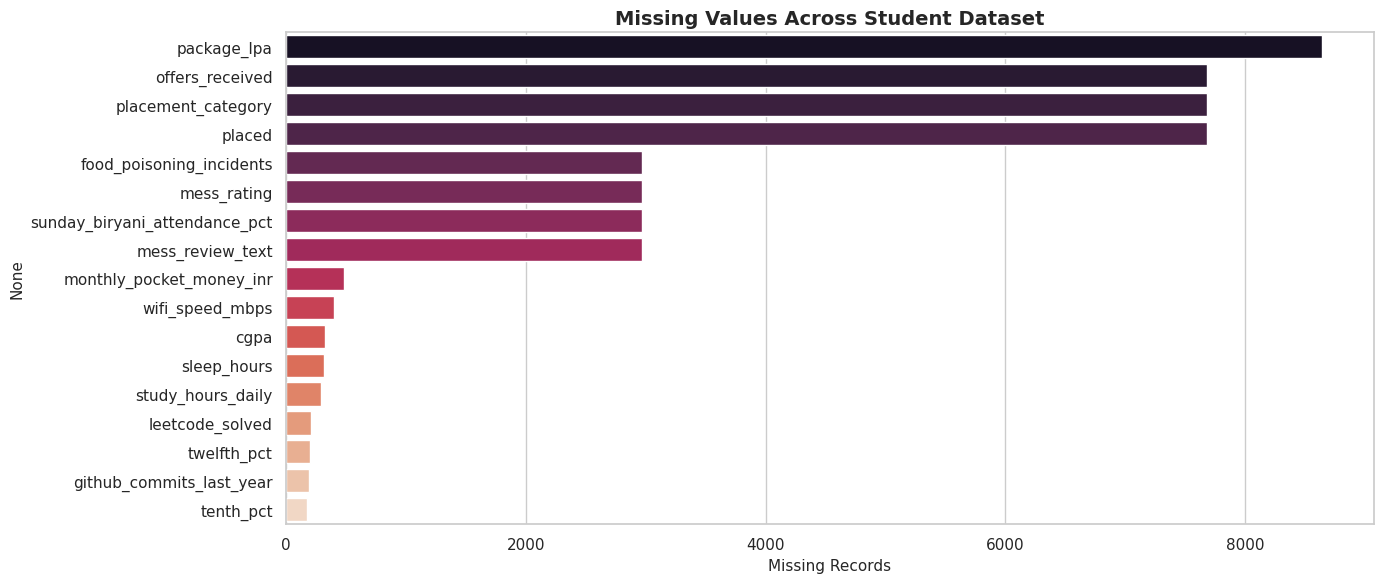

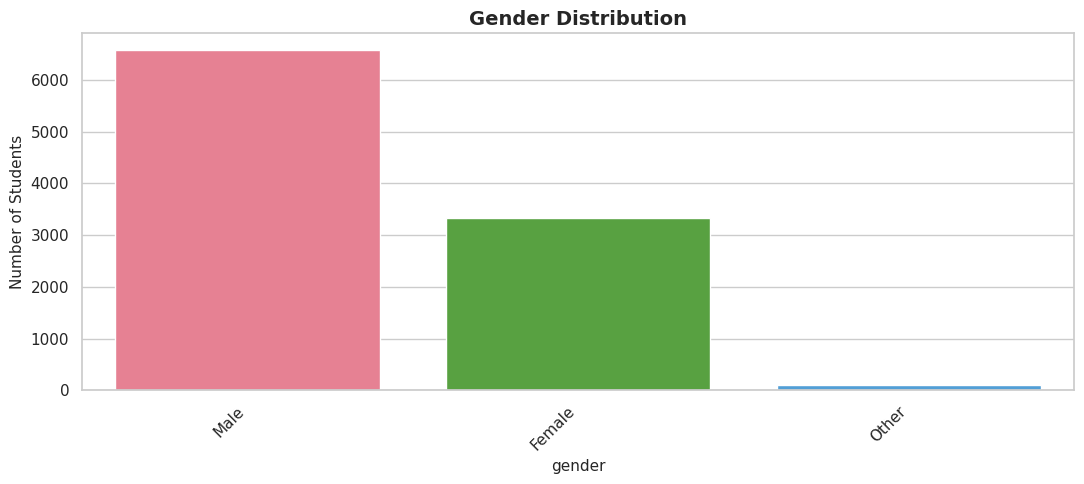

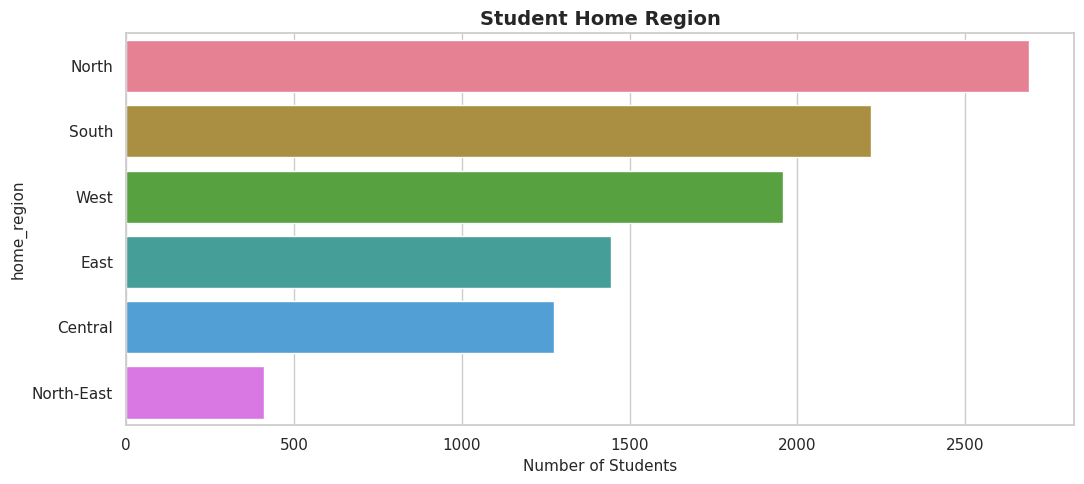

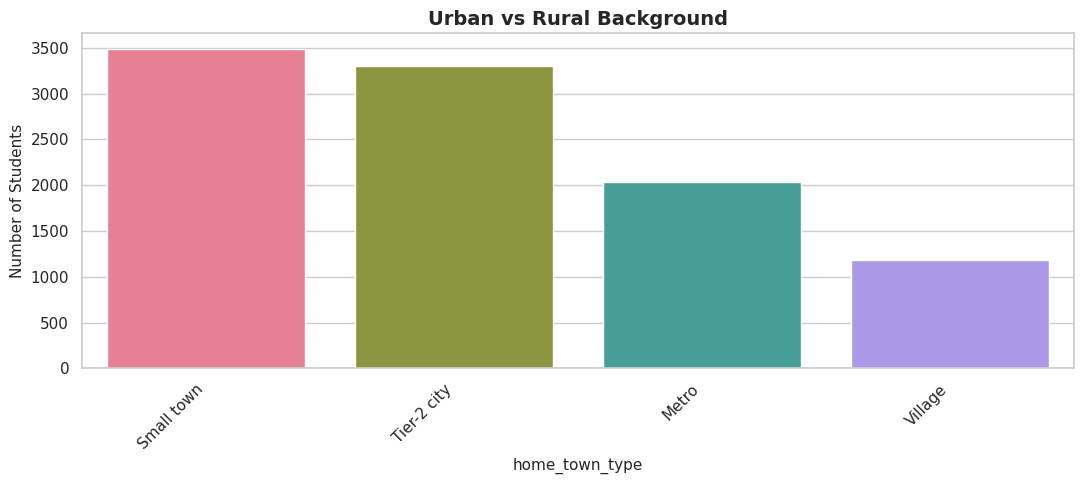

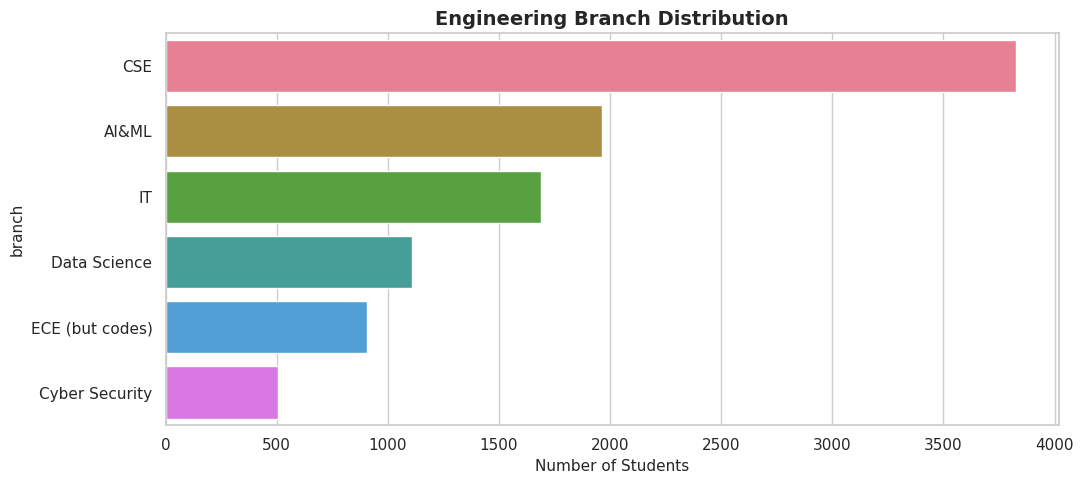

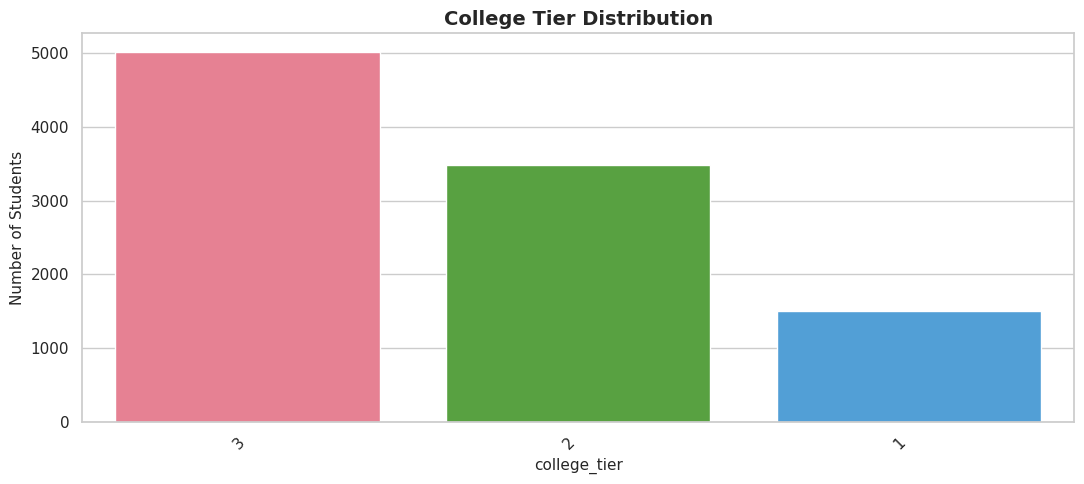

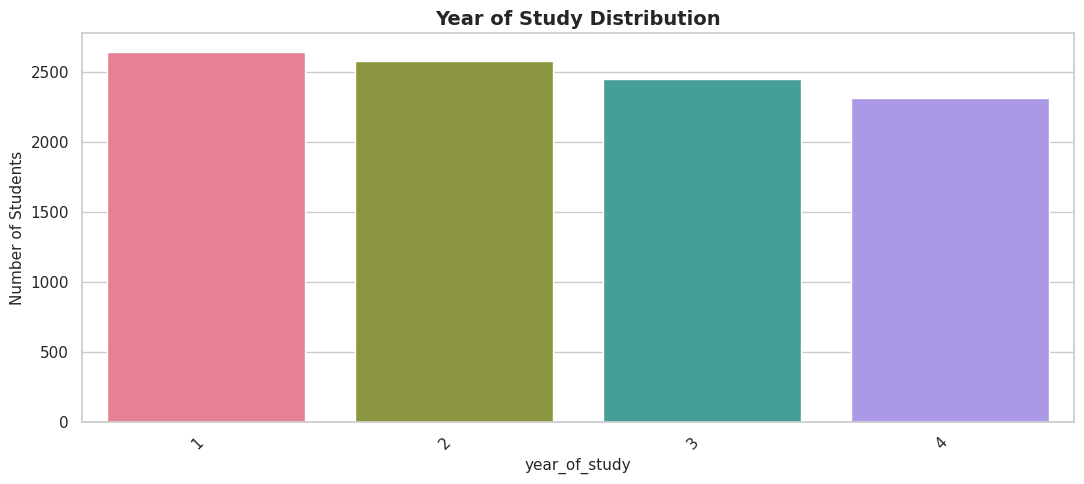

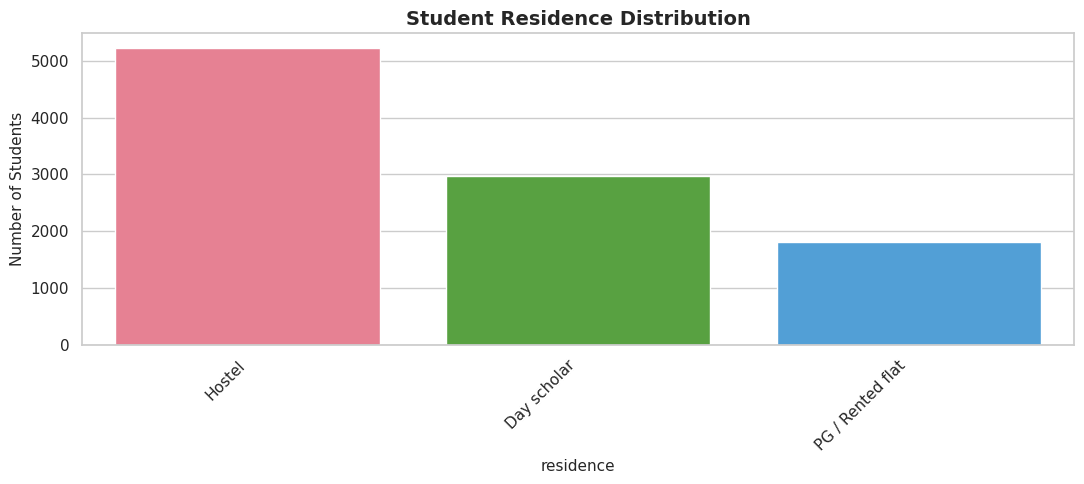

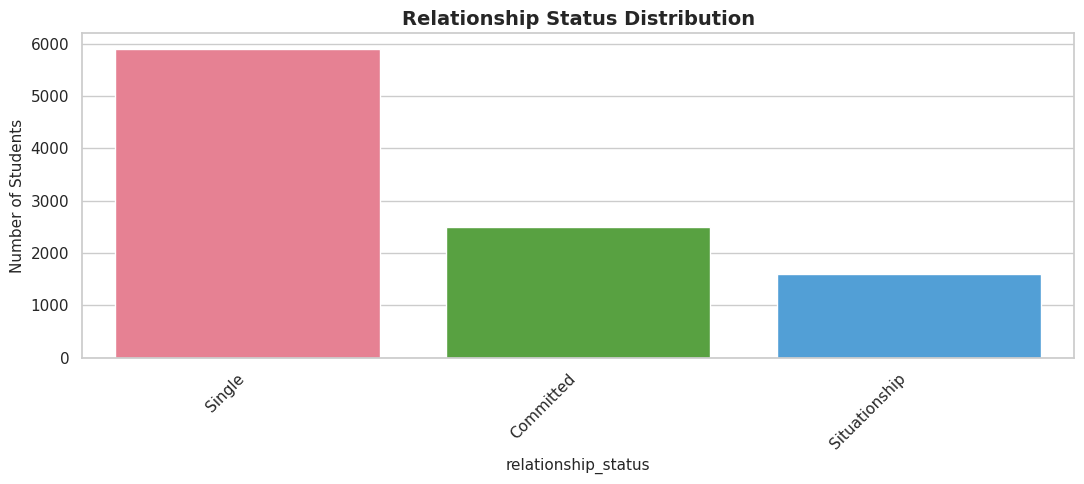

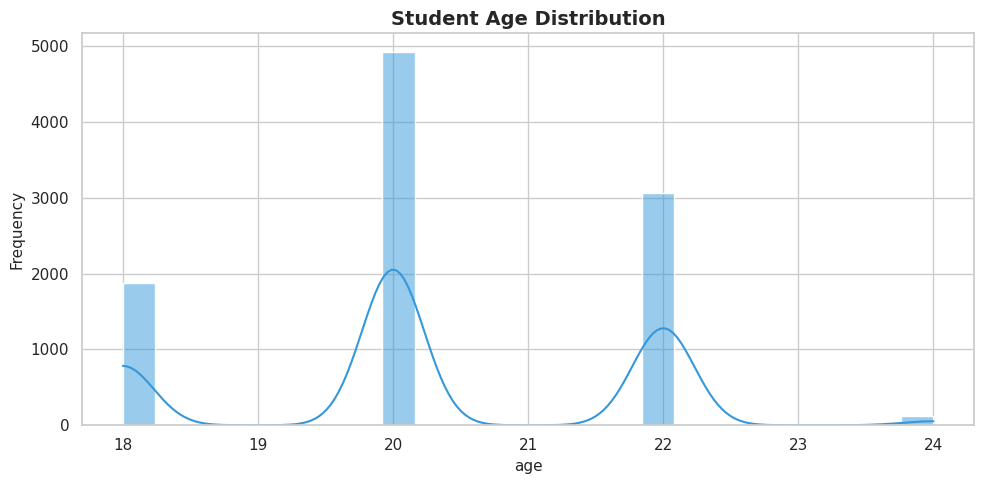

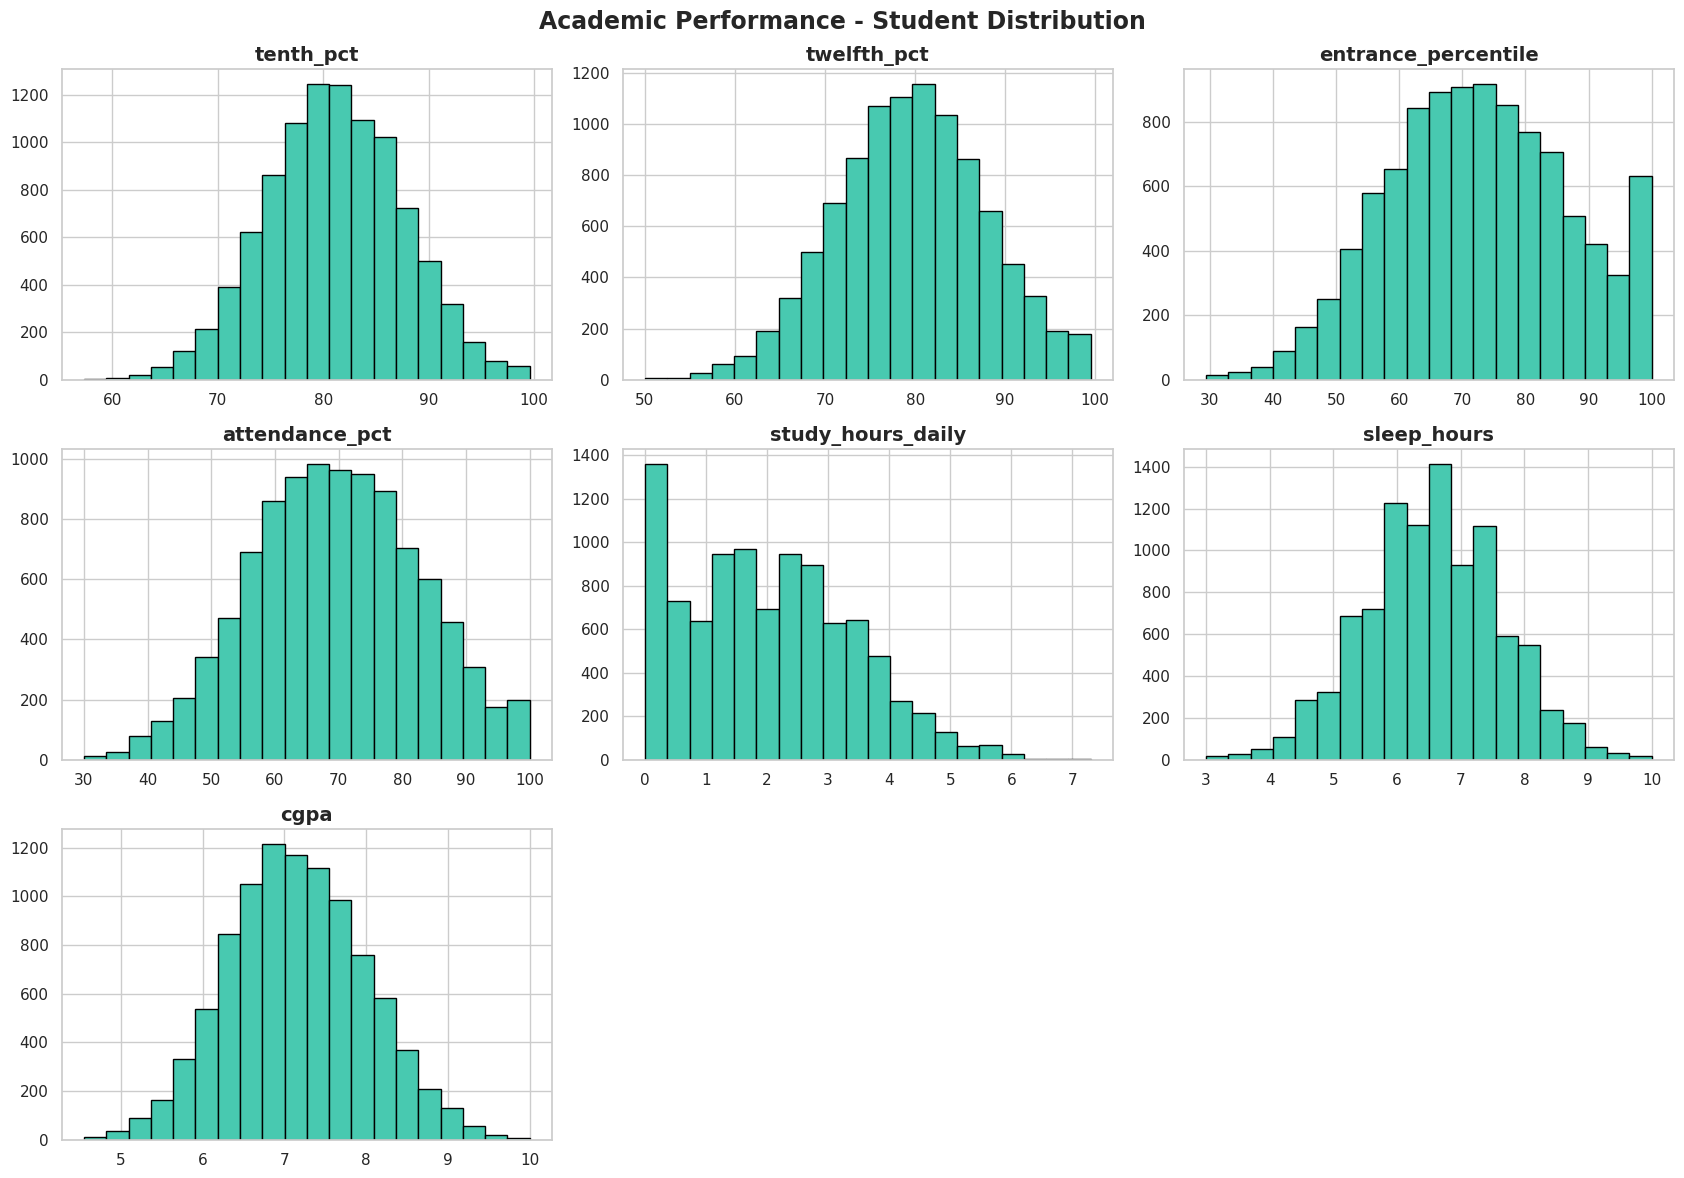

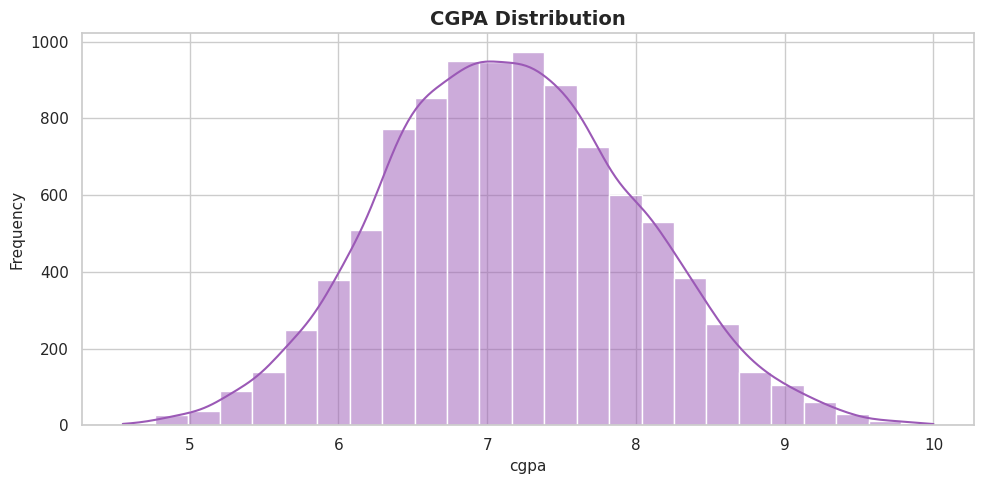

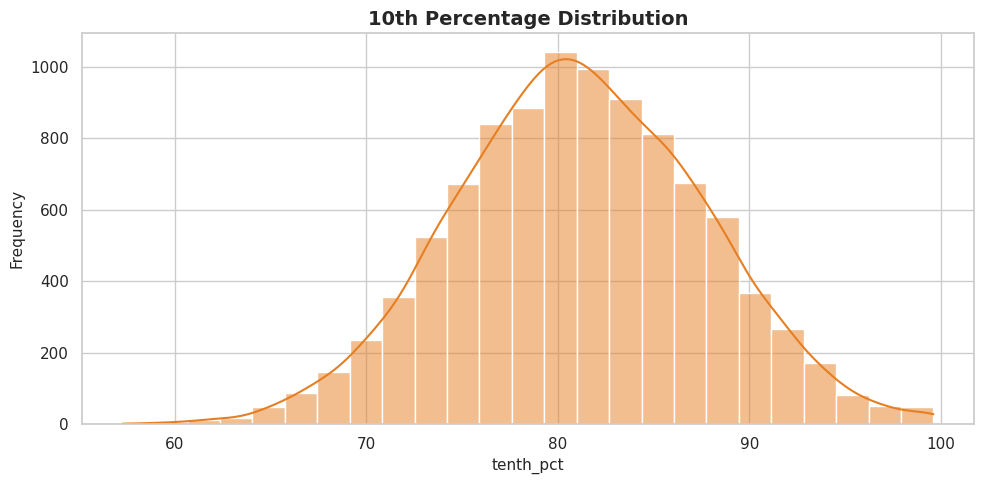

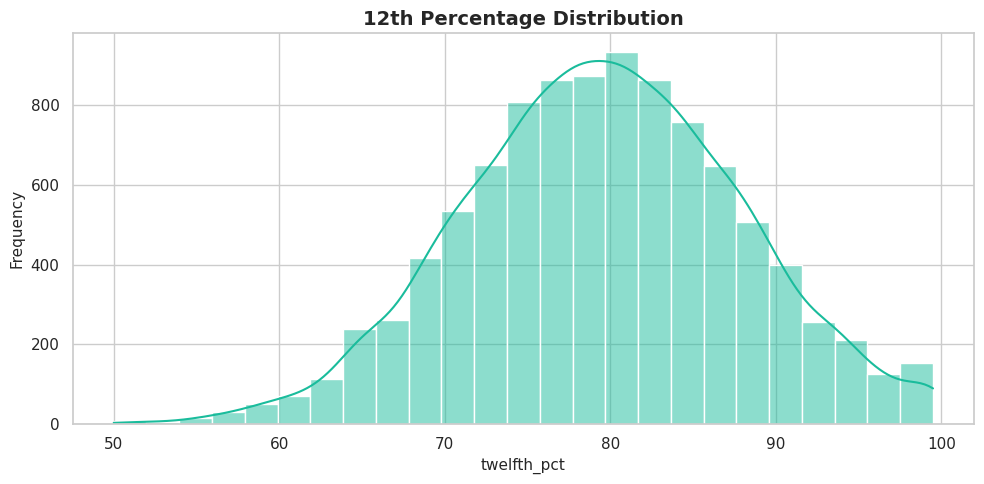

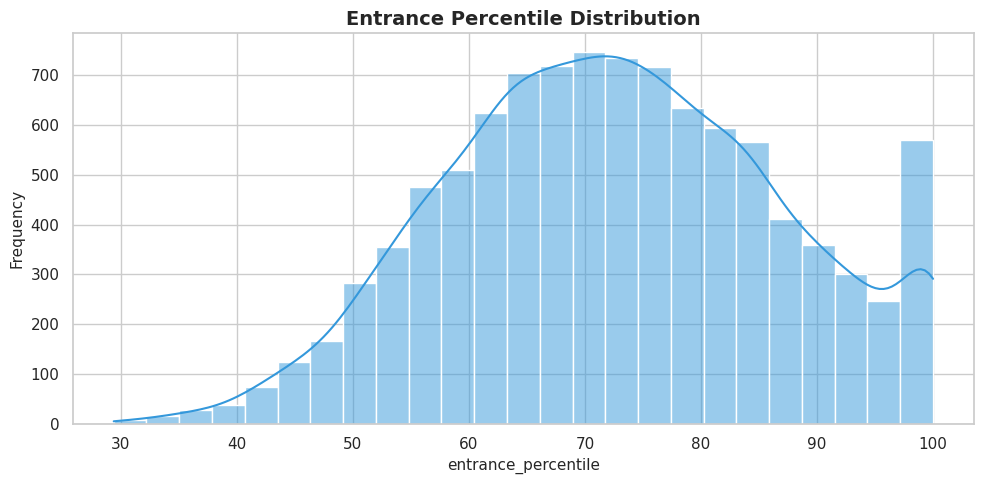

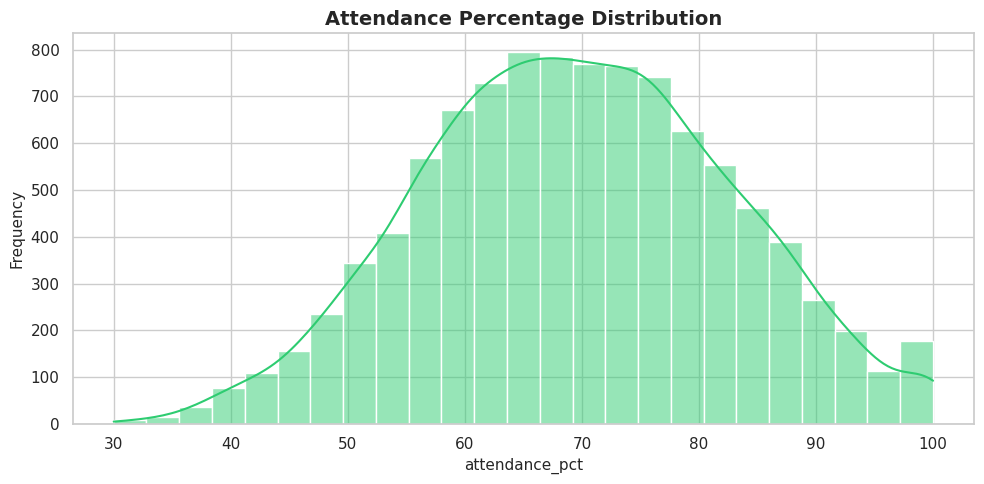

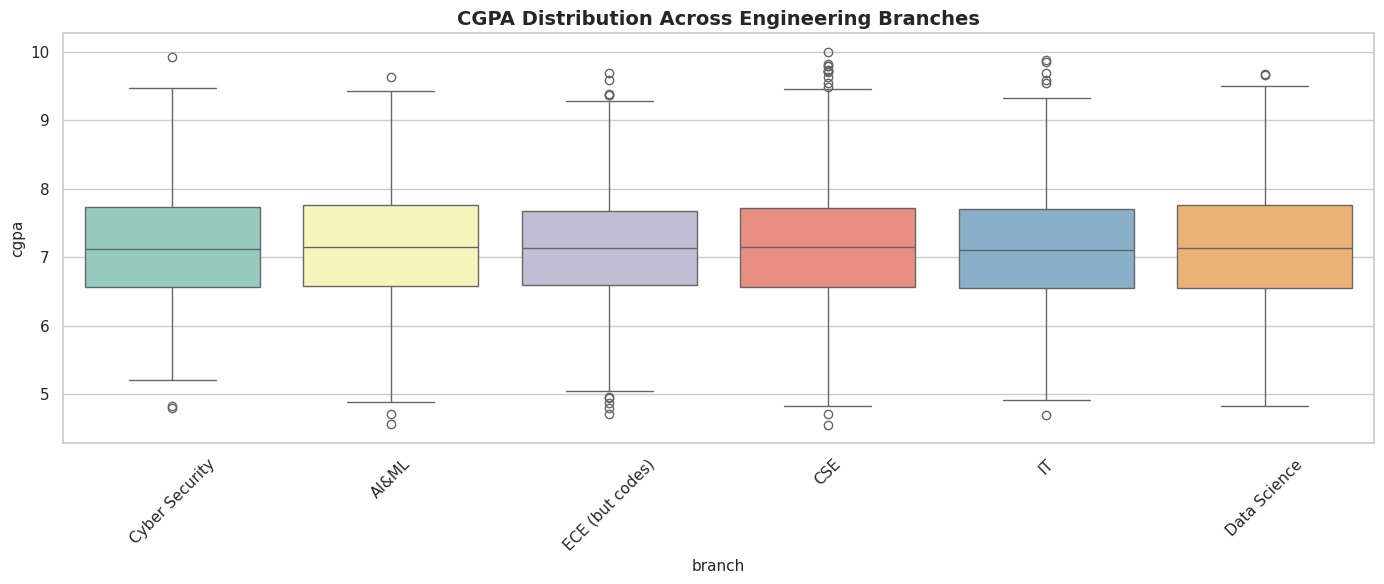

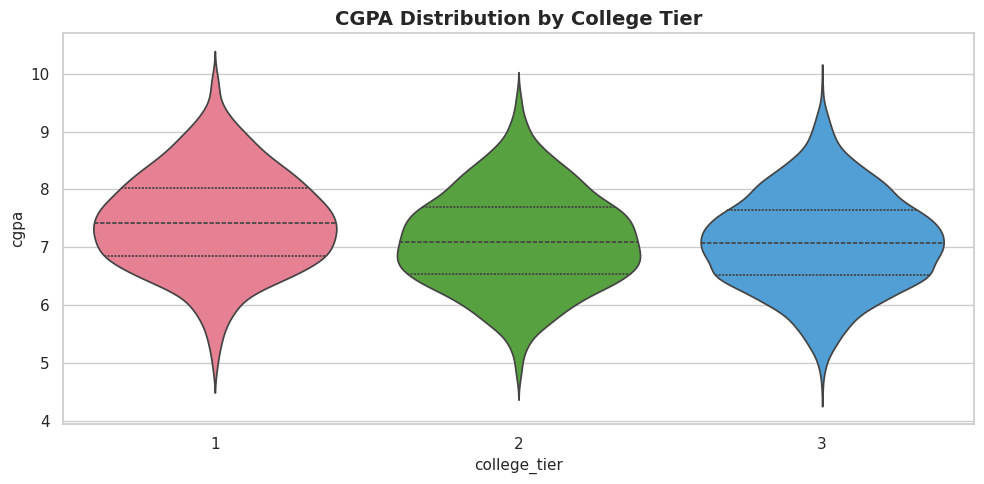

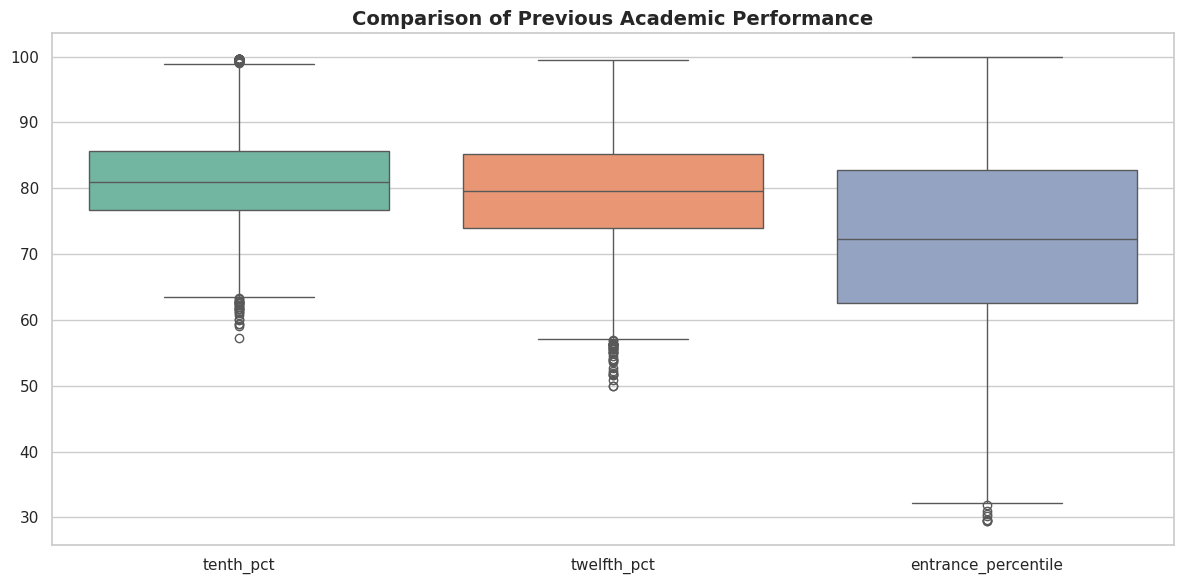

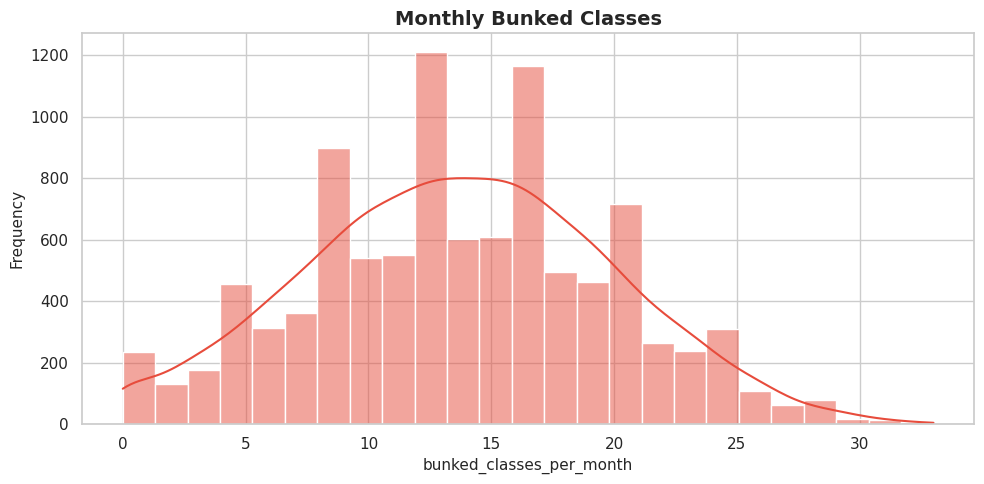

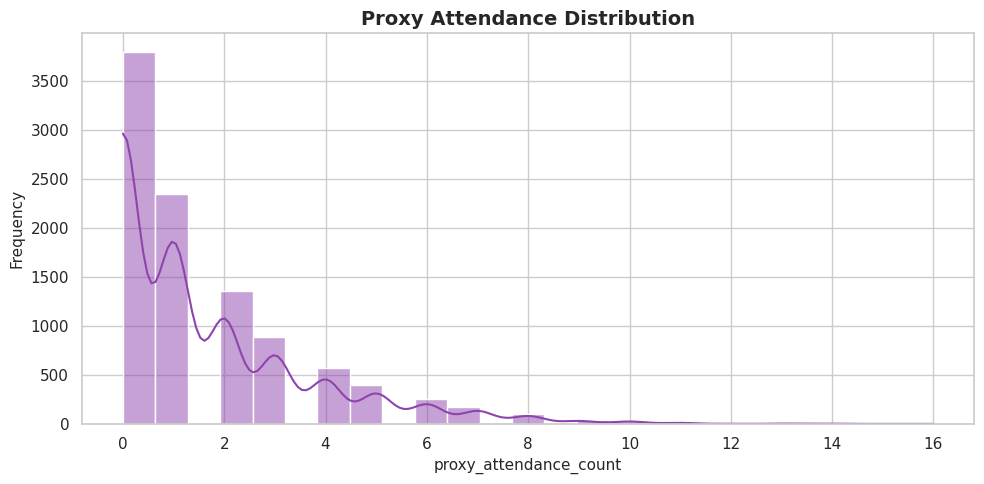

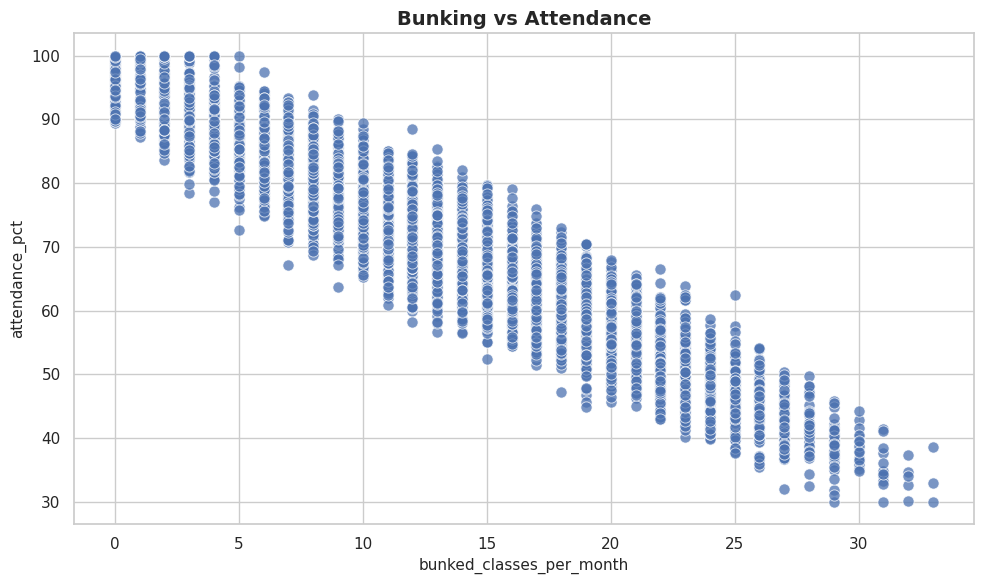

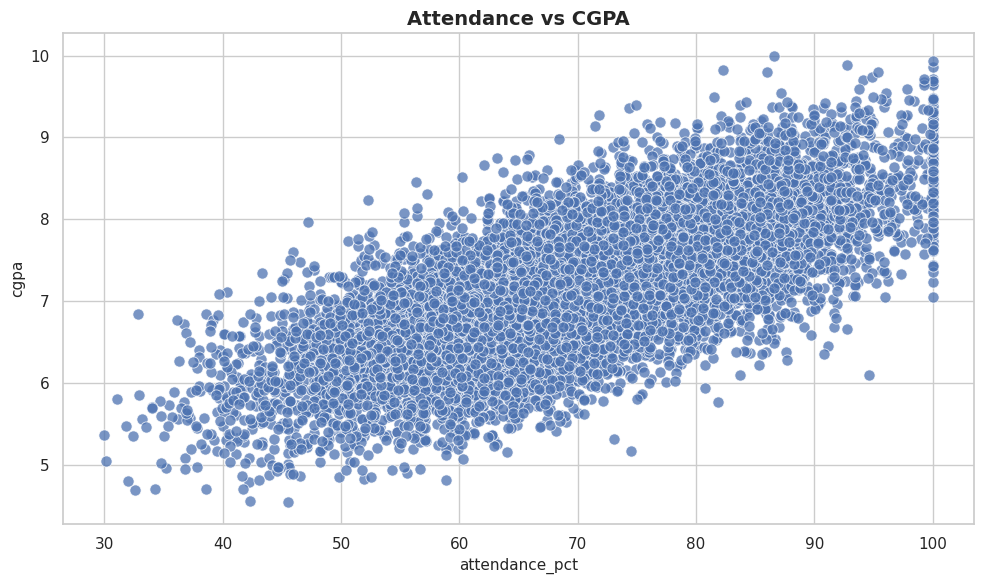

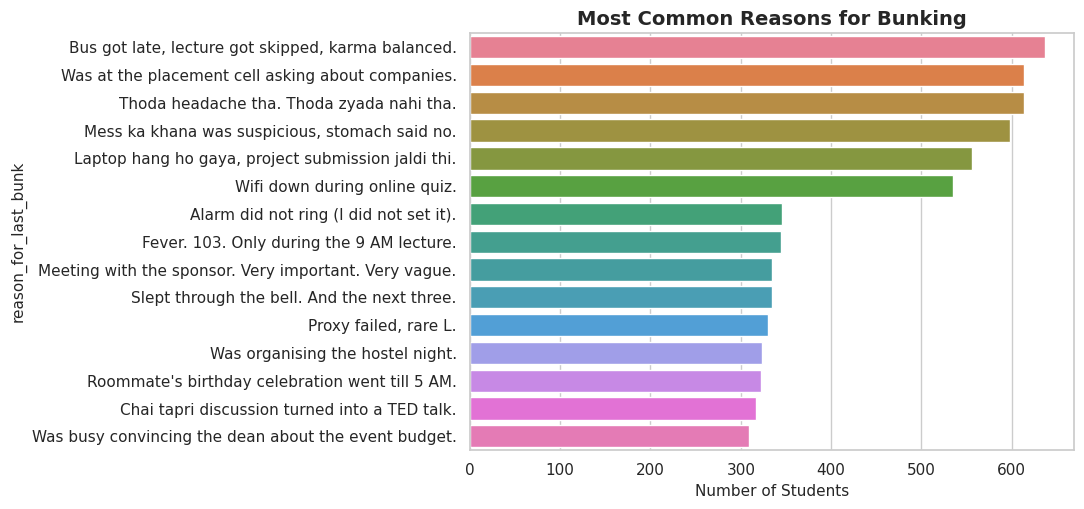

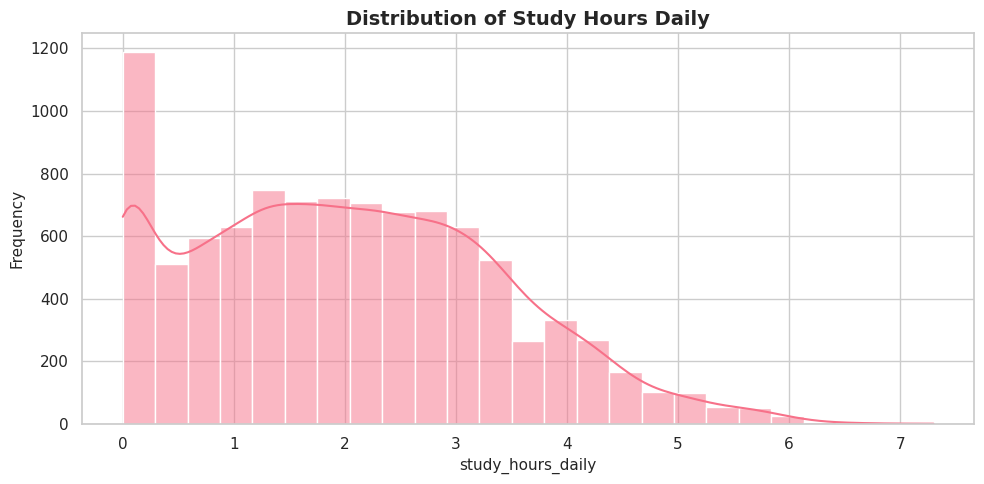

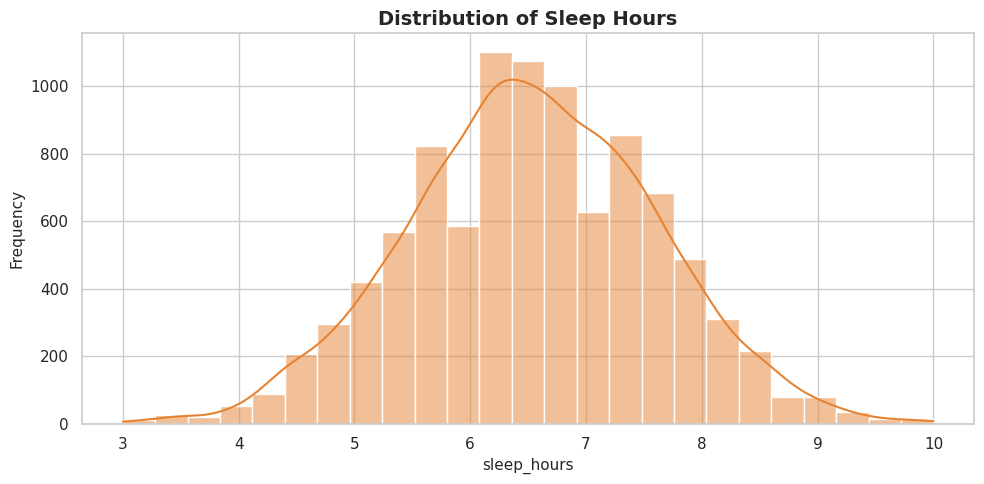

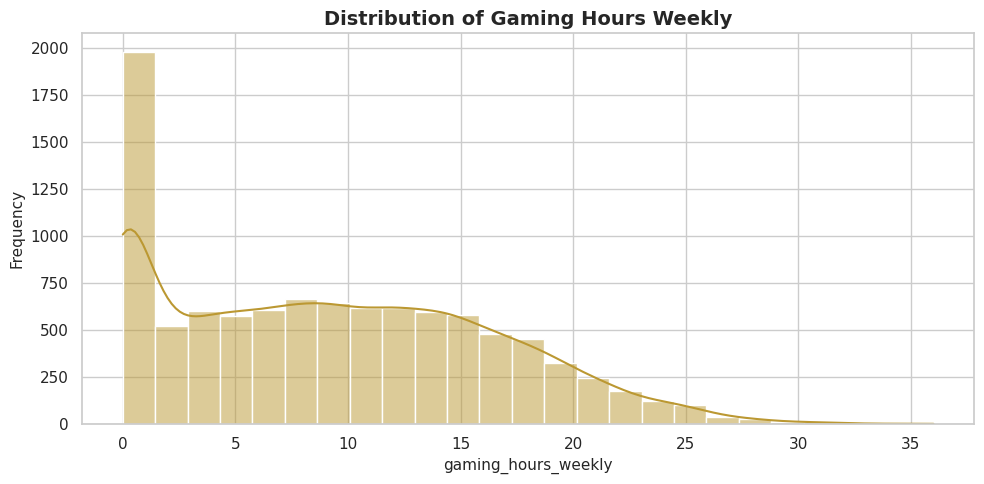

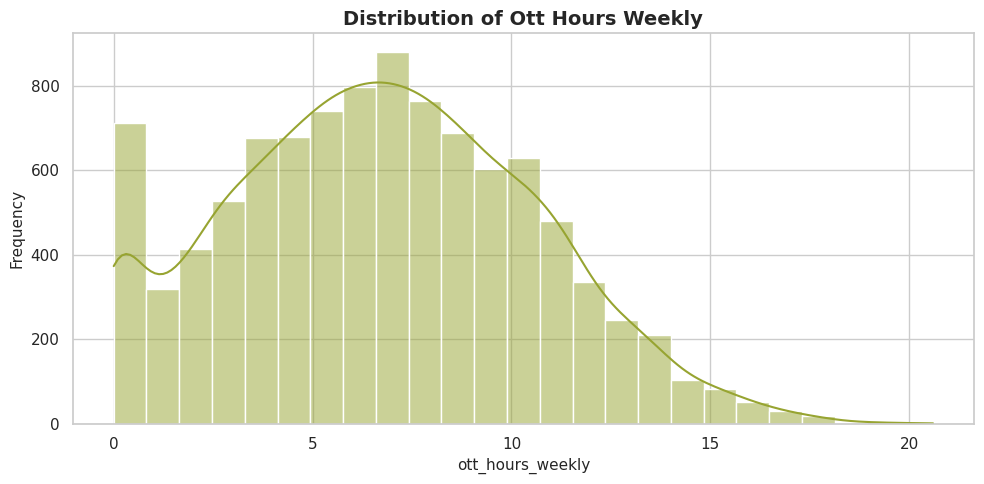

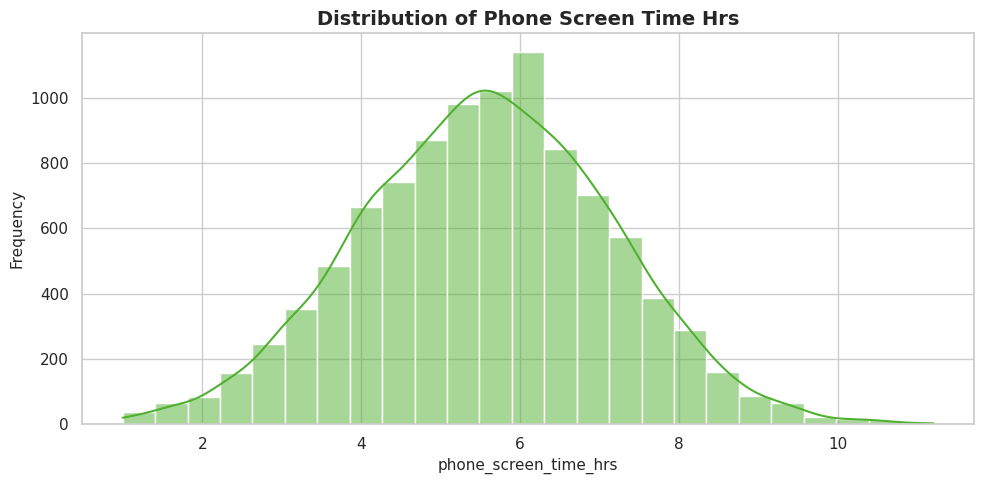

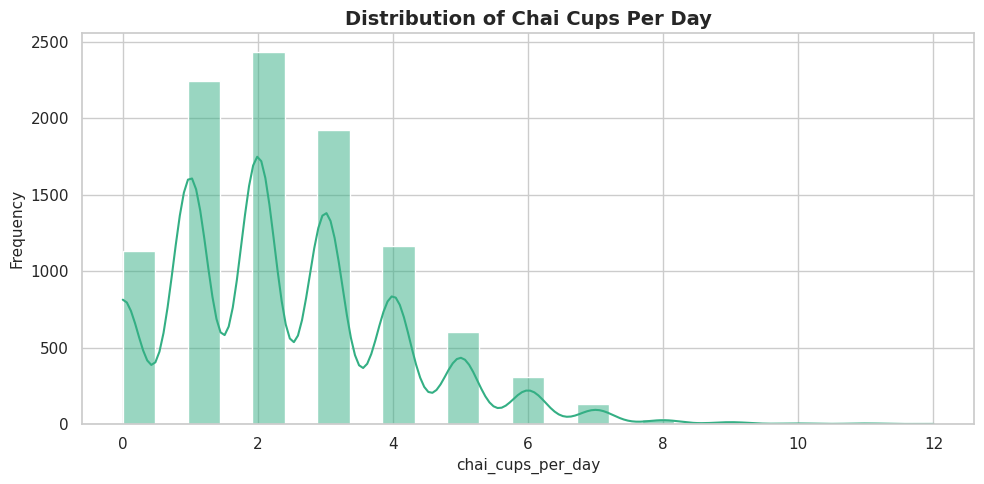

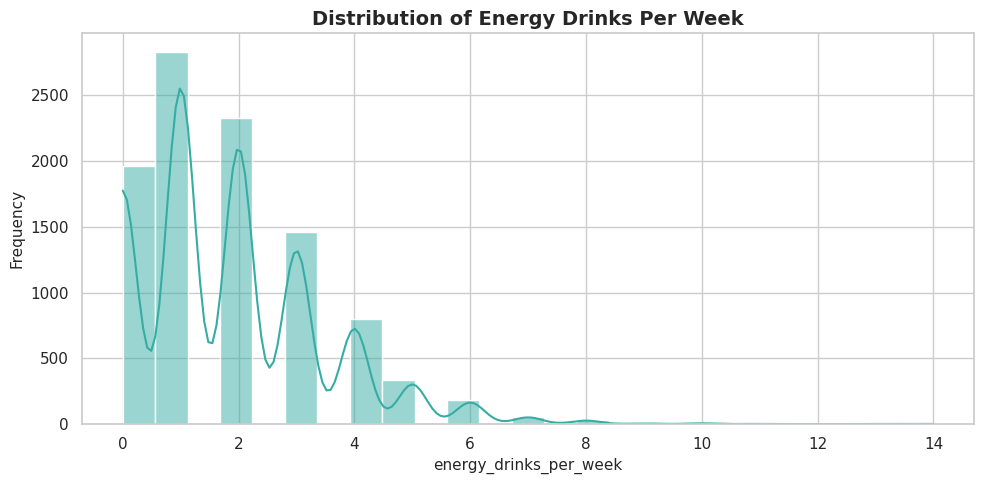

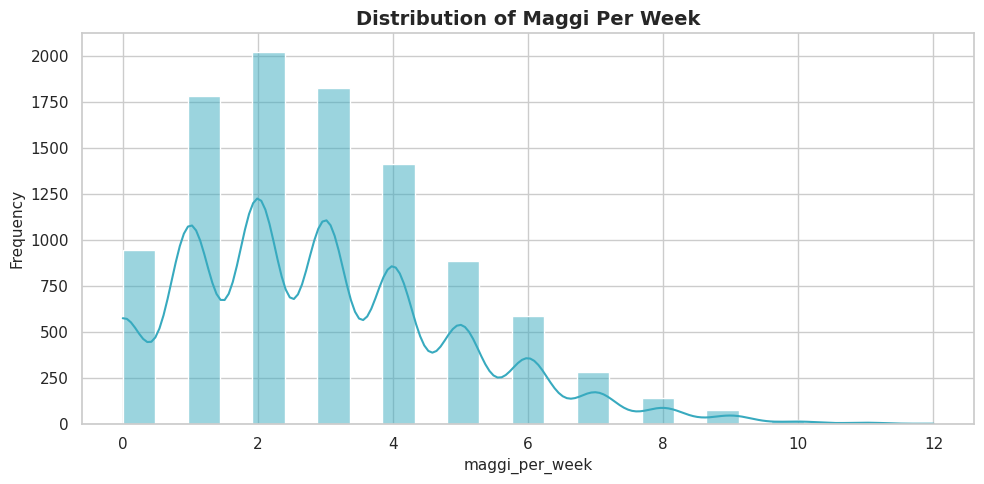

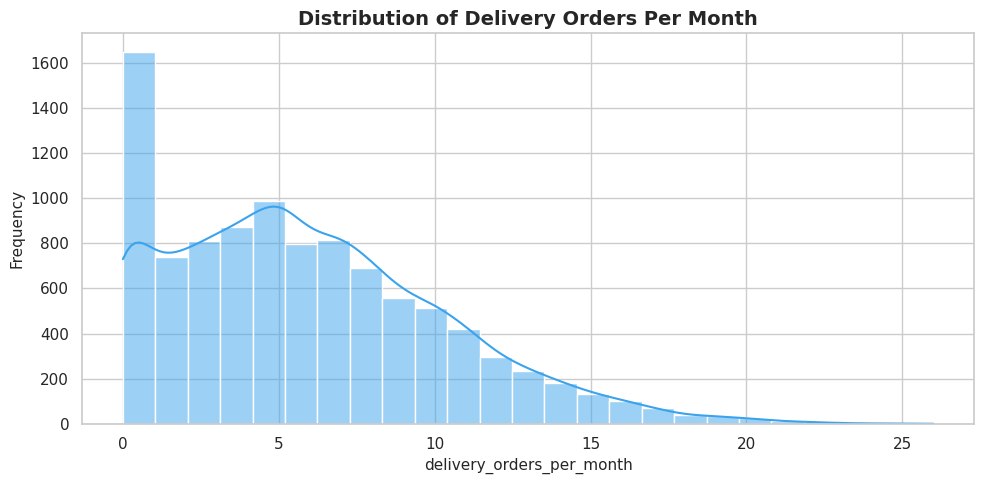

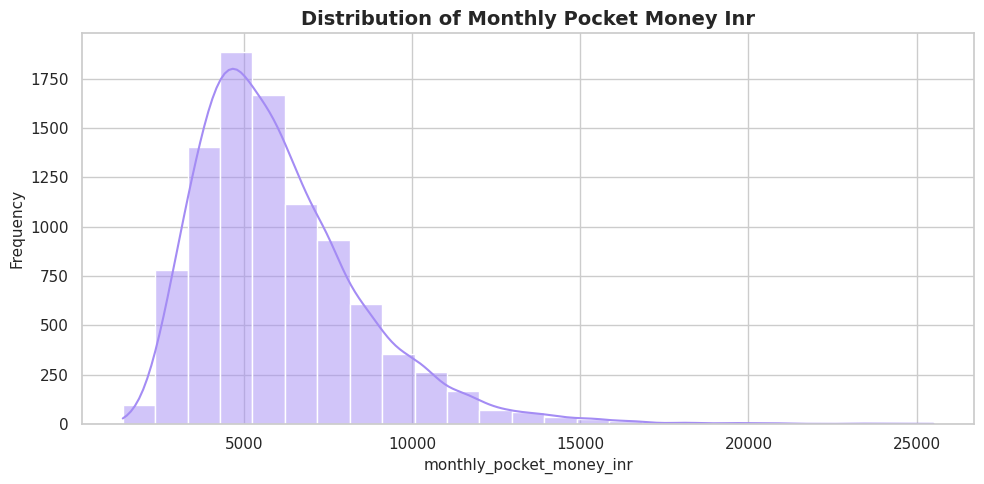

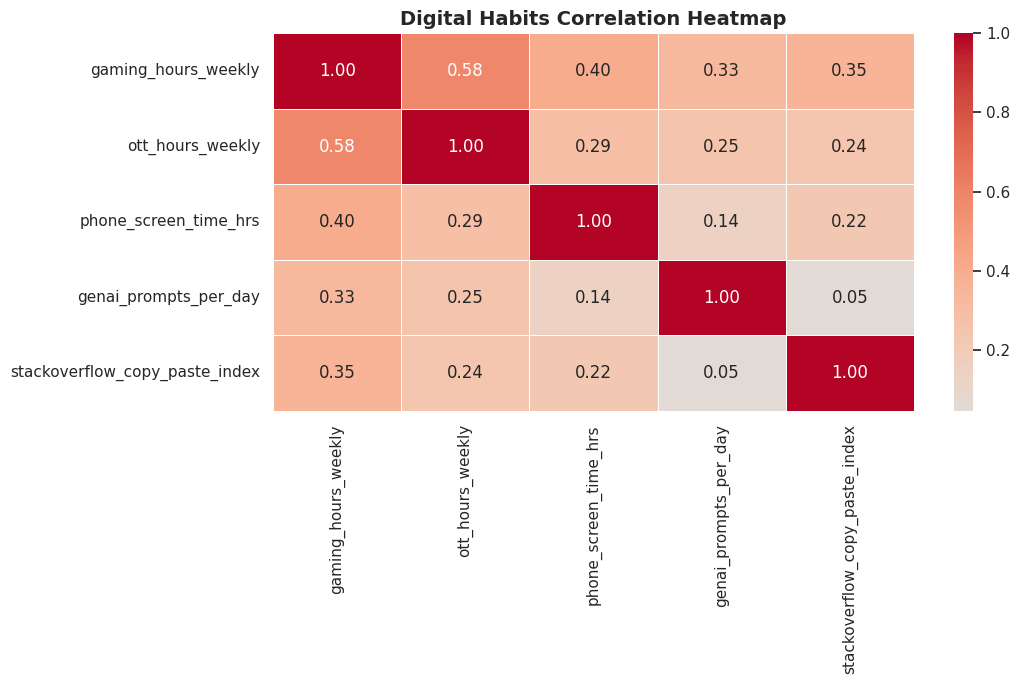

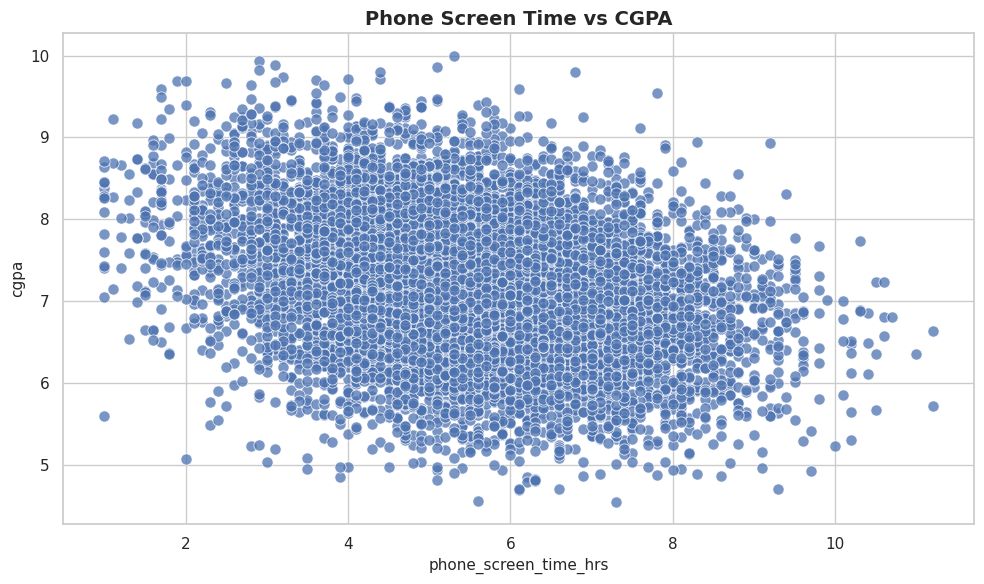

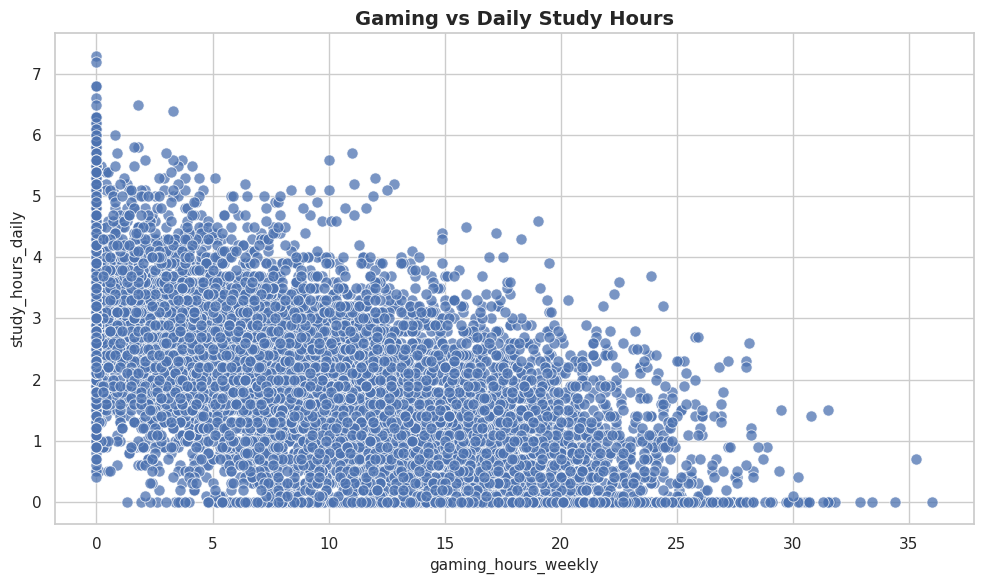

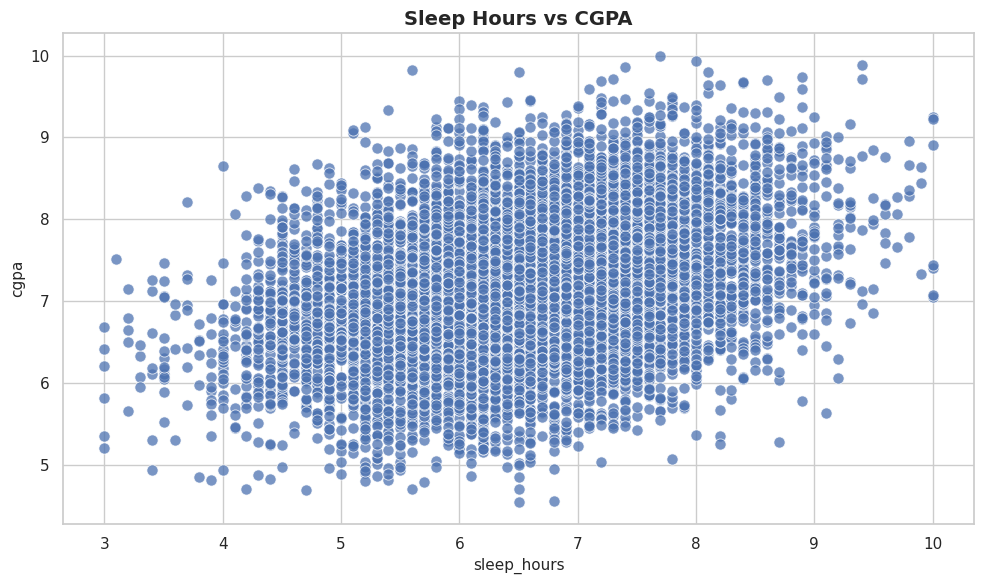

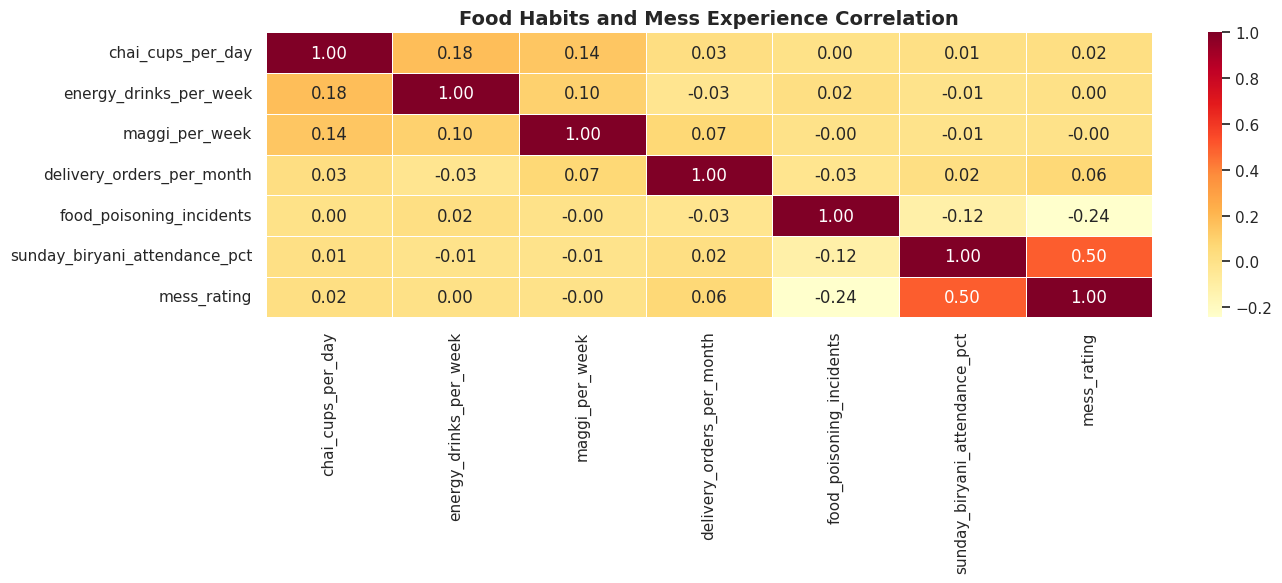

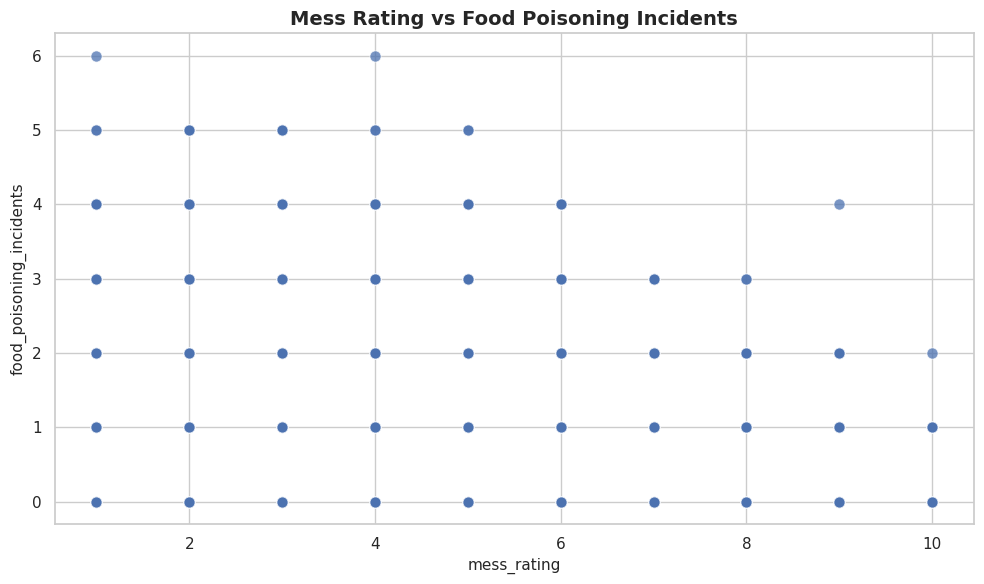

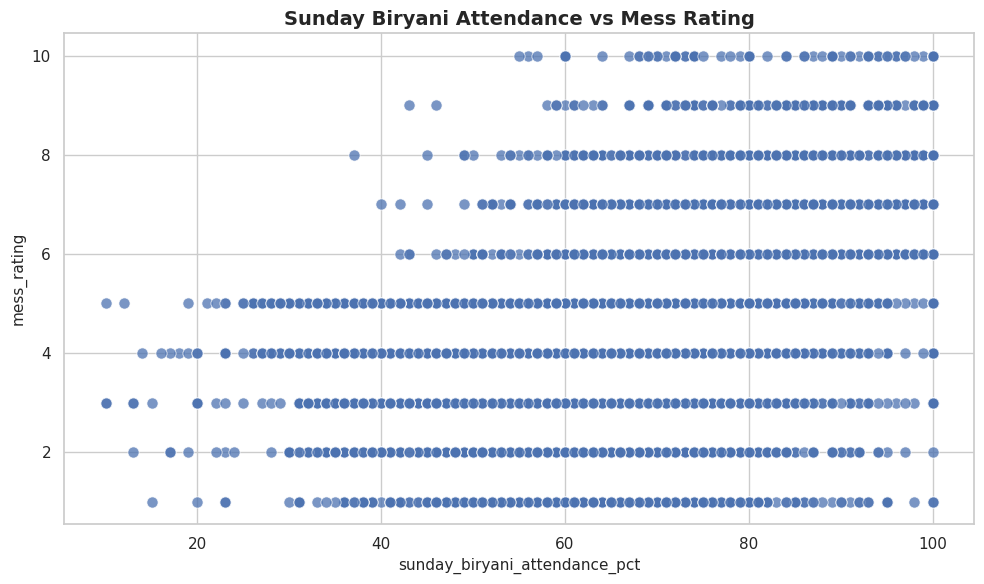

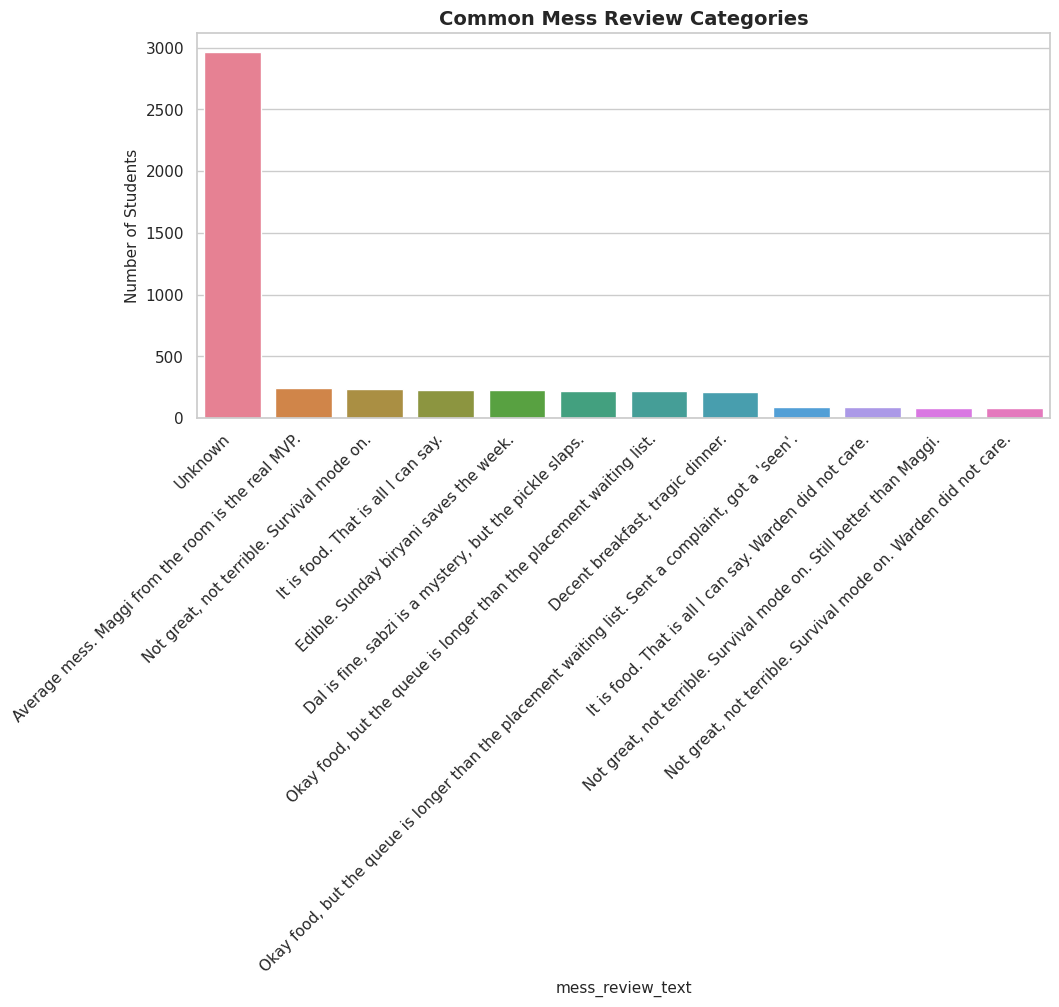

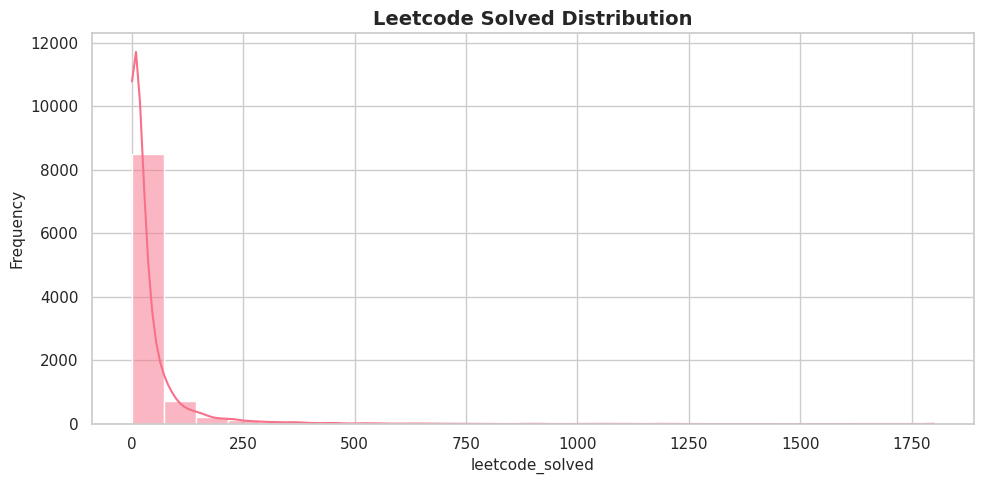

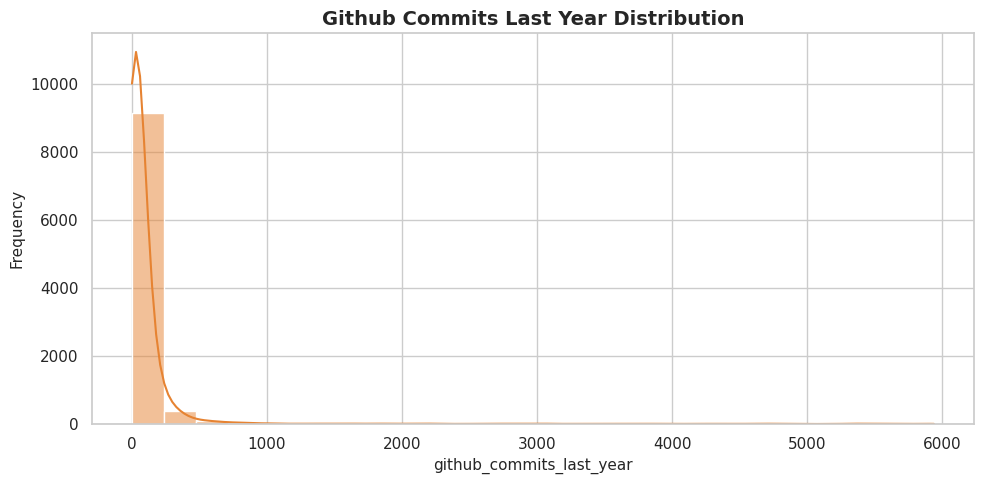

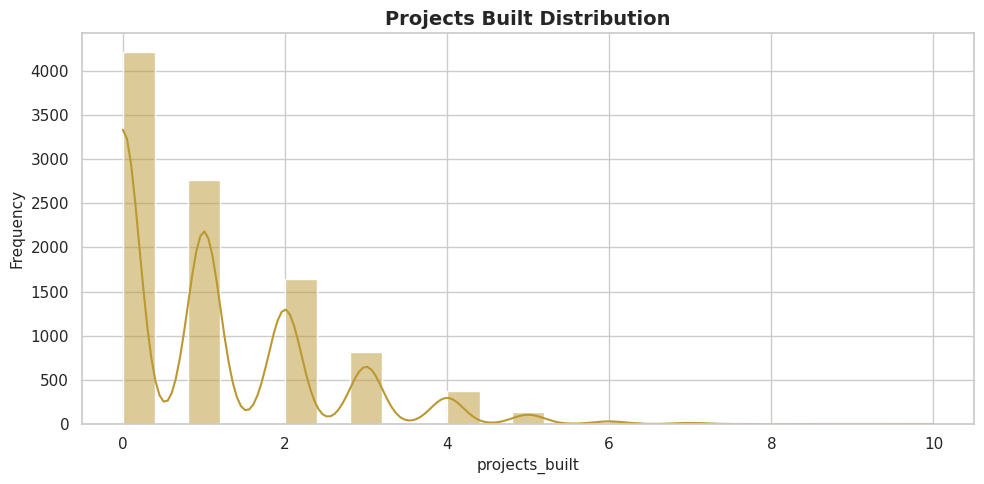

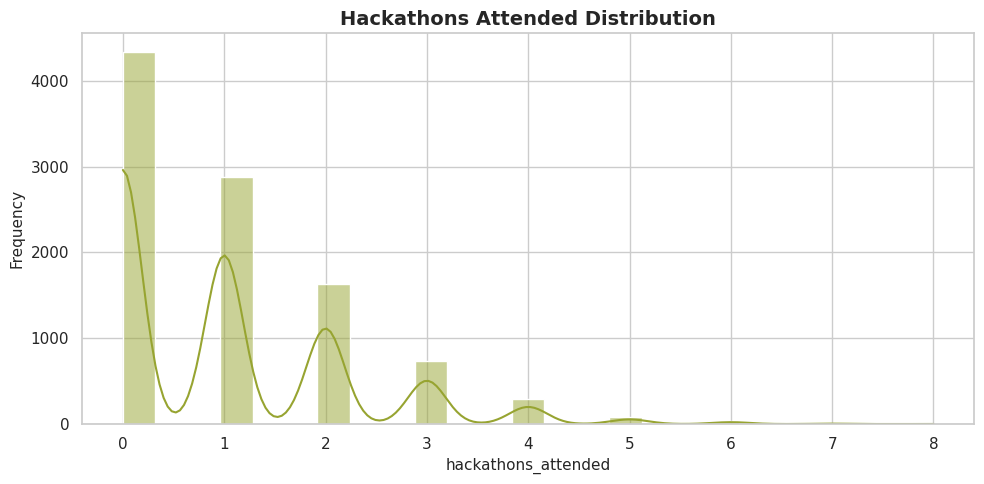

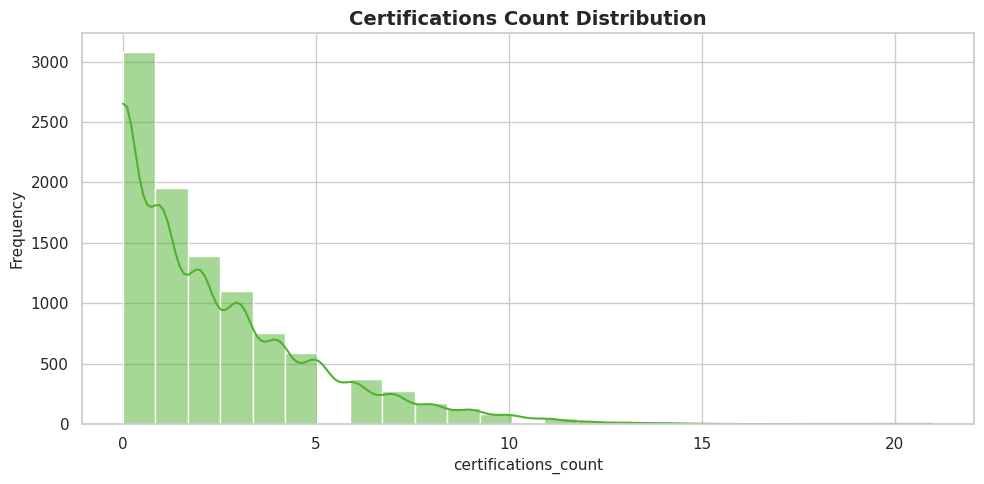

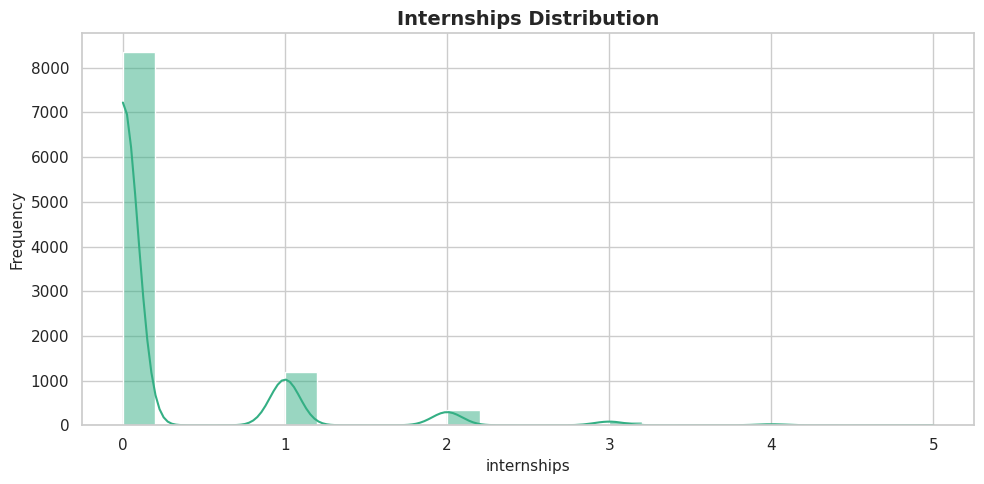

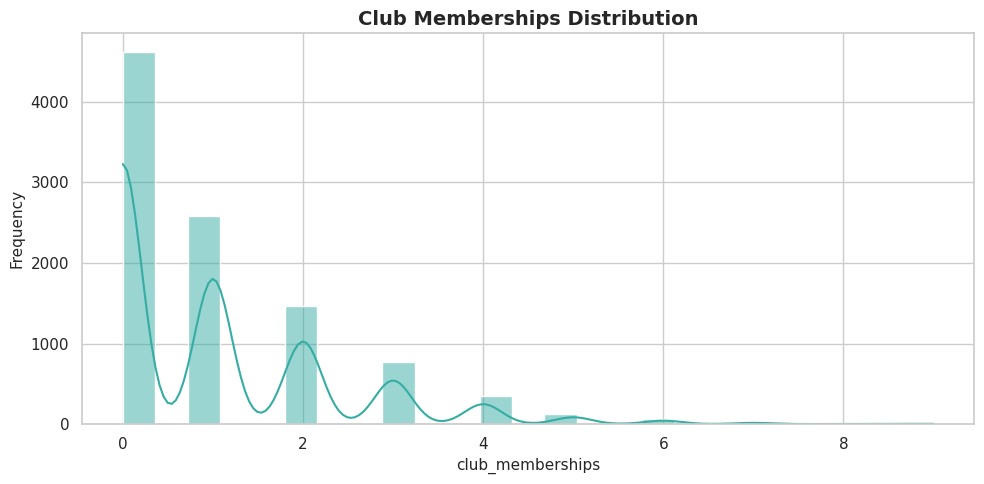

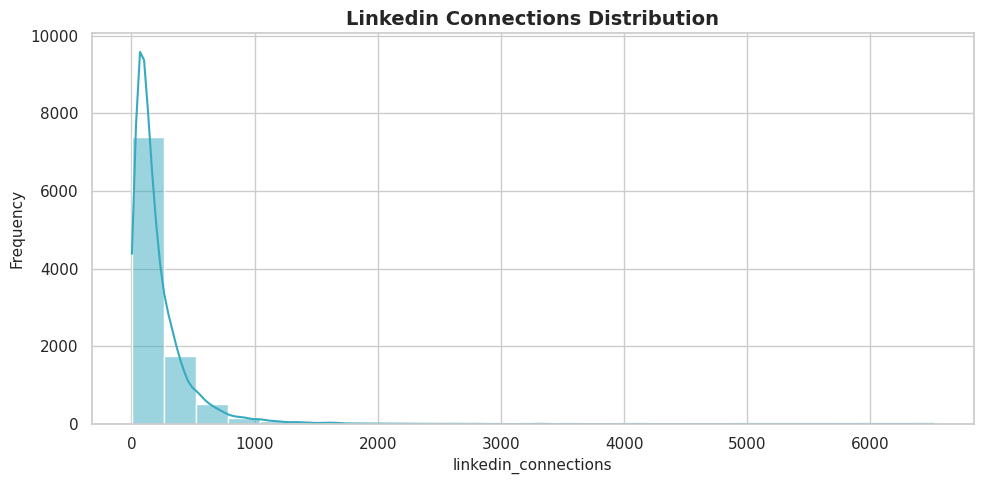

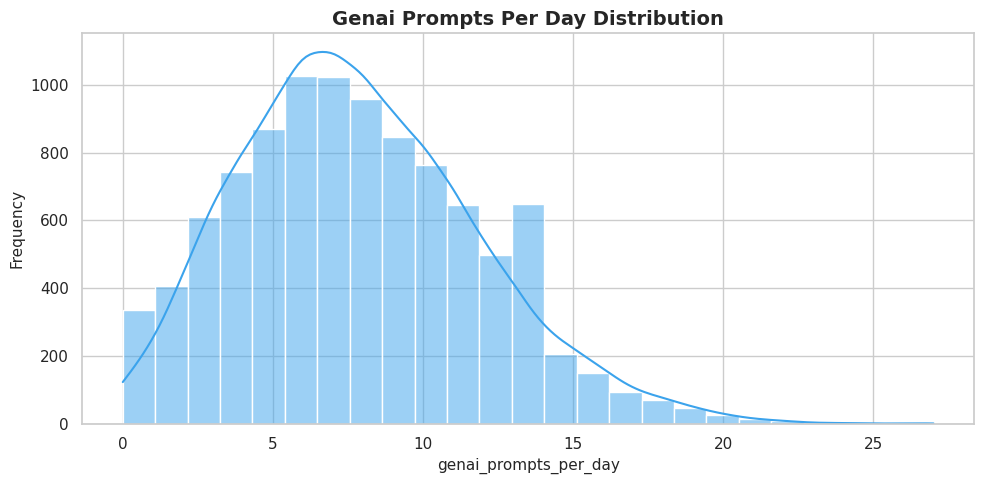

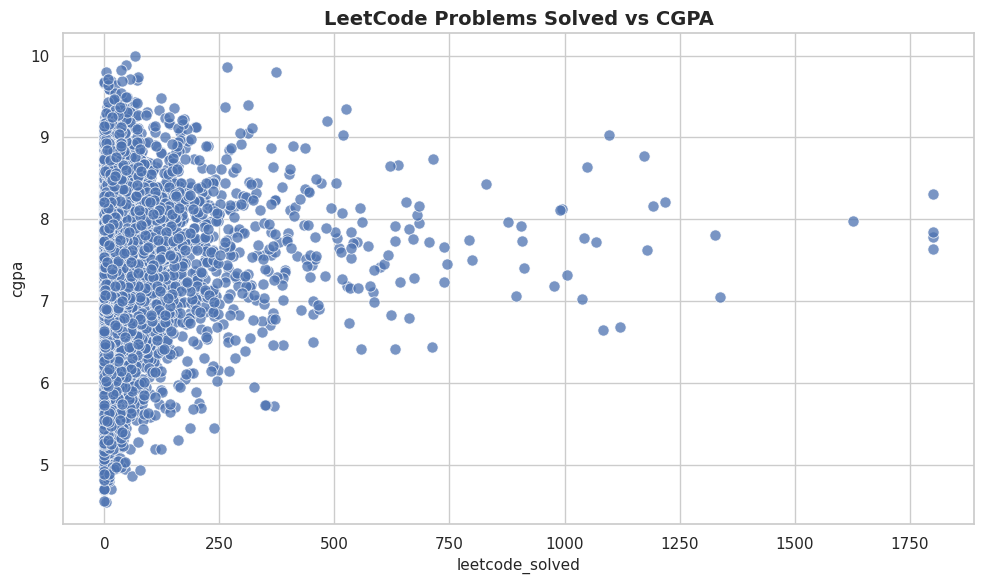

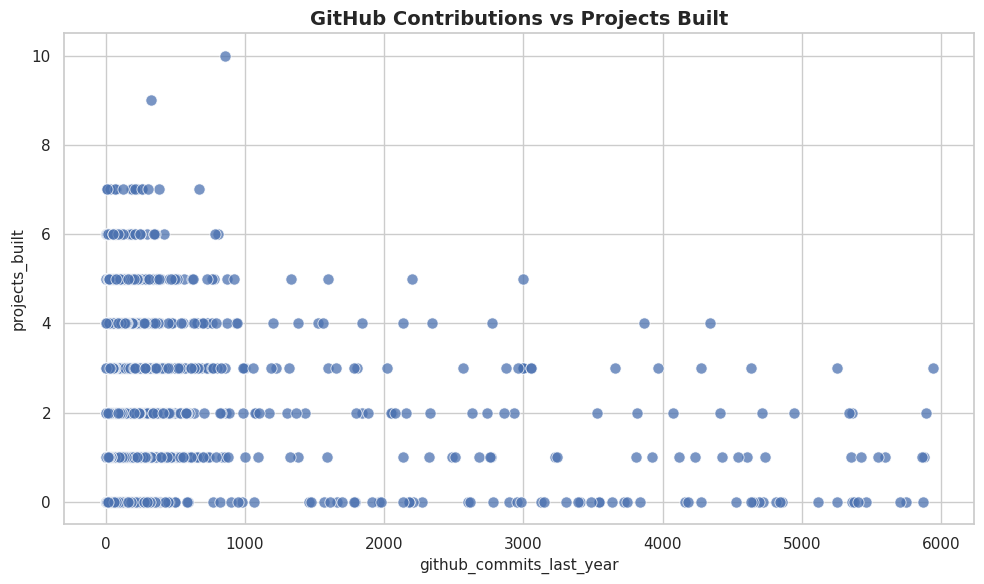

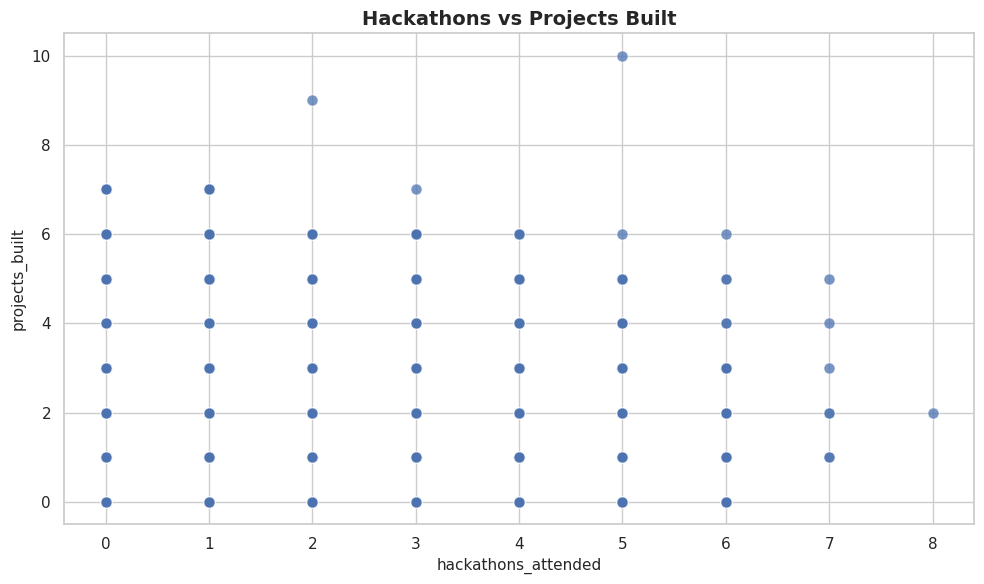

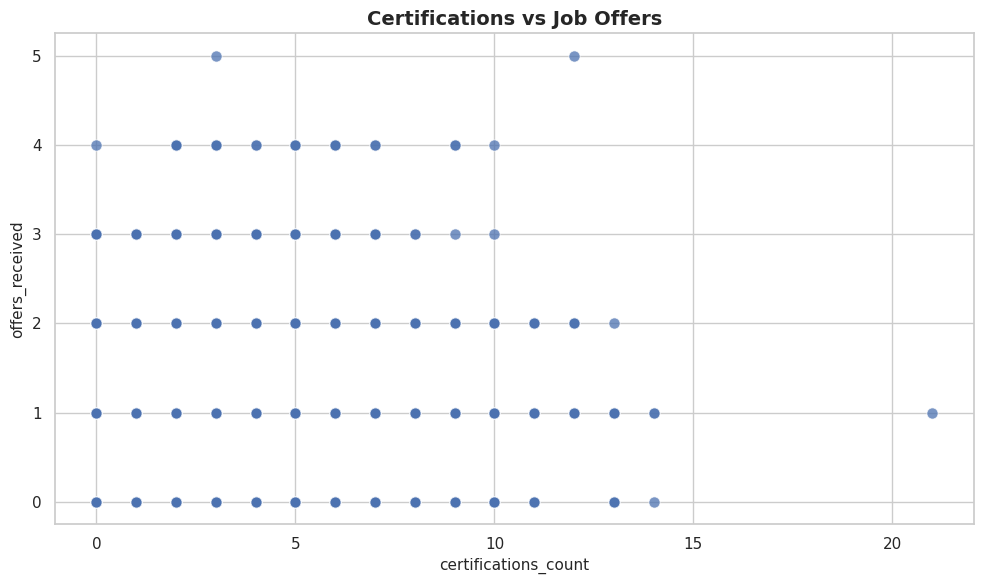

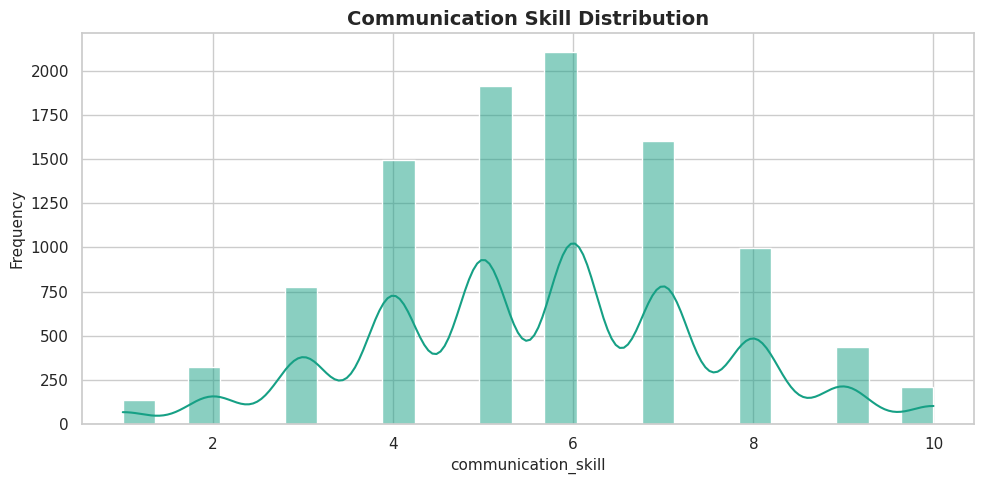

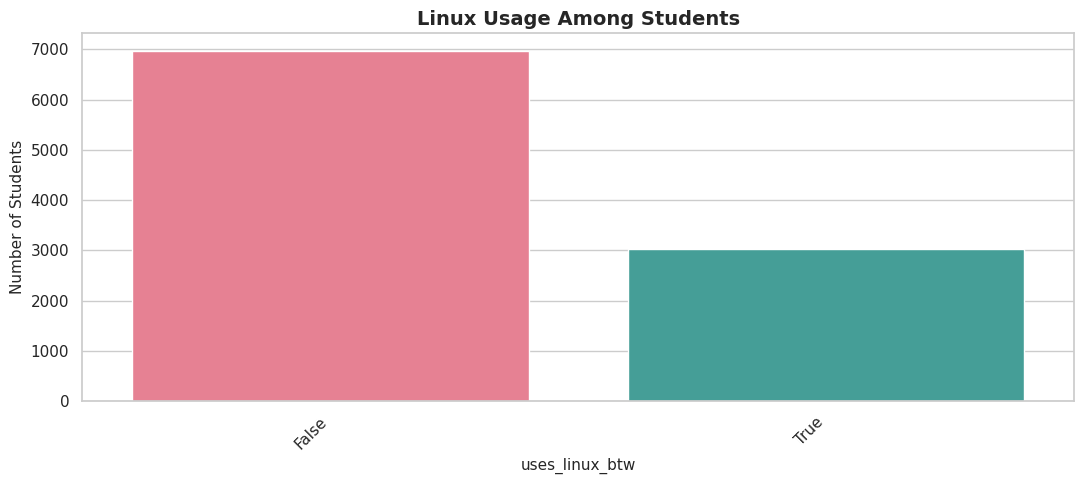

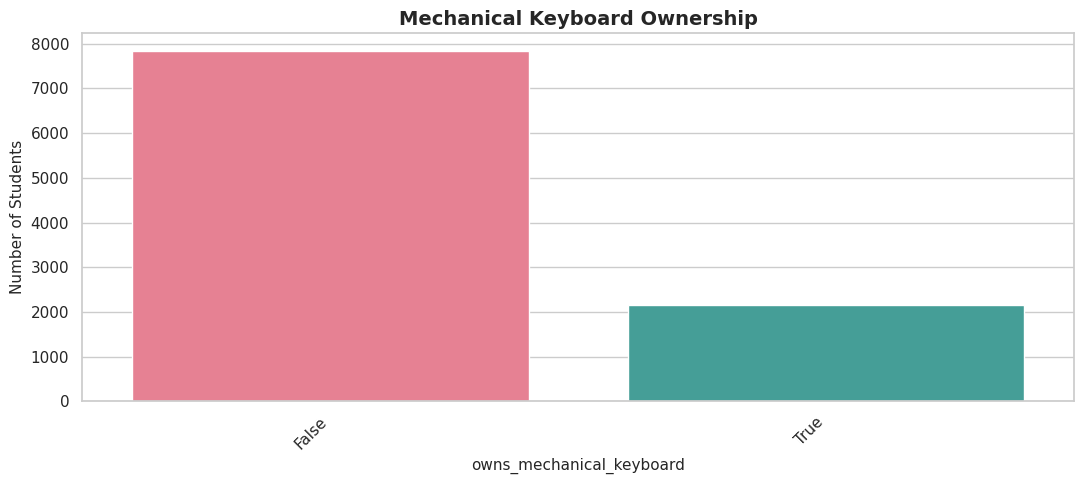

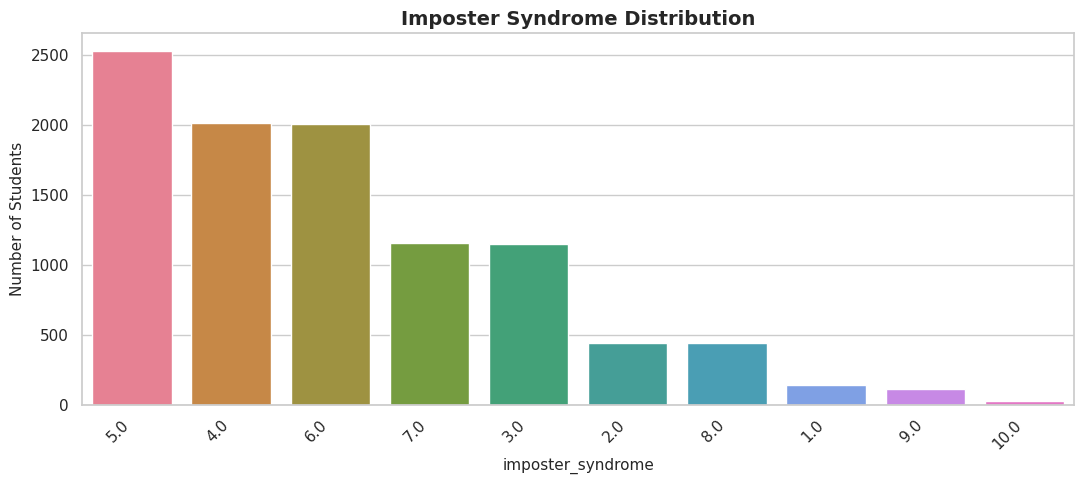

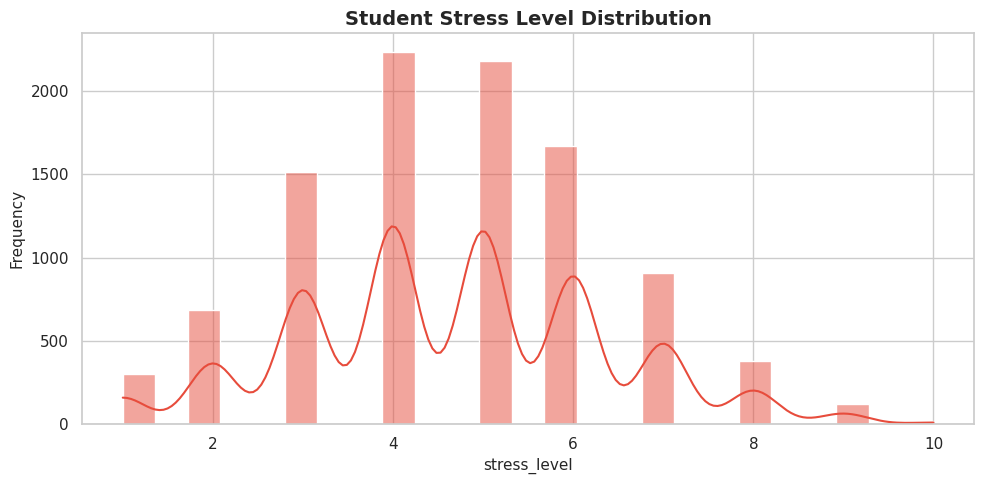

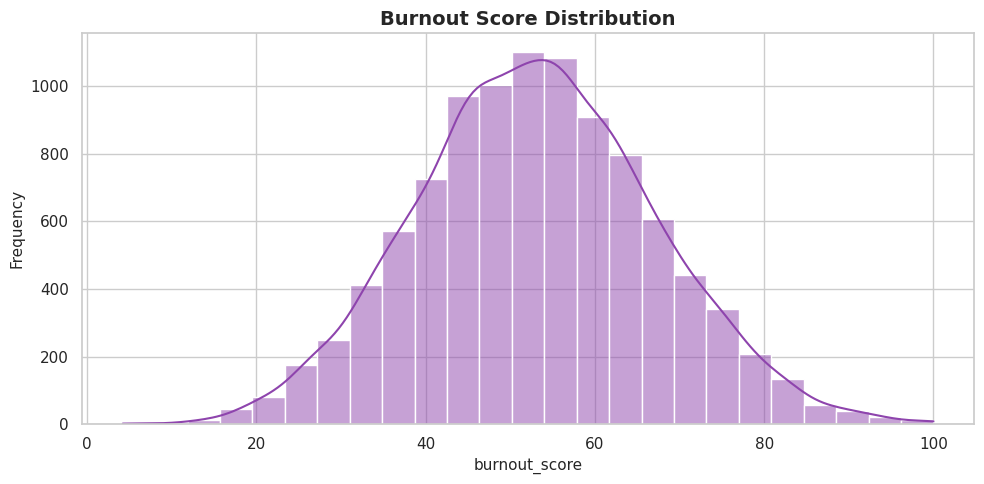

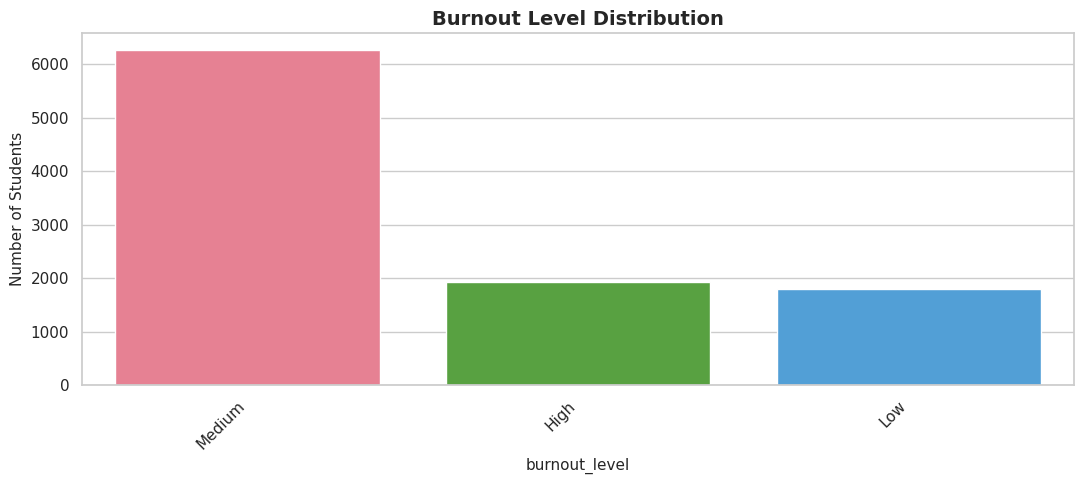

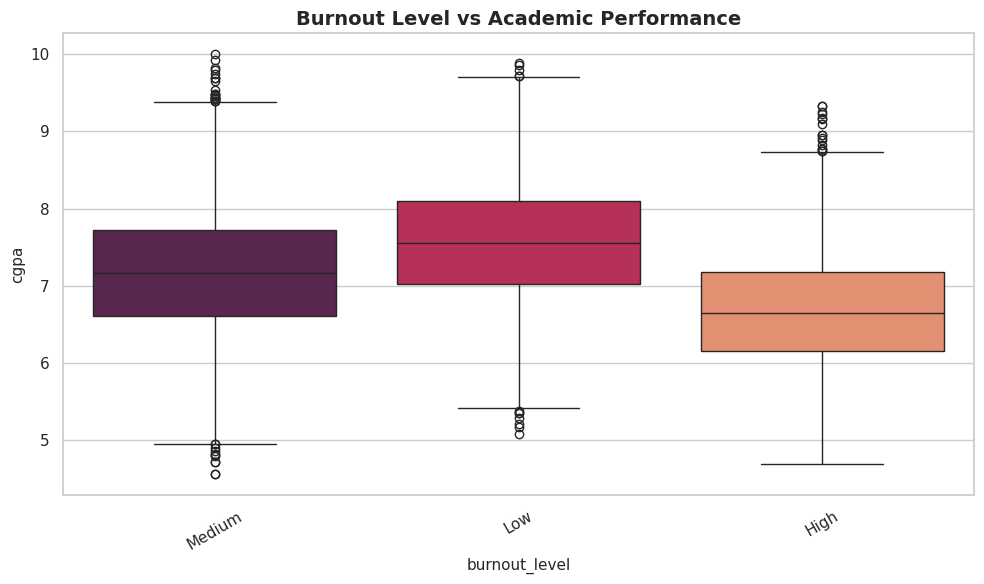

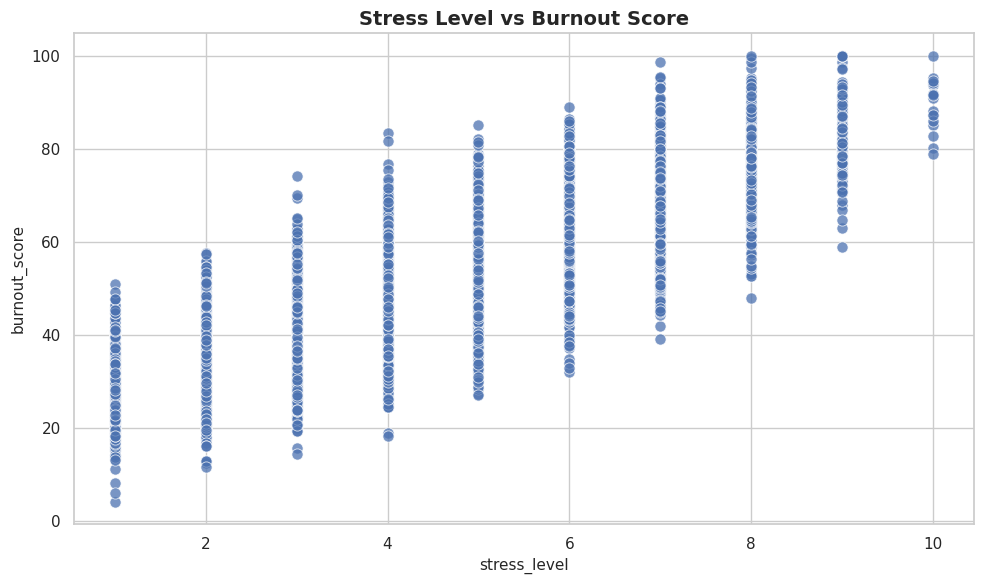

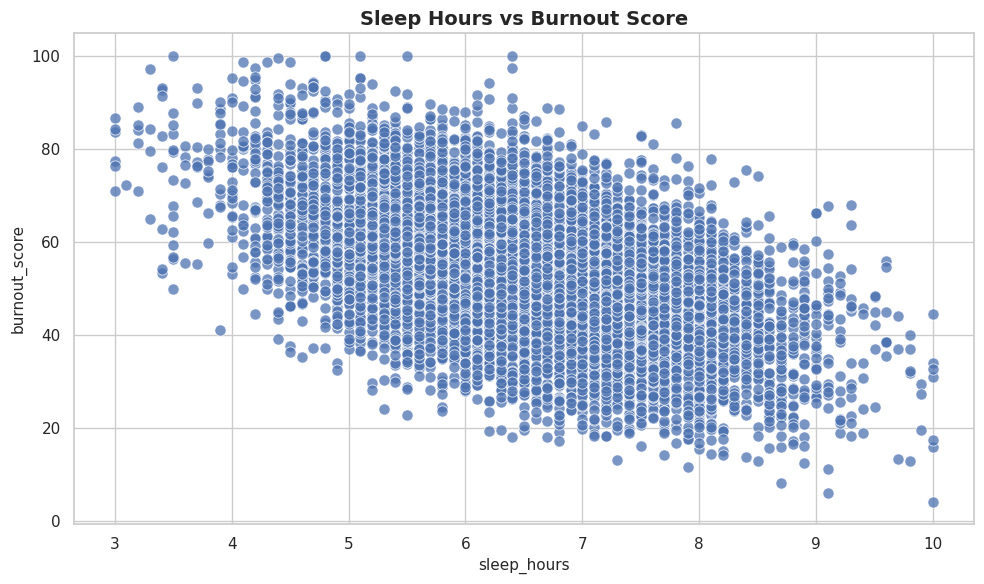

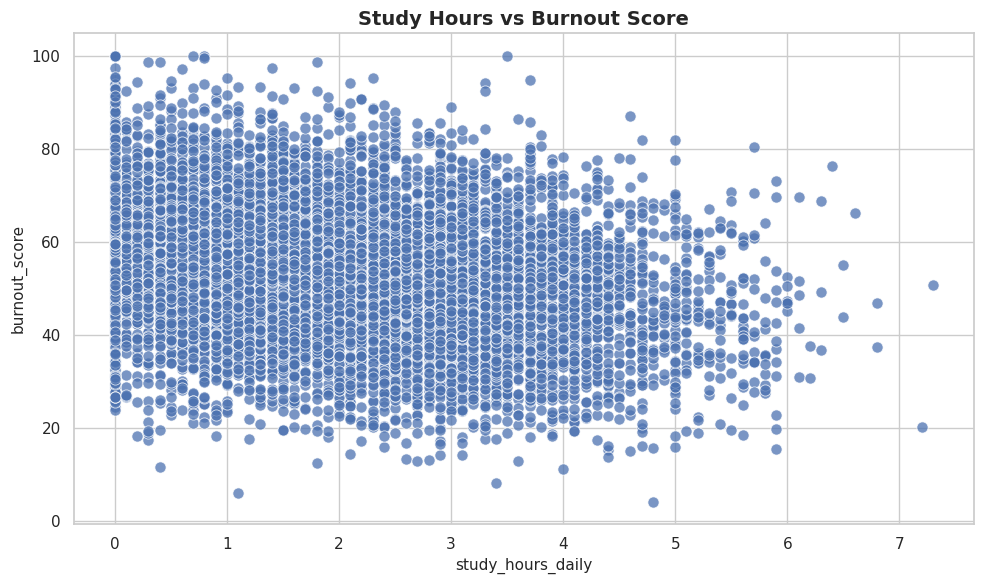

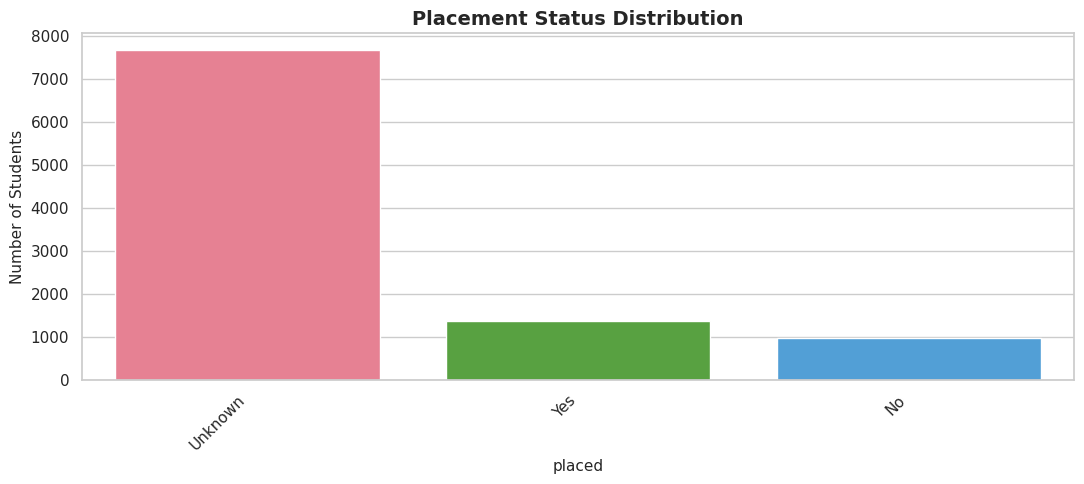

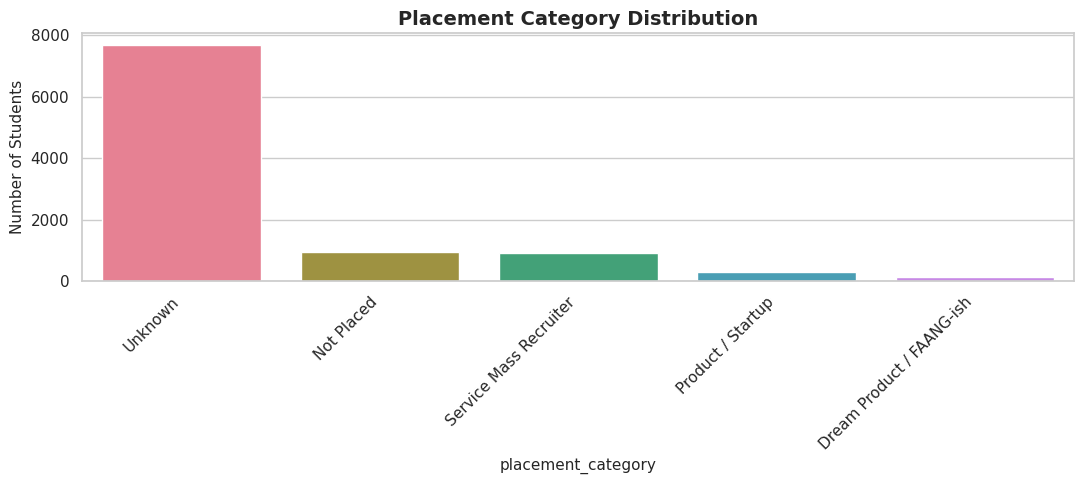

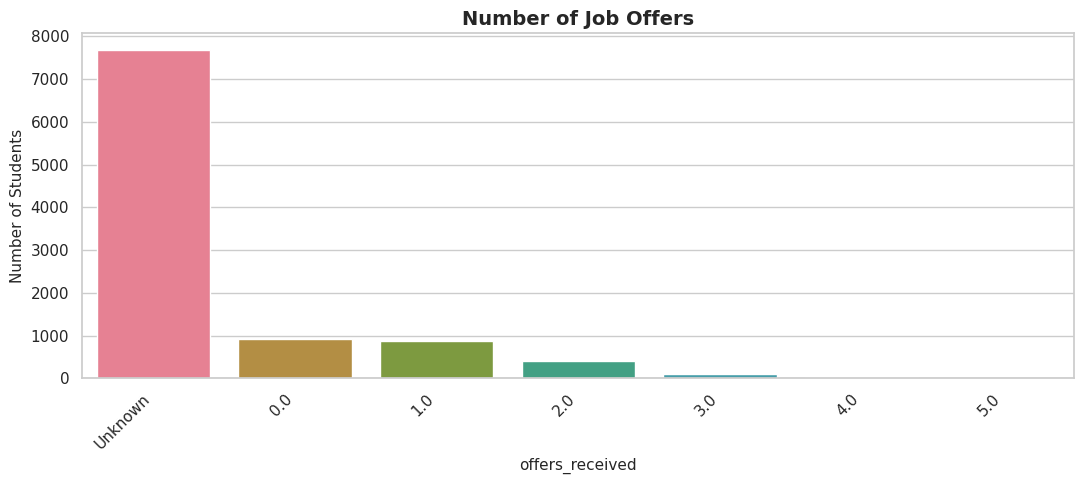

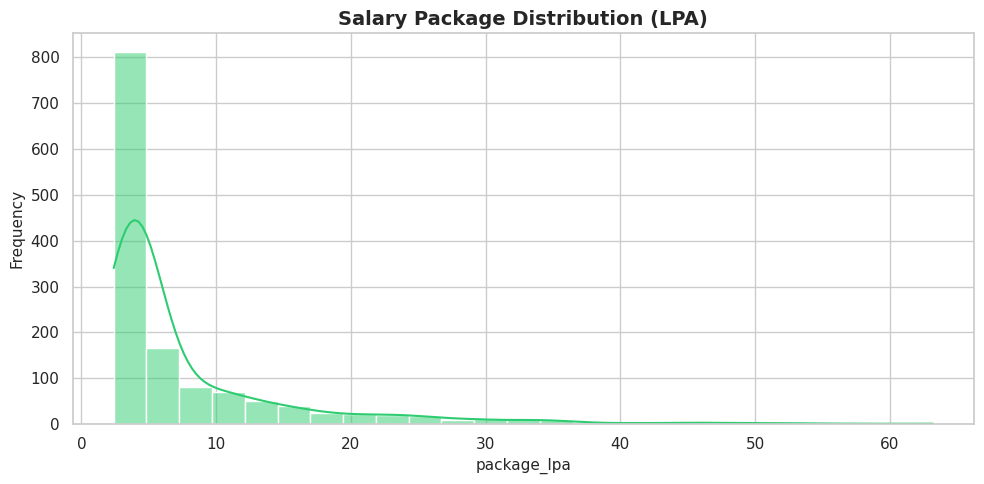

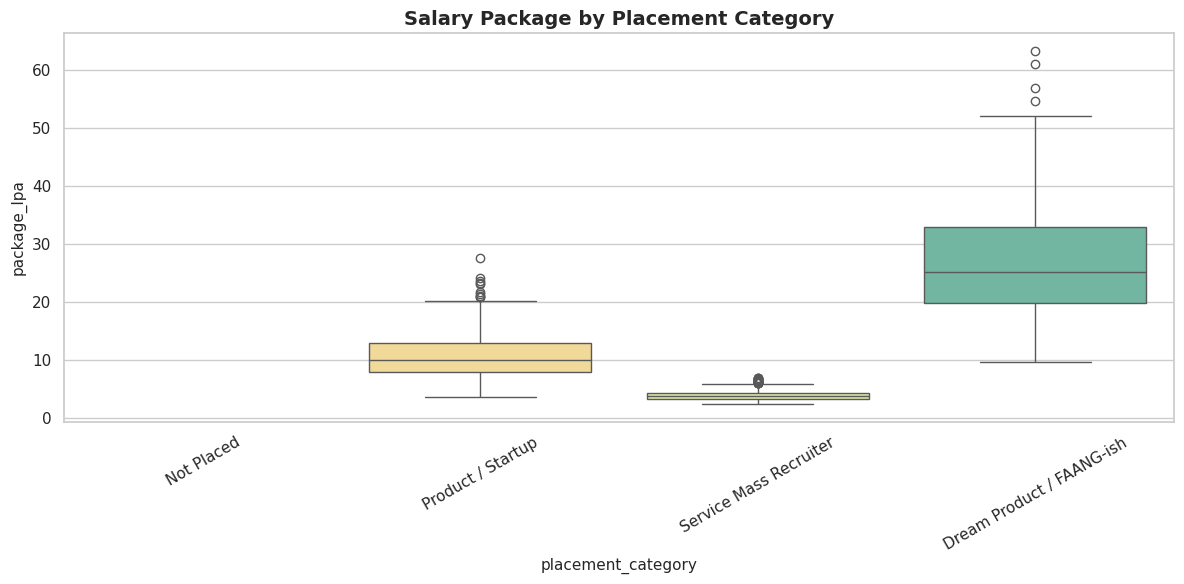

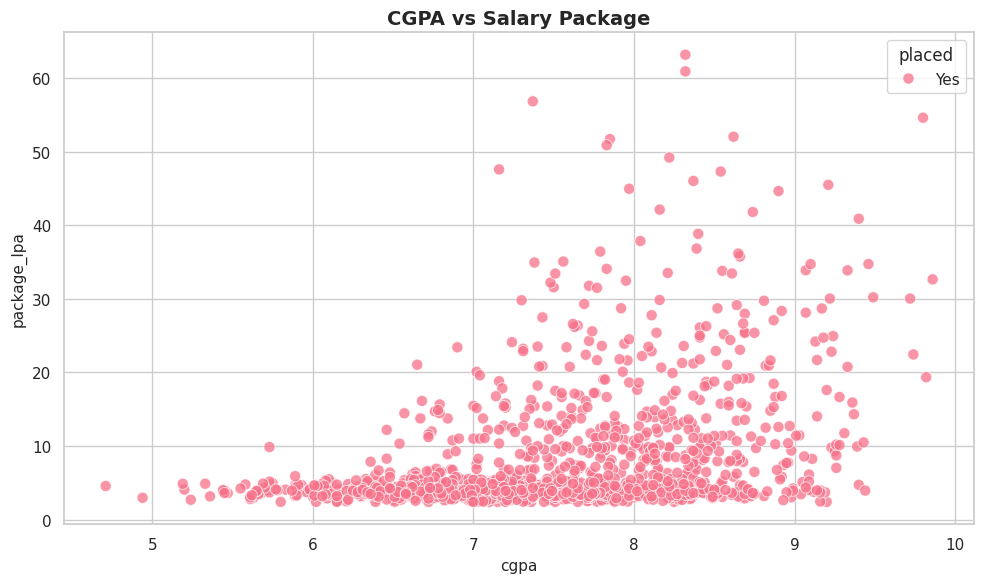

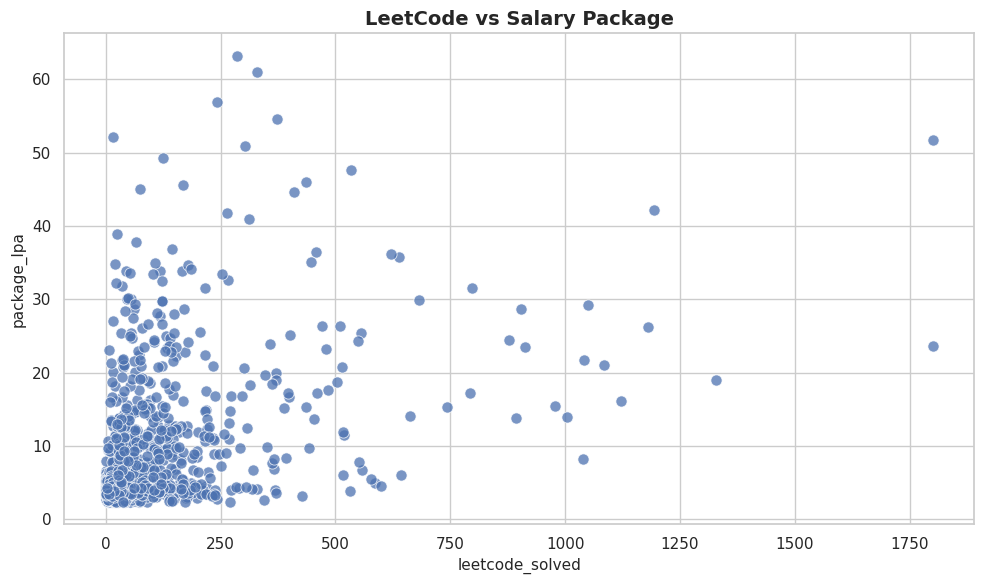

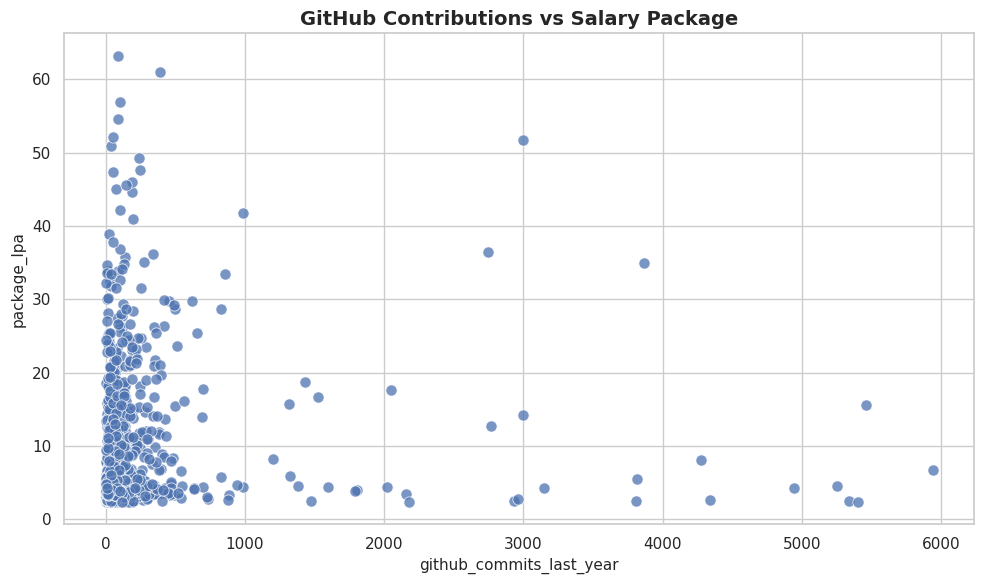

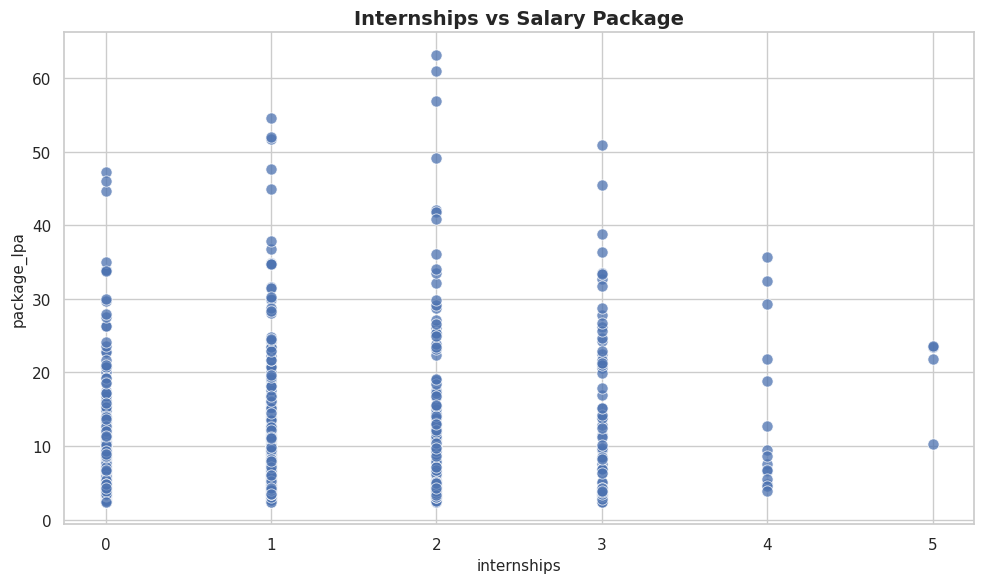

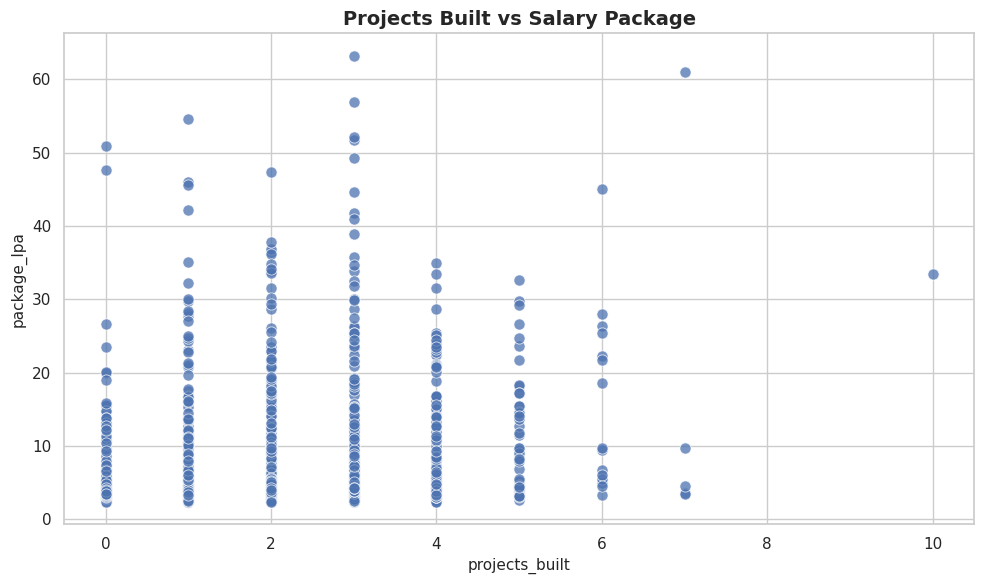

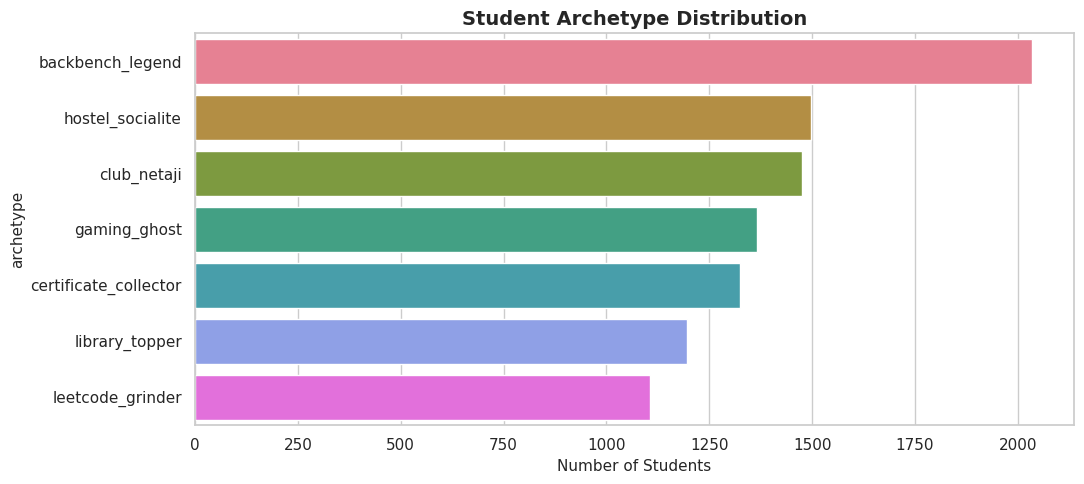

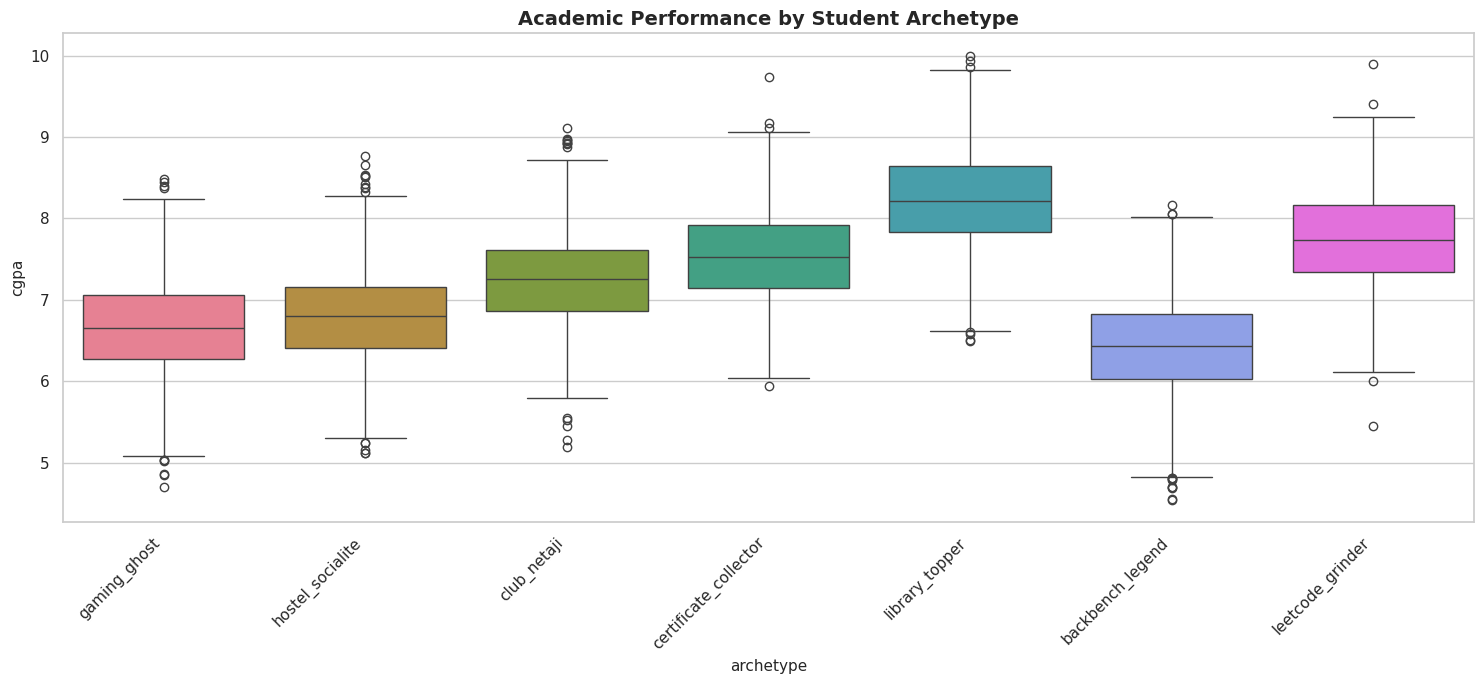

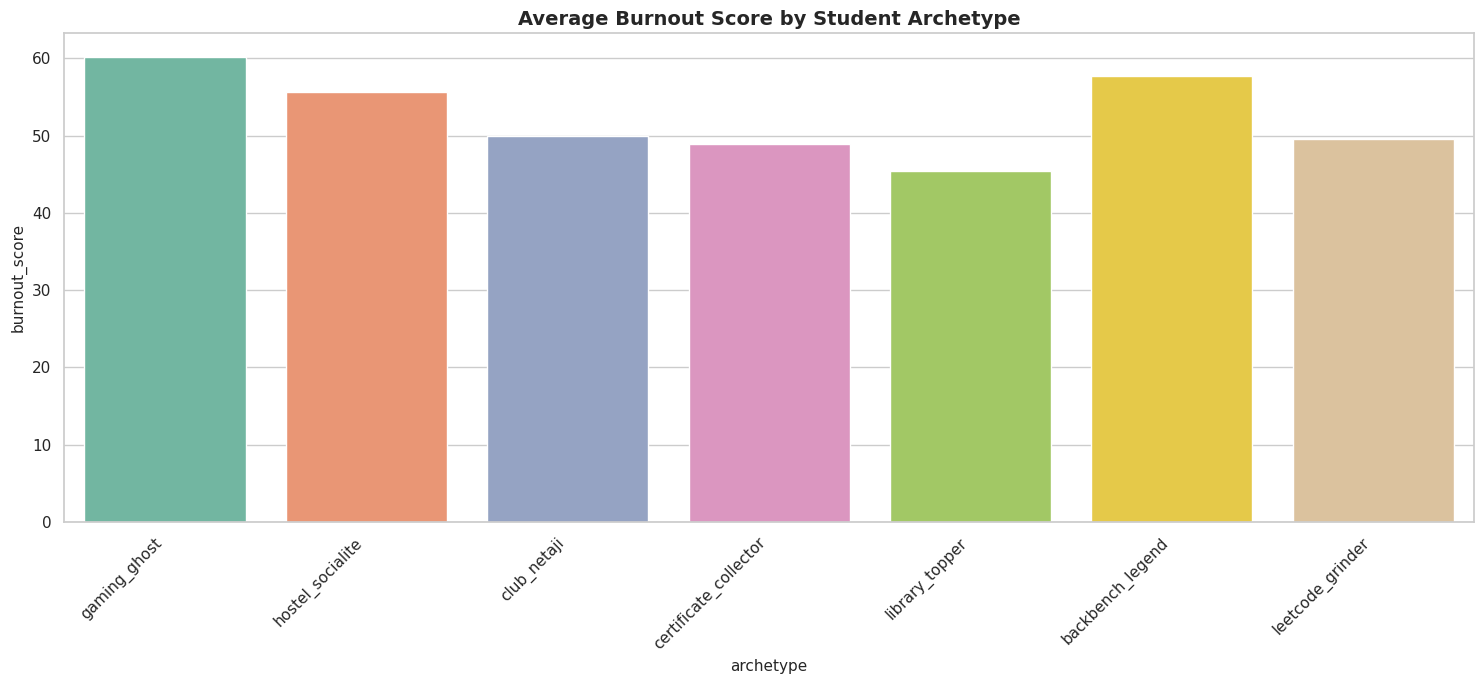

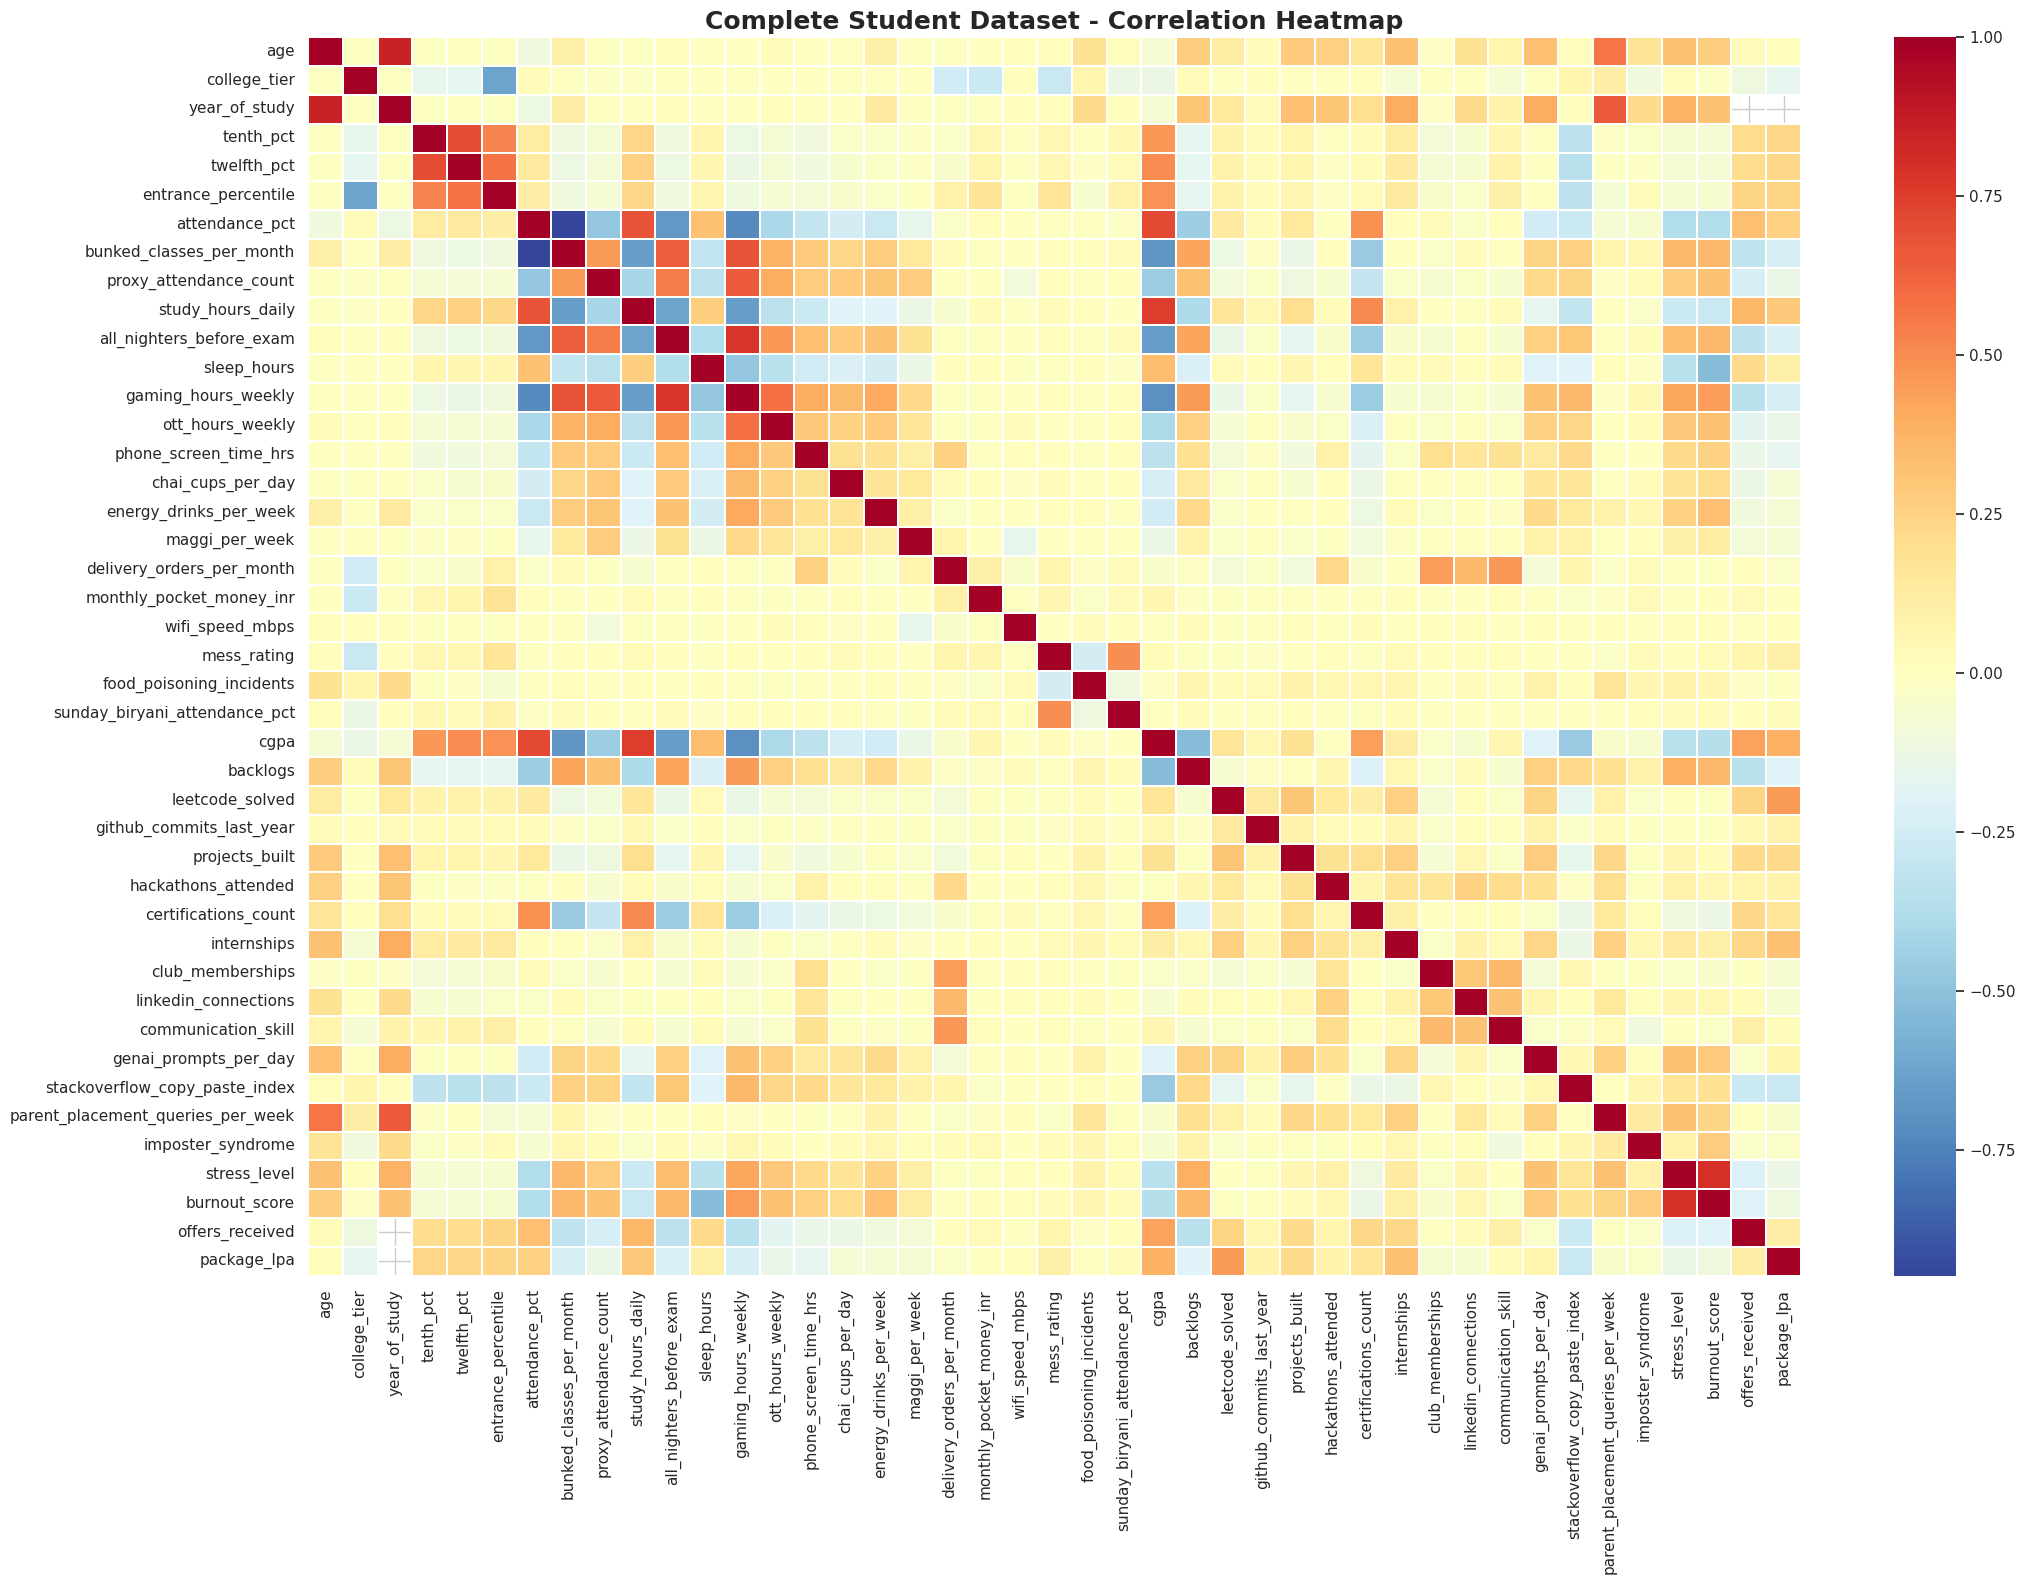

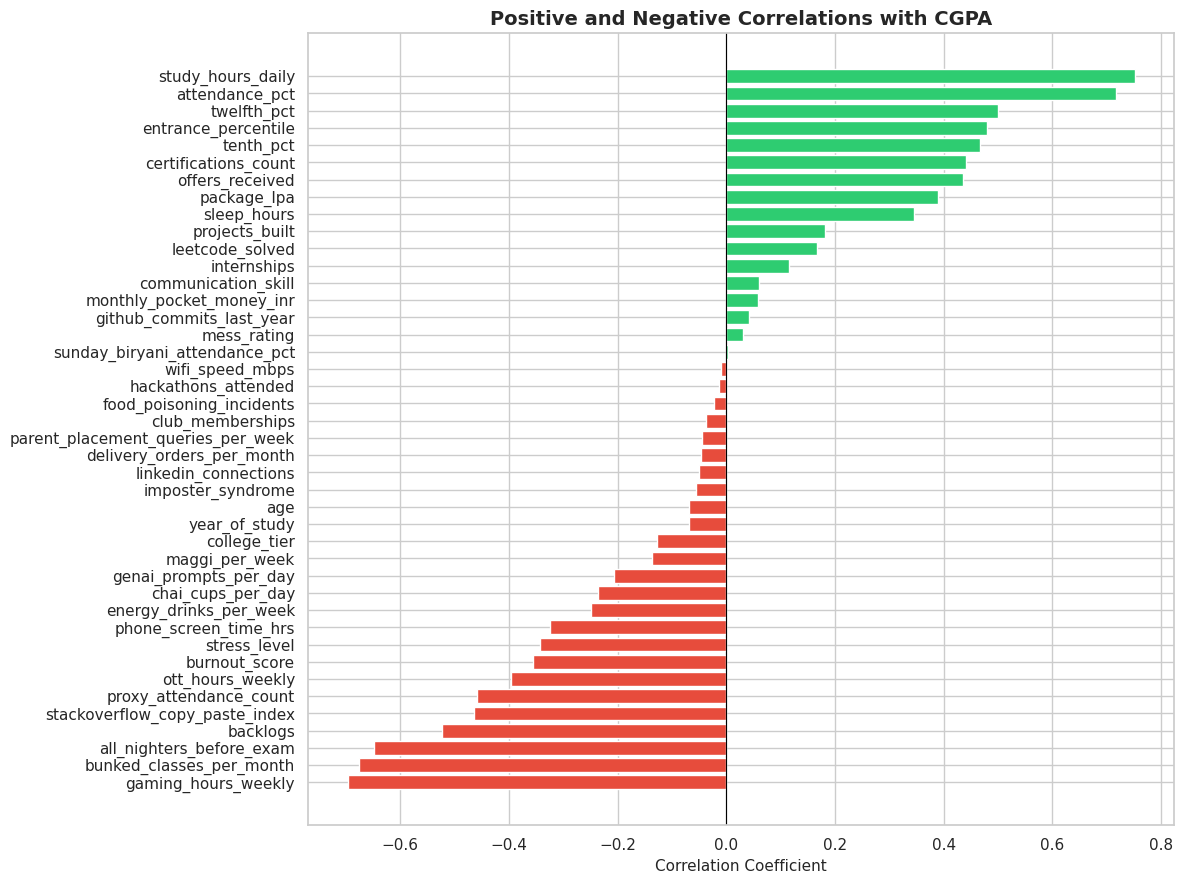

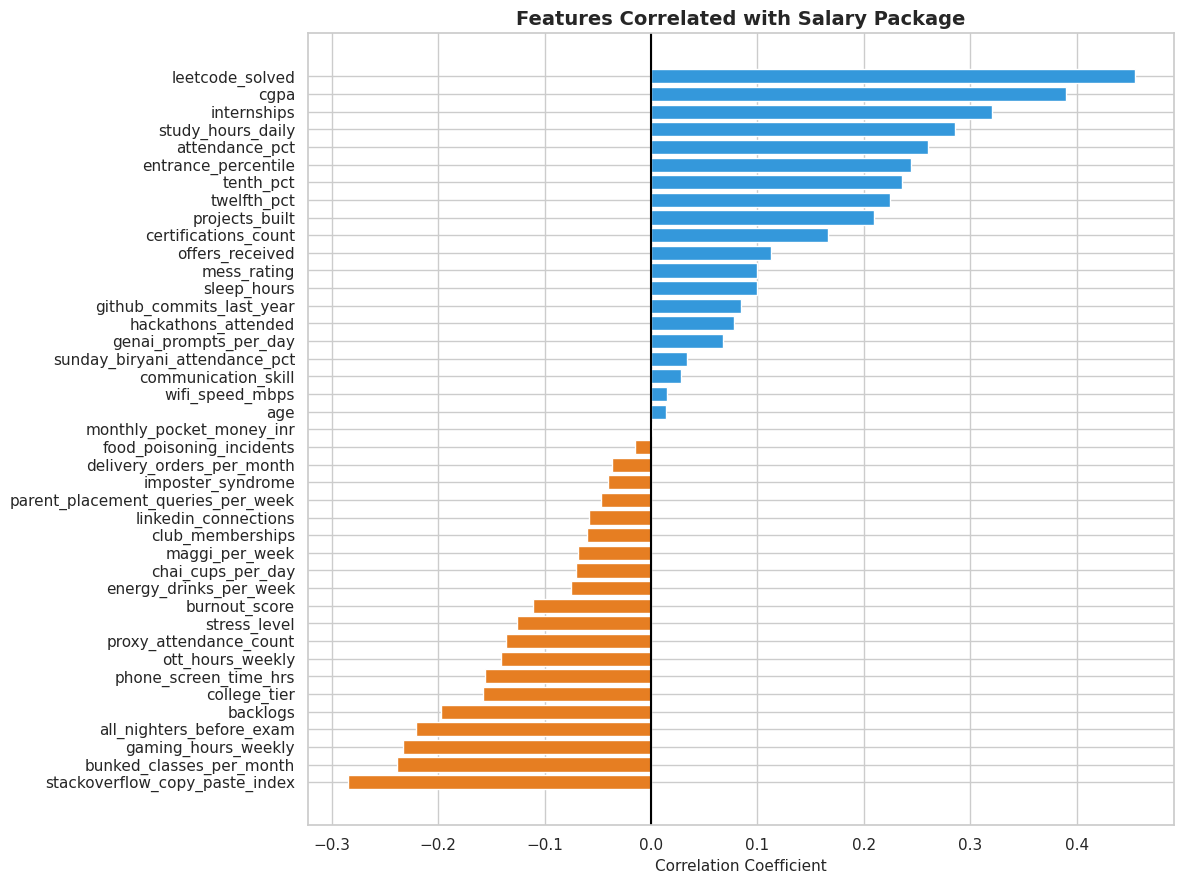


FINAL STUDENT ANALYTICS SUMMARY
Total Students: 10000
Average CGPA: 7.16
Maximum CGPA: 10.0
Average Attendance: 69.53 %
Average Daily Study Hours: 2.02
Average Burnout Score: 53.02
Average Package: 7.79 LPA

Placement Distribution:
placed
Yes    1357
No      958
Name: count, dtype: int64

Visualization Analysis Completed Successfully!


In [13]:

from matplotlib.ticker import MaxNLocator

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

sns.set_theme(style="whitegrid", context="notebook")

# Different color palettes
PALETTE = sns.color_palette("husl", 12)
COLORS = sns.color_palette("Set2", 12)
VIBRANT = sns.color_palette("Spectral", 12)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.facecolor"] = "white"

# Work on a copy
data = df.copy()

# Remove duplicate records
data = data.drop_duplicates()

# Remove student_id from numerical analysis
if "student_id" in data.columns:
    data["student_id"] = data["student_id"].astype(str)

# ------------------------------------------------
# 2. DATA PREPARATION
# ------------------------------------------------

numeric_cols = data.select_dtypes(include=np.number).columns.tolist()

categorical_cols = data.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Convert numeric-looking values where appropriate
for col in data.columns:
    if col not in ["student_id", "mess_review_text",
                   "reason_for_last_bunk", "archetype"]:
        if data[col].dtype == "object":
            converted = pd.to_numeric(data[col], errors="coerce")
            if converted.notna().sum() > 0.8 * data[col].notna().sum():
                data[col] = converted

numeric_cols = data.select_dtypes(include=np.number).columns.tolist()

def clean_plot():
    plt.tight_layout()
    plt.show()

def count_plot(column, title, top=15, horizontal=False):
    if column not in data.columns:
        return

    values = data[column].fillna("Unknown").astype(str).value_counts().head(top)

    plt.figure(figsize=(11, max(5, len(values) * 0.35)))

    if horizontal:
        sns.barplot(x=values.values, y=values.index, palette="husl")
        plt.xlabel("Number of Students")
        plt.ylabel(column)
    else:
        sns.barplot(x=values.index, y=values.values, palette="husl")
        plt.xticks(rotation=45, ha="right")
        plt.ylabel("Number of Students")

    plt.title(title)
    clean_plot()

def hist_plot(column, title, color):
    if column not in data.columns:
        return

    values = pd.to_numeric(data[column], errors="coerce").dropna()

    if values.empty:
        return

    plt.figure(figsize=(10, 5))
    sns.histplot(values, kde=True, color=color, bins=25)
    plt.title(title)
    plt.xlabel(column)
    plt.ylabel("Frequency")
    clean_plot()

def box_plot(column, title, color):
    if column not in data.columns:
        return

    values = pd.to_numeric(data[column], errors="coerce").dropna()

    if values.empty:
        return

    plt.figure(figsize=(10, 4))
    sns.boxplot(x=values, color=color)
    plt.title(title)
    clean_plot()

def scatter_plot(x, y, title, hue=None):
    if x not in data.columns or y not in data.columns:
        return

    cols = [x, y] + ([hue] if hue and hue in data.columns else [])
    plot_data = data[cols].copy()

    plot_data[x] = pd.to_numeric(plot_data[x], errors="coerce")
    plot_data[y] = pd.to_numeric(plot_data[y], errors="coerce")
    plot_data = plot_data.dropna(subset=[x, y])

    if len(plot_data) == 0:
        return

    plt.figure(figsize=(10, 6))

    sns.scatterplot(
        data=plot_data,
        x=x,
        y=y,
        hue=hue if hue in plot_data.columns else None,
        palette="husl",
        alpha=0.75,
        s=65
    )

    plt.title(title)
    clean_plot()

# ------------------------------------------------
# 3. DATASET OVERVIEW
# ------------------------------------------------

print("=" * 65)
print("STUDENT DATASET OVERVIEW")
print("=" * 65)

print("Dataset Shape:", data.shape)
print("\nMissing Values:")
print(data.isnull().sum().sort_values(ascending=False).head(15))

print("\nStatistical Summary:")
display(data.describe(include="all").T)

# ------------------------------------------------
# 4. MISSING VALUE VISUALIZATION
# ------------------------------------------------

plt.figure(figsize=(14, 6))

missing = data.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing):
    sns.barplot(
        x=missing.values,
        y=missing.index,
        palette="rocket"
    )
    plt.title("Missing Values Across Student Dataset")
    plt.xlabel("Missing Records")
    clean_plot()
else:
    print("No missing values found.")

# ------------------------------------------------
# 5. STUDENT DEMOGRAPHICS
# ------------------------------------------------

count_plot("gender", "Gender Distribution")
count_plot("home_region", "Student Home Region", horizontal=True)
count_plot("home_town_type", "Urban vs Rural Background")
count_plot("branch", "Engineering Branch Distribution", horizontal=True)
count_plot("college_tier", "College Tier Distribution")
count_plot("year_of_study", "Year of Study Distribution")
count_plot("residence", "Student Residence Distribution")
count_plot("relationship_status", "Relationship Status Distribution")

hist_plot("age", "Student Age Distribution", "#3498db")

# ------------------------------------------------
# 6. ACADEMIC PERFORMANCE
# ------------------------------------------------

academic_cols = [
    "tenth_pct",
    "twelfth_pct",
    "entrance_percentile",
    "attendance_pct",
    "study_hours_daily",
    "sleep_hours",
    "cgpa"
]

available_academic = [
    col for col in academic_cols if col in data.columns
]

if available_academic:
    data[available_academic].hist(
        figsize=(17, 12),
        bins=20,
        color="#48C9B0",
        edgecolor="black"
    )
    plt.suptitle("Academic Performance - Student Distribution",
                 fontsize=17, fontweight="bold")
    plt.tight_layout()
    plt.show()

hist_plot("cgpa", "CGPA Distribution", "#9b59b6")
hist_plot("tenth_pct", "10th Percentage Distribution", "#e67e22")
hist_plot("twelfth_pct", "12th Percentage Distribution", "#1abc9c")
hist_plot("entrance_percentile", "Entrance Percentile Distribution", "#3498db")
hist_plot("attendance_pct", "Attendance Percentage Distribution", "#2ecc71")

# CGPA by branch
if {"branch", "cgpa"}.issubset(data.columns):
    plt.figure(figsize=(14, 6))
    sns.boxplot(
        data=data,
        x="branch",
        y="cgpa",
        palette="Set3"
    )
    plt.title("CGPA Distribution Across Engineering Branches")
    plt.xticks(rotation=45)
    clean_plot()

# CGPA by college tier
if {"college_tier", "cgpa"}.issubset(data.columns):
    plt.figure(figsize=(10, 5))
    sns.violinplot(
        data=data,
        x="college_tier",
        y="cgpa",
        palette="husl",
        inner="quartile"
    )
    plt.title("CGPA Distribution by College Tier")
    clean_plot()

# Academic marks comparison
marks_cols = [
    c for c in ["tenth_pct", "twelfth_pct", "entrance_percentile"]
    if c in data.columns
]

if marks_cols:
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=data[marks_cols], palette="Set2")
    plt.title("Comparison of Previous Academic Performance")
    clean_plot()

# ------------------------------------------------
# 7. ATTENDANCE AND BUNKING ANALYSIS
# ------------------------------------------------

hist_plot("bunked_classes_per_month", "Monthly Bunked Classes", "#e74c3c")
hist_plot("proxy_attendance_count", "Proxy Attendance Distribution", "#8e44ad")

scatter_plot(
    "bunked_classes_per_month",
    "attendance_pct",
    "Bunking vs Attendance"
)

scatter_plot(
    "attendance_pct",
    "cgpa",
    "Attendance vs CGPA"
)

if {"reason_for_last_bunk", "cgpa"}.issubset(data.columns):
    count_plot(
        "reason_for_last_bunk",
        "Most Common Reasons for Bunking",
        horizontal=True
    )

# ------------------------------------------------
# 8. STUDENT LIFESTYLE ANALYSIS
# ------------------------------------------------

lifestyle_cols = [
    "study_hours_daily",
    "sleep_hours",
    "gaming_hours_weekly",
    "ott_hours_weekly",
    "phone_screen_time_hrs",
    "chai_cups_per_day",
    "energy_drinks_per_week",
    "maggi_per_week",
    "delivery_orders_per_month",
    "monthly_pocket_money_inr"
]

available_lifestyle = [
    c for c in lifestyle_cols if c in data.columns
]

for i, col in enumerate(available_lifestyle):
    hist_plot(
        col,
        f"Distribution of {col.replace('_', ' ').title()}",
        PALETTE[i % len(PALETTE)]
    )

# ------------------------------------------------
# 9. DIGITAL HABITS ANALYSIS
# ------------------------------------------------

digital_cols = [
    "gaming_hours_weekly",
    "ott_hours_weekly",
    "phone_screen_time_hrs",
    "genai_prompts_per_day",
    "stackoverflow_copy_paste_index"
]

available_digital = [
    c for c in digital_cols if c in data.columns
]

if available_digital:
    digital_corr = data[available_digital].corr()

    plt.figure(figsize=(11, 7))
    sns.heatmap(
        digital_corr,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5,
        center=0
    )
    plt.title("Digital Habits Correlation Heatmap")
    clean_plot()

scatter_plot(
    "phone_screen_time_hrs",
    "cgpa",
    "Phone Screen Time vs CGPA"
)

scatter_plot(
    "gaming_hours_weekly",
    "study_hours_daily",
    "Gaming vs Daily Study Hours"
)

scatter_plot(
    "sleep_hours",
    "cgpa",
    "Sleep Hours vs CGPA"
)

# ------------------------------------------------
# 10. FOOD AND COLLEGE MESS ANALYSIS
# ------------------------------------------------

food_cols = [
    "chai_cups_per_day",
    "energy_drinks_per_week",
    "maggi_per_week",
    "delivery_orders_per_month",
    "food_poisoning_incidents",
    "sunday_biryani_attendance_pct",
    "mess_rating"
]

available_food = [c for c in food_cols if c in data.columns]

if available_food:
    plt.figure(figsize=(14, 6))
    sns.heatmap(
        data[available_food].corr(),
        annot=True,
        cmap="YlOrRd",
        fmt=".2f",
        linewidths=0.5
    )
    plt.title("Food Habits and Mess Experience Correlation")
    clean_plot()

scatter_plot(
    "mess_rating",
    "food_poisoning_incidents",
    "Mess Rating vs Food Poisoning Incidents"
)

scatter_plot(
    "sunday_biryani_attendance_pct",
    "mess_rating",
    "Sunday Biryani Attendance vs Mess Rating"
)

# Most common mess reviews
count_plot("mess_review_text", "Common Mess Review Categories", top=12)

# ------------------------------------------------
# 11. CODING AND TECHNICAL SKILLS
# ------------------------------------------------

technical_cols = [
    "leetcode_solved",
    "github_commits_last_year",
    "projects_built",
    "hackathons_attended",
    "certifications_count",
    "internships",
    "club_memberships",
    "linkedin_connections",
    "genai_prompts_per_day"
]

available_technical = [
    c for c in technical_cols if c in data.columns
]

for i, col in enumerate(available_technical):
    hist_plot(
        col,
        f"{col.replace('_', ' ').title()} Distribution",
        PALETTE[i]
    )

scatter_plot(
    "leetcode_solved",
    "cgpa",
    "LeetCode Problems Solved vs CGPA"
)

scatter_plot(
    "github_commits_last_year",
    "projects_built",
    "GitHub Contributions vs Projects Built"
)

scatter_plot(
    "hackathons_attended",
    "projects_built",
    "Hackathons vs Projects Built"
)

scatter_plot(
    "certifications_count",
    "offers_received",
    "Certifications vs Job Offers"
)

# ------------------------------------------------
# 12. COMMUNICATION AND PERSONALITY
# ------------------------------------------------

hist_plot(
    "communication_skill",
    "Communication Skill Distribution",
    "#16a085"
)

count_plot(
    "uses_linux_btw",
    "Linux Usage Among Students"
)

count_plot(
    "owns_mechanical_keyboard",
    "Mechanical Keyboard Ownership"
)

count_plot(
    "imposter_syndrome",
    "Imposter Syndrome Distribution"
)

# ------------------------------------------------
# 13. STRESS AND BURNOUT ANALYSIS
# ------------------------------------------------

hist_plot("stress_level", "Student Stress Level Distribution", "#e74c3c")
hist_plot("burnout_score", "Burnout Score Distribution", "#8e44ad")

count_plot("burnout_level", "Burnout Level Distribution")

if {"burnout_level", "cgpa"}.issubset(data.columns):
    plt.figure(figsize=(10, 6))
    sns.boxplot(
        data=data,
        x="burnout_level",
        y="cgpa",
        palette="rocket"
    )
    plt.title("Burnout Level vs Academic Performance")
    plt.xticks(rotation=30)
    clean_plot()

scatter_plot(
    "stress_level",
    "burnout_score",
    "Stress Level vs Burnout Score"
)

scatter_plot(
    "sleep_hours",
    "burnout_score",
    "Sleep Hours vs Burnout Score"
)

scatter_plot(
    "study_hours_daily",
    "burnout_score",
    "Study Hours vs Burnout Score"
)

# ------------------------------------------------
# 14. PLACEMENT ANALYSIS
# ------------------------------------------------

count_plot("placed", "Placement Status Distribution")
count_plot("placement_category", "Placement Category Distribution")
count_plot("offers_received", "Number of Job Offers")

hist_plot("package_lpa", "Salary Package Distribution (LPA)", "#2ecc71")

if {"placement_category", "package_lpa"}.issubset(data.columns):
    plt.figure(figsize=(12, 6))
    sns.boxplot(
        data=data,
        x="placement_category",
        y="package_lpa",
        palette="Spectral"
    )
    plt.title("Salary Package by Placement Category")
    plt.xticks(rotation=30)
    clean_plot()

scatter_plot(
    "cgpa",
    "package_lpa",
    "CGPA vs Salary Package",
    hue="placed"
)

scatter_plot(
    "leetcode_solved",
    "package_lpa",
    "LeetCode vs Salary Package"
)

scatter_plot(
    "github_commits_last_year",
    "package_lpa",
    "GitHub Contributions vs Salary Package"
)

scatter_plot(
    "internships",
    "package_lpa",
    "Internships vs Salary Package"
)

scatter_plot(
    "projects_built",
    "package_lpa",
    "Projects Built vs Salary Package"
)

# ------------------------------------------------
# 15. STUDENT ARCHETYPE ANALYSIS
# ------------------------------------------------

count_plot(
    "archetype",
    "Student Archetype Distribution",
    horizontal=True
)

if {"archetype", "cgpa"}.issubset(data.columns):
    plt.figure(figsize=(15, 7))
    sns.boxplot(
        data=data,
        x="archetype",
        y="cgpa",
        palette="husl"
    )
    plt.title("Academic Performance by Student Archetype")
    plt.xticks(rotation=45, ha="right")
    clean_plot()

if {"archetype", "burnout_score"}.issubset(data.columns):
    plt.figure(figsize=(15, 7))
    sns.barplot(
        data=data,
        x="archetype",
        y="burnout_score",
        estimator="mean",
        errorbar=None,
        palette="Set2"
    )
    plt.title("Average Burnout Score by Student Archetype")
    plt.xticks(rotation=45, ha="right")
    clean_plot()

# ------------------------------------------------
# 16. COMPLETE NUMERICAL CORRELATION HEATMAP
# ------------------------------------------------

# Remove identifier-like columns
correlation_data = data.select_dtypes(include=np.number).copy()

correlation_data = correlation_data.drop(
    columns=[
        c for c in correlation_data.columns
        if c.lower().endswith("_id")
    ],
    errors="ignore"
)

if correlation_data.shape[1] > 1:

    plt.figure(figsize=(22, 16))

    corr = correlation_data.corr()

    sns.heatmap(
        corr,
        cmap="RdYlBu_r",
        center=0,
        annot=True if len(corr.columns) <= 18 else False,
        fmt=".2f",
        linewidths=0.3,
        square=False
    )

    plt.title(
        "Complete Student Dataset - Correlation Heatmap",
        fontsize=18,
        fontweight="bold"
    )

    clean_plot()

# ------------------------------------------------
# 17. TOP CORRELATIONS WITH CGPA
# ------------------------------------------------

if "cgpa" in correlation_data.columns:

    cgpa_corr = (
        correlation_data.corr()["cgpa"]
        .drop("cgpa")
        .dropna()
        .sort_values()
    )

    plt.figure(figsize=(12, 9))

    colors = [
        "#e74c3c" if x < 0 else "#2ecc71"
        for x in cgpa_corr.values
    ]

    plt.barh(cgpa_corr.index, cgpa_corr.values, color=colors)

    plt.axvline(0, color="black", linewidth=0.8)

    plt.title("Positive and Negative Correlations with CGPA")
    plt.xlabel("Correlation Coefficient")

    clean_plot()

# ------------------------------------------------
# 18. PLACEMENT CORRELATION
# ------------------------------------------------

if "package_lpa" in correlation_data.columns:

    package_corr = (
        correlation_data.corr()["package_lpa"]
        .drop("package_lpa")
        .dropna()
        .sort_values()
    )

    plt.figure(figsize=(12, 9))

    plt.barh(
        package_corr.index,
        package_corr.values,
        color=[
            "#3498db" if x >= 0 else "#e67e22"
            for x in package_corr.values
        ]
    )

    plt.axvline(0, color="black")
    plt.title("Features Correlated with Salary Package")
    plt.xlabel("Correlation Coefficient")

    clean_plot()

# ------------------------------------------------
# 19. FINAL STUDENT ANALYTICS SUMMARY
# ------------------------------------------------

print("\n" + "=" * 65)
print("FINAL STUDENT ANALYTICS SUMMARY")
print("=" * 65)

print("Total Students:", len(data))

if "cgpa" in data.columns:
    print("Average CGPA:", round(data["cgpa"].mean(), 2))
    print("Maximum CGPA:", round(data["cgpa"].max(), 2))

if "attendance_pct" in data.columns:
    print("Average Attendance:",
          round(data["attendance_pct"].mean(), 2), "%")

if "study_hours_daily" in data.columns:
    print("Average Daily Study Hours:",
          round(data["study_hours_daily"].mean(), 2))

if "burnout_score" in data.columns:
    print("Average Burnout Score:",
          round(data["burnout_score"].mean(), 2))

if "package_lpa" in data.columns:
    print("Average Package:",
          round(data["package_lpa"].mean(), 2), "LPA")

if "placed" in data.columns:
    print("\nPlacement Distribution:")
    print(data["placed"].value_counts())

print("\nVisualization Analysis Completed Successfully!")
print("=" * 65)


STUDENT PLACEMENT PREDICTION - MACHINE LEARNING
Original Shape: (10000, 59)

Target Classes:
0 = No
1 = Yes

Feature Shape: (2315, 50)
Target Shape: (2315,)

Numerical Features: 40
Categorical Features: 10

Numerical Columns:
['age', 'college_tier', 'tenth_pct', 'twelfth_pct', 'entrance_percentile', 'attendance_pct', 'bunked_classes_per_month', 'proxy_attendance_count', 'study_hours_daily', 'all_nighters_before_exam', 'sleep_hours', 'gaming_hours_weekly', 'ott_hours_weekly', 'phone_screen_time_hrs', 'chai_cups_per_day', 'energy_drinks_per_week', 'maggi_per_week', 'delivery_orders_per_month', 'monthly_pocket_money_inr', 'wifi_speed_mbps', 'mess_rating', 'food_poisoning_incidents', 'sunday_biryani_attendance_pct', 'cgpa', 'backlogs', 'leetcode_solved', 'github_commits_last_year', 'projects_built', 'hackathons_attended', 'certifications_count', 'internships', 'club_memberships', 'linkedin_connections', 'communication_skill', 'genai_prompts_per_day', 'stackoverflow_copy_paste_index', 'pare

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Gradient Boosting,75.81%,78.29%,81.18%,79.71%,0.8303
1,Logistic Regression,75.81%,82.72%,74.17%,78.21%,0.8273
2,XGBoost,74.30%,76.76%,80.44%,78.56%,0.8236
3,CatBoost,74.30%,76.76%,80.44%,78.56%,0.8228
4,Hist Gradient Boosting,74.73%,76.92%,81.18%,78.99%,0.8196
5,LightGBM,74.30%,76.57%,80.81%,78.64%,0.8152
6,Random Forest,73.00%,75.70%,79.34%,77.48%,0.8058
7,SVM,73.87%,79.30%,74.91%,77.04%,0.8049
8,Extra Trees,71.92%,75.27%,77.49%,76.36%,0.7954
9,Gaussian Naive Bayes,69.11%,75.40%,70.11%,72.66%,0.7771


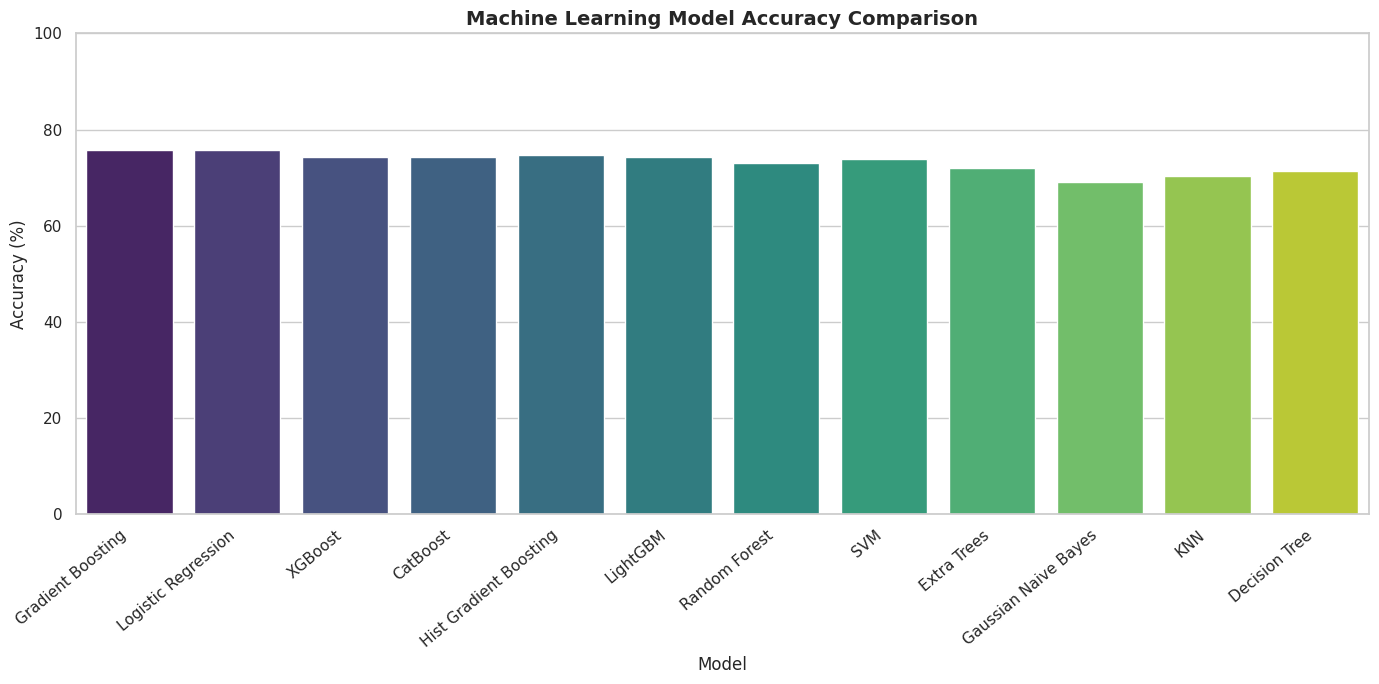

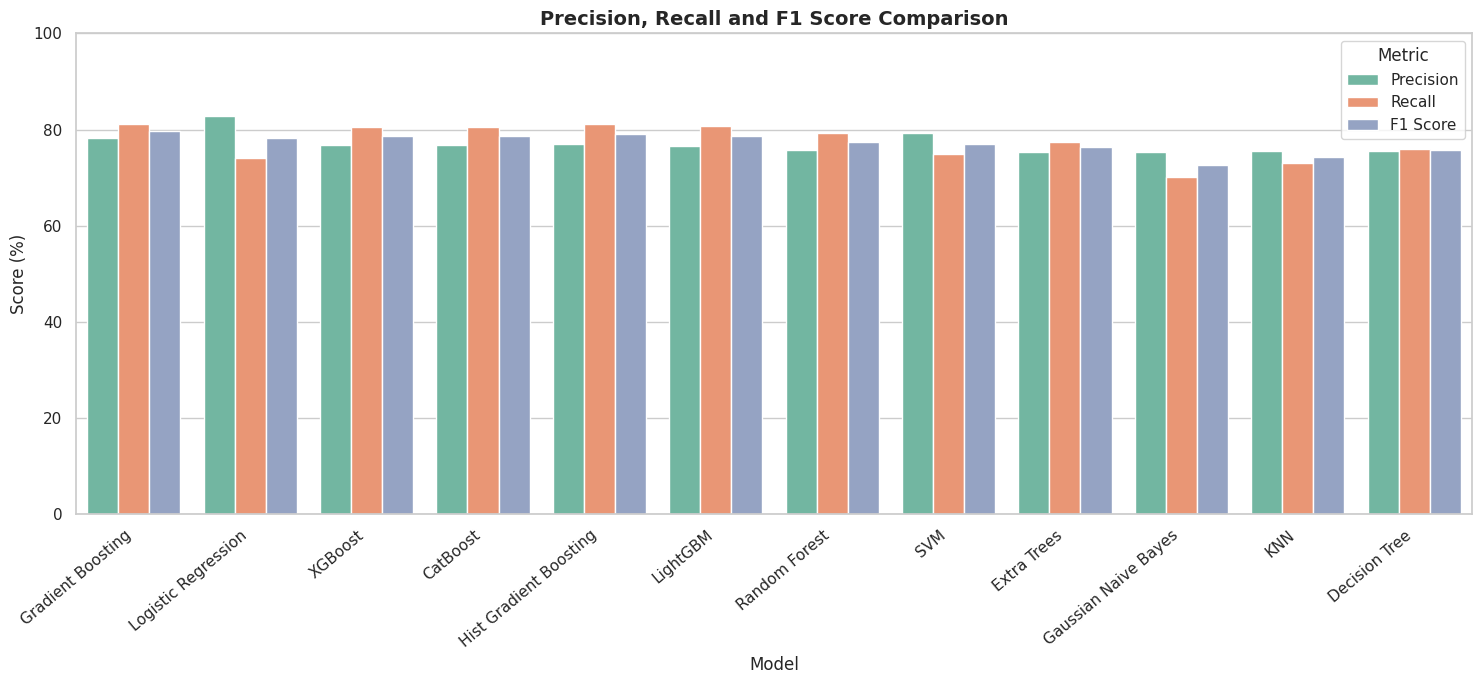

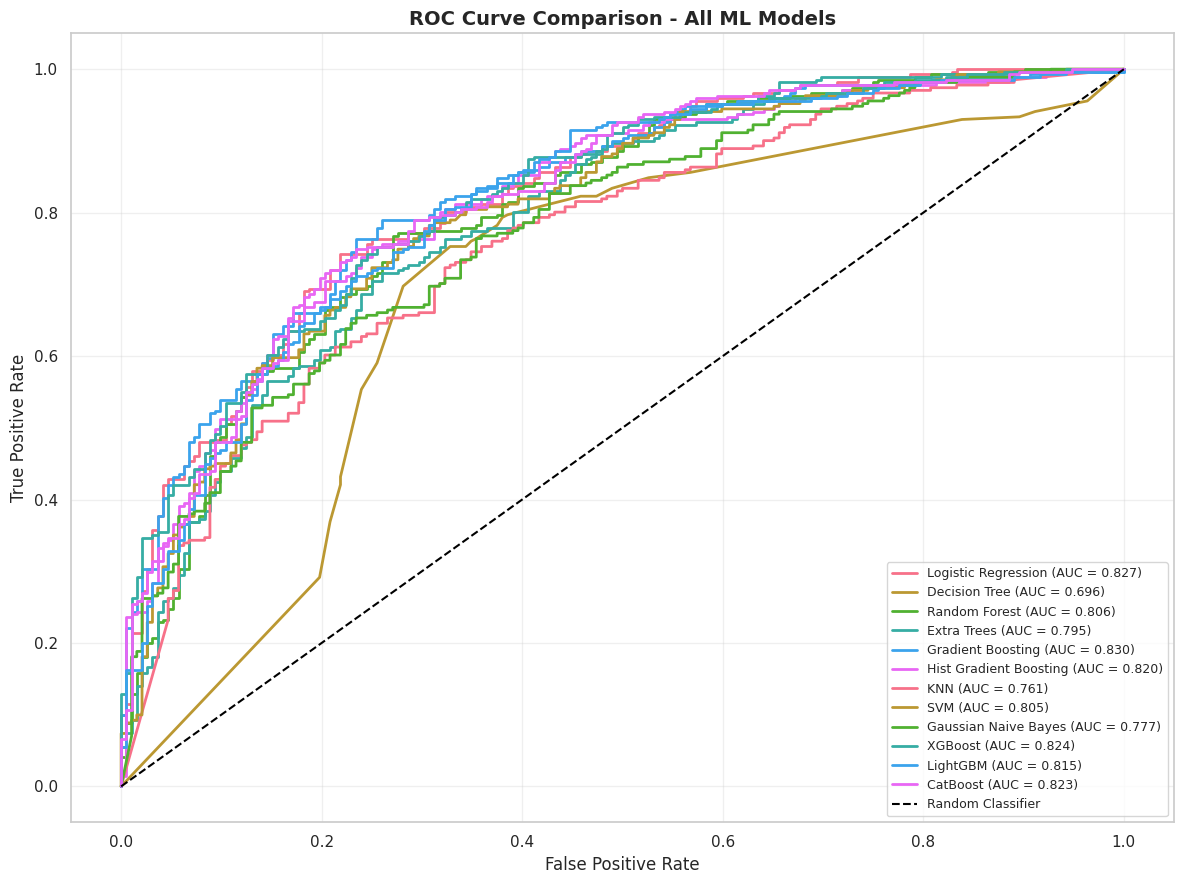

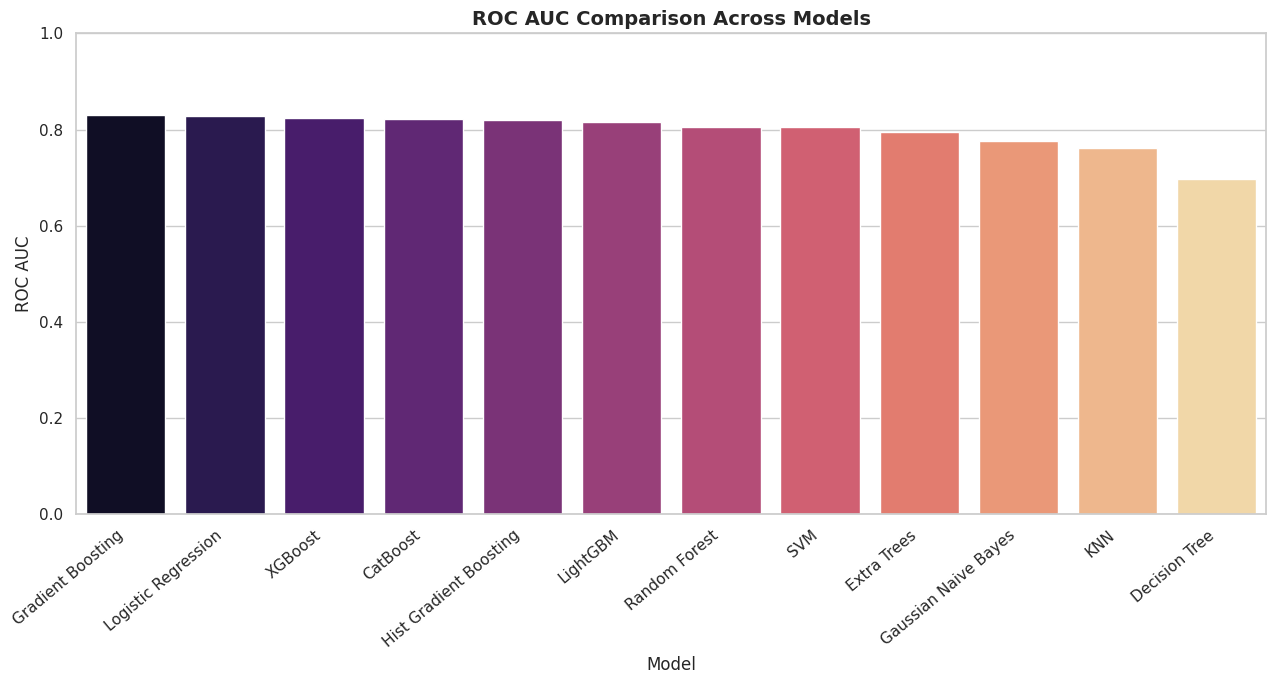


BEST MODEL: Gradient Boosting

Classification Report:
              precision    recall  f1-score   support

          No       0.72      0.68      0.70       192
         Yes       0.78      0.81      0.80       271

    accuracy                           0.76       463
   macro avg       0.75      0.75      0.75       463
weighted avg       0.76      0.76      0.76       463



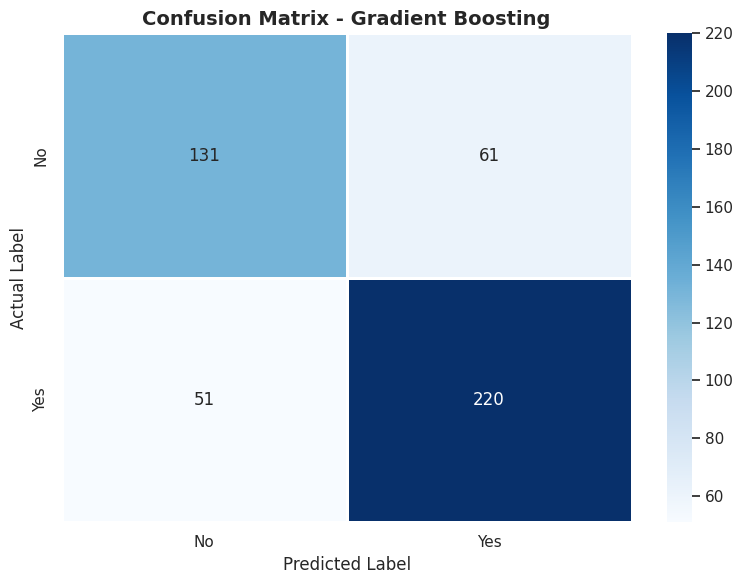

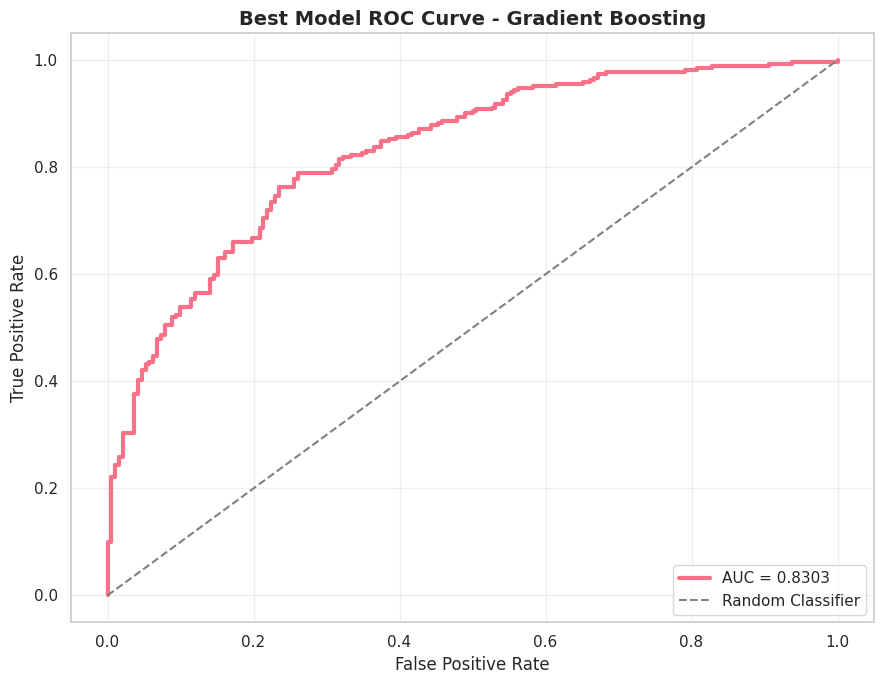


Calculating Feature Importance...

Top 20 Important Features:


,Feature,Importance,Std
32,leetcode_solved,0.048839,0.008707
31,backlogs,0.029278,0.006891
30,cgpa,0.028425,0.006855
10,entrance_percentile,0.013034,0.003099
37,internships,0.007388,0.001822
39,linkedin_connections,0.005408,0.001498
8,tenth_pct,0.005147,0.002752
14,study_hours_daily,0.004547,0.001740
11,attendance_pct,0.003125,0.004314
40,communication_skill,0.002864,0.001413


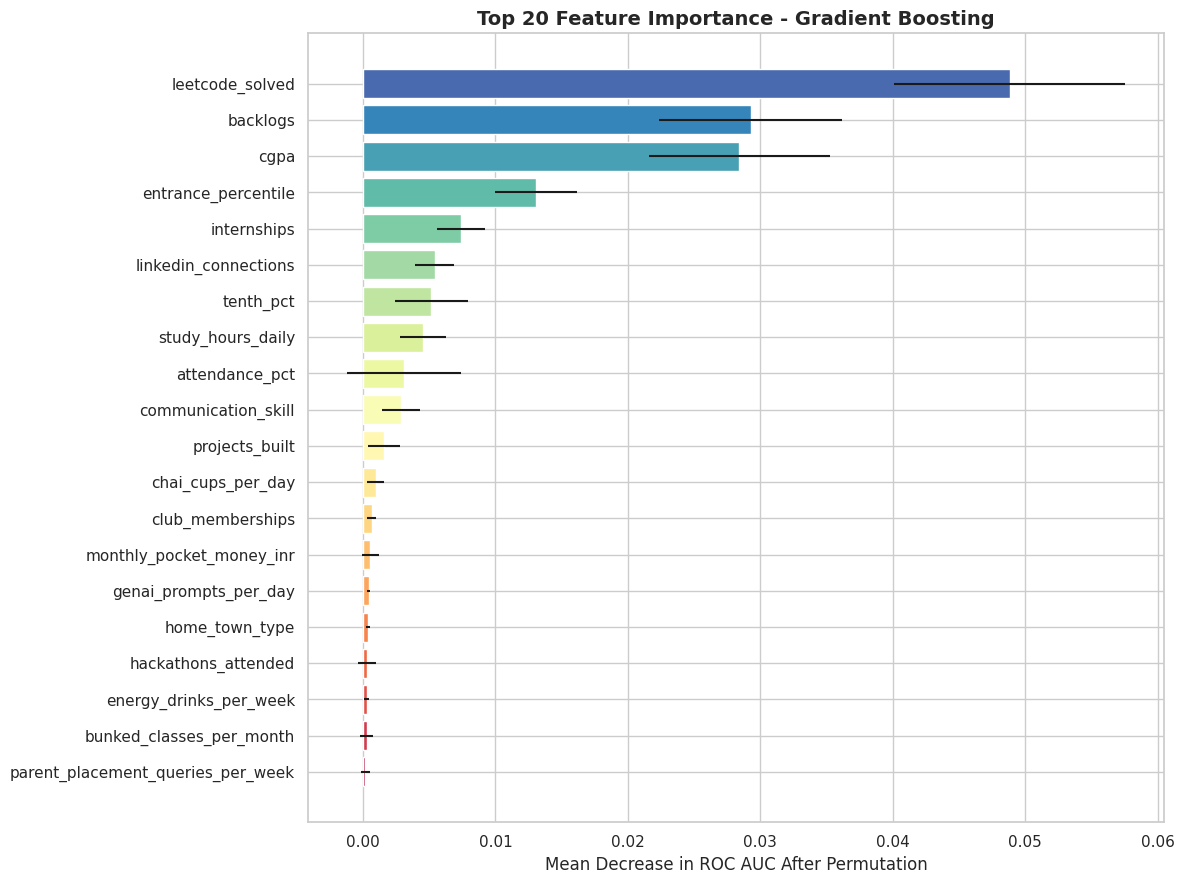


SAMPLE STUDENT PLACEMENT PREDICTION
Predicted Class: No
Predicted Probability of Positive Class: 49.34 %

Actual Class: No

Machine Learning Pipeline Completed Successfully!
Total Models Trained: 12
Best Model: Gradient Boosting


In [14]:

# ================================================================
# STUDENT PLACEMENT PREDICTION - COMPLETE MACHINE LEARNING PROJECT
# TRAIN TEST SPLIT + LABEL ENCODING + 12 ML MODELS + ROC CURVES
# ================================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

from sklearn.inspection import permutation_importance

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# ------------------------------------------------
# 1. VISUALIZATION SETTINGS
# ------------------------------------------------

sns.set_theme(style="whitegrid", palette="husl")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"

# ------------------------------------------------
# 2. LOAD AND CLEAN DATA
# ------------------------------------------------

data = df.copy()

print("=" * 70)
print("STUDENT PLACEMENT PREDICTION - MACHINE LEARNING")
print("=" * 70)

print("Original Shape:", data.shape)

data.drop_duplicates(inplace=True)

# Remove identifier
data.drop(
    columns=["student_id"],
    errors="ignore",
    inplace=True
)

# ------------------------------------------------
# 3. DEFINE TARGET VARIABLE
# ------------------------------------------------

TARGET = "placed"

if TARGET not in data.columns:
    raise ValueError("Target column 'placed' is not present in df.")

# Remove missing target records
data = data.dropna(subset=[TARGET]).copy()

# ------------------------------------------------
# 4. REMOVE DATA LEAKAGE
# ------------------------------------------------

# These columns may reveal placement outcomes directly
# or may be assigned after placement.

leakage_columns = [
    "placement_category",
    "offers_received",
    "package_lpa",
    "archetype"
]

data.drop(
    columns=leakage_columns,
    errors="ignore",
    inplace=True
)

# Free-text columns are excluded from this baseline model.
# They can be handled separately using NLP techniques.

text_columns = [
    "mess_review_text",
    "reason_for_last_bunk"
]

data.drop(
    columns=text_columns,
    errors="ignore",
    inplace=True
)

# ------------------------------------------------
# 5. SEPARATE FEATURES AND TARGET
# ------------------------------------------------

X = data.drop(columns=[TARGET]).copy()
y = data[TARGET].copy()

# Remove infinite values
X = X.replace([np.inf, -np.inf], np.nan)

# Remove completely empty columns
X = X.dropna(axis=1, how="all")

# Remove constant columns
constant_columns = [
    col for col in X.columns
    if X[col].nunique(dropna=True) <= 1
]

X.drop(columns=constant_columns, inplace=True)

# Convert numeric-looking object columns into numeric
for col in X.columns:
    if X[col].dtype == "object":
        converted = pd.to_numeric(X[col], errors="coerce")

        if converted.notna().sum() > 0.8 * X[col].notna().sum():
            X[col] = converted

# ------------------------------------------------
# 6. LABEL ENCODING TARGET
# ------------------------------------------------

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y.astype(str))

print("\nTarget Classes:")
for index, class_name in enumerate(label_encoder.classes_):
    print(index, "=", class_name)

if len(label_encoder.classes_) != 2:
    raise ValueError(
        "ROC classification code requires exactly 2 target classes."
    )

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

# ------------------------------------------------
# 7. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ------------------------------------------------

numeric_features = X.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nNumerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))

print("\nNumerical Columns:")
print(numeric_features)

print("\nCategorical Columns:")
print(categorical_features)

# ------------------------------------------------
# 8. TRAIN TEST SPLIT
# ------------------------------------------------

class_counts = pd.Series(y).value_counts()

if class_counts.min() < 2:
    raise ValueError(
        "Each target class needs at least 2 samples for stratified splitting."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nTraining Class Distribution:")
print(pd.Series(y_train).value_counts(normalize=True))

print("\nTesting Class Distribution:")
print(pd.Series(y_test).value_counts(normalize=True))

# ------------------------------------------------
# 9. PREPROCESSING PIPELINE
# ------------------------------------------------

# LabelEncoder is used for the target.
# OneHotEncoder is used for nominal categorical features
# to avoid introducing artificial category rankings.

try:
    categorical_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    categorical_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", categorical_encoder)
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# ------------------------------------------------
# 10. DEFINE MACHINE LEARNING MODELS
# ------------------------------------------------

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_split=5,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=5,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        max_depth=12,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.05,
        max_leaf_nodes=15,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=7,
        weights="distance"
    ),

    "SVM": SVC(
        kernel="rbf",
        C=1.0,
        probability=True,
        class_weight="balanced",
        random_state=42
    ),

    "Gaussian Naive Bayes": GaussianNB()
}

# ------------------------------------------------
# 11. OPTIONAL ADVANCED ML MODELS
# ------------------------------------------------

try:
    from xgboost import XGBClassifier

    models["XGBoost"] = XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

except ImportError:
    print("\nXGBoost is not installed. Skipping.")

try:
    from lightgbm import LGBMClassifier

    models["LightGBM"] = LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=7,
        verbosity=-1,
        random_state=42
    )

except ImportError:
    print("\nLightGBM is not installed. Skipping.")

try:
    from catboost import CatBoostClassifier

    models["CatBoost"] = CatBoostClassifier(
        iterations=200,
        depth=6,
        learning_rate=0.05,
        verbose=0,
        random_seed=42,
        allow_writing_files=False
    )

except ImportError:
    print("\nCatBoost is not installed. Skipping.")

# ------------------------------------------------
# 12. TRAIN ALL MODELS
# ------------------------------------------------

results = []
trained_models = {}
roc_data = {}

for name, algorithm in models.items():

    print("\n" + "=" * 60)
    print("Training:", name)
    print("=" * 60)

    try:

        pipeline = Pipeline(steps=[
            ("preprocessor", preprocessor),
            ("classifier", algorithm)
        ])

        # Train
        pipeline.fit(X_train, y_train)

        # Predict
        y_pred = pipeline.predict(X_test)

        # Prediction probabilities
        if hasattr(pipeline, "predict_proba"):
            y_prob = pipeline.predict_proba(X_test)[:, 1]

        else:
            scores = pipeline.decision_function(X_test)

            # Scale decision scores to [0, 1] for plotting
            y_prob = (
                scores - scores.min()
            ) / (
                scores.max() - scores.min() + 1e-10
            )

        # Evaluation metrics
        accuracy = accuracy_score(y_test, y_pred)

        precision = precision_score(
            y_test, y_pred, zero_division=0
        )

        recall = recall_score(
            y_test, y_pred, zero_division=0
        )

        f1 = f1_score(
            y_test, y_pred, zero_division=0
        )

        auc = roc_auc_score(y_test, y_prob)

        results.append({
            "Model": name,
            "Accuracy": accuracy * 100,
            "Precision": precision * 100,
            "Recall": recall * 100,
            "F1 Score": f1 * 100,
            "ROC AUC": auc
        })

        trained_models[name] = pipeline

        fpr, tpr, thresholds = roc_curve(
            y_test, y_prob
        )

        roc_data[name] = {
            "fpr": fpr,
            "tpr": tpr,
            "auc": auc
        }

        print("Accuracy :", round(accuracy * 100, 2), "%")
        print("Precision:", round(precision * 100, 2), "%")
        print("Recall   :", round(recall * 100, 2), "%")
        print("F1 Score :", round(f1 * 100, 2), "%")
        print("ROC AUC  :", round(auc, 4))

    except Exception as e:
        print("Model failed:", name)
        print("Reason:", str(e)[:500])

# ------------------------------------------------
# 13. MODEL COMPARISON TABLE
# ------------------------------------------------

results_df = pd.DataFrame(results)

if results_df.empty:
    raise RuntimeError("No models trained successfully.")

results_df = results_df.sort_values(
    by="ROC AUC",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)

display(
    results_df.style
    .format({
        "Accuracy": "{:.2f}%",
        "Precision": "{:.2f}%",
        "Recall": "{:.2f}%",
        "F1 Score": "{:.2f}%",
        "ROC AUC": "{:.4f}"
    })
    .background_gradient(cmap="YlGnBu")
)

# ------------------------------------------------
# 14. MODEL ACCURACY COMPARISON
# ------------------------------------------------

plt.figure(figsize=(14, 7))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy",
    palette="viridis"
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=40, ha="right")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 15. PRECISION, RECALL AND F1 COMPARISON
# ------------------------------------------------

metric_data = results_df.melt(
    id_vars="Model",
    value_vars=["Precision", "Recall", "F1 Score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(15, 7))

sns.barplot(
    data=metric_data,
    x="Model",
    y="Score",
    hue="Metric",
    palette="Set2"
)

plt.title("Precision, Recall and F1 Score Comparison")
plt.ylabel("Score (%)")
plt.xticks(rotation=40, ha="right")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 16. ROC CURVE - ALL MODELS
# ------------------------------------------------

plt.figure(figsize=(12, 9))

for name, values in roc_data.items():

    plt.plot(
        values["fpr"],
        values["tpr"],
        linewidth=2,
        label=f'{name} (AUC = {values["auc"]:.3f})'
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison - All ML Models")

plt.legend(
    loc="lower right",
    fontsize=9
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 17. ROC AUC COMPARISON
# ------------------------------------------------

plt.figure(figsize=(13, 7))

sns.barplot(
    data=results_df,
    x="Model",
    y="ROC AUC",
    palette="magma"
)

plt.title("ROC AUC Comparison Across Models")
plt.ylabel("ROC AUC")
plt.xticks(rotation=40, ha="right")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 18. BEST MODEL SELECTION
# ------------------------------------------------

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("\n" + "=" * 70)
print("BEST MODEL:", best_model_name)
print("=" * 70)

best_predictions = best_model.predict(X_test)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        best_predictions,
        labels=[0, 1],
        target_names=[
            str(label_encoder.classes_[0]),
            str(label_encoder.classes_[1])
        ],
        zero_division=0
    )
)

# ------------------------------------------------
# 19. CONFUSION MATRIX
# ------------------------------------------------

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 20. BEST MODEL ROC CURVE
# ------------------------------------------------

best_roc = roc_data[best_model_name]

plt.figure(figsize=(9, 7))

plt.plot(
    best_roc["fpr"],
    best_roc["tpr"],
    linewidth=3,
    label=f'AUC = {best_roc["auc"]:.4f}'
)

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(f"Best Model ROC Curve - {best_model_name}")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 21. FEATURE IMPORTANCE USING PERMUTATION
# ------------------------------------------------

print("\nCalculating Feature Importance...")

try:

    importance = permutation_importance(
        best_model,
        X_test,
        y_test,
        scoring="roc_auc",
        n_repeats=5,
        random_state=42,
        n_jobs=-1
    )

    importance_df = pd.DataFrame({
        "Feature": X_test.columns,
        "Importance": importance.importances_mean,
        "Std": importance.importances_std
    }).sort_values(
        by="Importance",
        ascending=False
    )

    print("\nTop 20 Important Features:")

    display(importance_df.head(20))

    plt.figure(figsize=(12, 9))

    top_features = importance_df.head(20).sort_values(
        by="Importance"
    )

    plt.barh(
        top_features["Feature"],
        top_features["Importance"],
        xerr=top_features["Std"],
        color=sns.color_palette(
            "Spectral",
            len(top_features)
        )
    )

    plt.title(
        f"Top 20 Feature Importance - {best_model_name}"
    )

    plt.xlabel("Mean Decrease in ROC AUC After Permutation")

    plt.tight_layout()
    plt.show()

except Exception as e:
    print("Feature importance could not be calculated:", e)

# ------------------------------------------------
# 22. FINAL PREDICTION EXAMPLE
# ------------------------------------------------

sample = X_test.iloc[[0]]

prediction = best_model.predict(sample)[0]

if hasattr(best_model, "predict_proba"):
    probability = best_model.predict_proba(sample)[0][1]
else:
    probability = None

print("\n" + "=" * 70)
print("SAMPLE STUDENT PLACEMENT PREDICTION")
print("=" * 70)

print("Predicted Class:", label_encoder.inverse_transform([prediction])[0])

if probability is not None:
    print(
        "Predicted Probability of Positive Class:",
        round(probability * 100, 2), "%"
    )

print("\nActual Class:",
      label_encoder.inverse_transform([y_test[0]])[0])

print("\nMachine Learning Pipeline Completed Successfully!")
print("Total Models Trained:", len(trained_models))
print("Best Model:", best_model_name)

print("=" * 70)
